# Waste Material Image Classification — Archived Team Experiment

This notebook preserves the team coursework code and experiment outputs. Large repetitive embedded Grad-CAM galleries were removed for repository viewing; curated original output visuals appear in `figures/`. No model was retrained for repository preparation. The dataset folder `trash_images/` is not distributed.


# Data Prepocessing

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Seed digunakan agar hasil splitting, shuffle, dan training lebih konsisten setiap kali notebook dijalankan

In [3]:
dataset_dir = Path("trash_images")

print("Folder dataset:", dataset_dir)

Folder dataset: trash_images


In [4]:
from pathlib import Path

possible_dirs = [
    Path("trash_images"),
    Path("../trash_images"),
    Path("../../trash_images"),
    Path("data/trash_images"),
    Path("../data/trash_images")
]

dataset_dir = None

for path in possible_dirs:
    if path.exists():
        dataset_dir = path
        break

if dataset_dir is None:
    print("Folder dataset tidak ditemukan.")
    print("Cek lokasi notebook dan lokasi folder trash_images.")
else:
    print("Folder dataset ditemukan:", dataset_dir)
    print("Isi folder utama:")
    for item in dataset_dir.iterdir():
        print(item.name)

Folder dataset ditemukan: trash_images
Isi folder utama:
cardboard
glass
metal
paper
plastic
trash


In [5]:
print("Folder dataset:", dataset_dir)
print("Isi folder utama:")

for item in dataset_dir.iterdir():
    print(item.name)

Folder dataset: trash_images
Isi folder utama:
cardboard
glass
metal
paper
plastic
trash


In [6]:
image_paths = []
labels = []

valid_extensions = [".jpg", ".jpeg", ".png"]

for class_folder in dataset_dir.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name
        
        for image_file in class_folder.iterdir():
            if image_file.suffix.lower() in valid_extensions:
                image_paths.append(str(image_file))
                labels.append(class_name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df.head()

,image_path,label
0,trash_images\cardboard\cardboard_001.jpg,cardboard
1,trash_images\cardboard\cardboard_002.jpg,cardboard
2,trash_images\cardboard\cardboard_003.jpg,cardboard
3,trash_images\cardboard\cardboard_004.jpg,cardboard
4,trash_images\cardboard\cardboard_005.jpg,cardboard


In [7]:
print("Total gambar:", len(df))
print("Jumlah kelas:", df["label"].nunique())
print("Nama kelas:", sorted(df["label"].unique()))

Total gambar: 2527
Jumlah kelas: 6
Nama kelas: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Kode ini digunakan untuk memastikan jumlah total gambar dan jumlah kelas. Untuk dataset ini, kelasnya adalah:

cardboard, glass, metal, paper, plastic, trash

Karena jumlah kelas lebih dari 2 dan setiap gambar hanya punya satu label, maka problem ini termasuk multi-class image classification.

label
paper        594
glass        501
plastic      482
metal        410
cardboard    403
trash        137
Name: count, dtype: int64


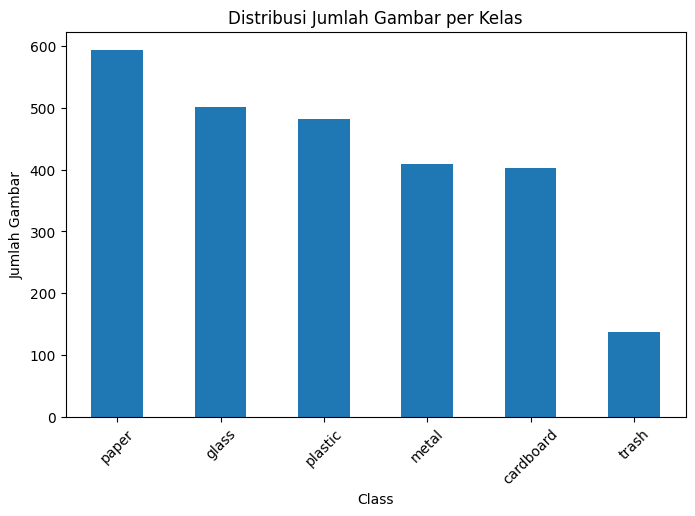

In [8]:
class_distribution = df["label"].value_counts()
print(class_distribution)

plt.figure(figsize=(8, 5))
class_distribution.plot(kind="bar")
plt.title("Distribusi Jumlah Gambar per Kelas")
plt.xlabel("Class")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.show()

Bagian ini mengecek apakah dataset seimbang atau tidak. Pada dataset ini, kelas seperti paper, glass, dan plastic memiliki jumlah gambar lebih banyak, sedangkan kelas trash jauh lebih sedikit.

Ini menunjukkan adanya class imbalance. Dampaknya, model bisa cenderung lebih bagus memprediksi kelas mayoritas dan lebih lemah pada kelas minoritas.

In [9]:
class_names = sorted(df["label"].unique())

class_to_index = {
    class_name: index for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name for class_name, index in class_to_index.items()
}

df["label_index"] = df["label"].map(class_to_index)

print("Class to index:")
print(class_to_index)

df.head()

Class to index:
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


,image_path,label,label_index
0,trash_images\cardboard\cardboard_001.jpg,cardboard,0
1,trash_images\cardboard\cardboard_002.jpg,cardboard,0
2,trash_images\cardboard\cardboard_003.jpg,cardboard,0
3,trash_images\cardboard\cardboard_004.jpg,cardboard,0
4,trash_images\cardboard\cardboard_005.jpg,cardboard,0


Pada tahap ini, label kategori yang awalnya berbentuk teks diubah menjadi angka. Hal ini perlu dilakukan karena model deep learning tidak dapat langsung memproses label berbentuk string seperti `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Pertama, seluruh nama kelas diambil dari kolom `label` kemudian diurutkan menggunakan fungsi `sorted()`. Setelah itu dibuat dictionary `class_to_index` untuk memetakan setiap nama kelas menjadi angka. Sebaliknya, dictionary `index_to_class` juga dibuat untuk mengubah kembali angka prediksi model menjadi nama kelas aslinya.

Mapping label yang dihasilkan adalah:

```text
cardboard = 0
glass     = 1
metal     = 2
paper     = 3
plastic   = 4
trash     = 5

## Split Data

In [10]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_index"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_index"],
    random_state=SEED
)

print("Jumlah train data:", len(train_df))
print("Jumlah validation data:", len(val_df))
print("Jumlah test data:", len(test_df))

Jumlah train data: 1768
Jumlah validation data: 379
Jumlah test data: 380


Setelah label dikonversi menjadi angka, dataset kemudian dibagi menjadi training, validation, dan testing set. Data splitting dilakukan dengan rasio 70:15:15. Rasio ini dipilih karena jumlah data relatif terbatas, sehingga sebagian besar data digunakan untuk training, tetapi validation dan testing set tetap disediakan untuk mengevaluasi kemampuan generalisasi model.

Proses splitting dilakukan dalam dua tahap. Pertama, dataset dibagi menjadi 70% training set dan 30% temporary set. Selanjutnya, temporary set dibagi lagi menjadi validation set dan testing set dengan rasio 50:50. Dengan demikian, validation set dan testing set masing-masing berjumlah sekitar 15% dari keseluruhan dataset.

Splitting dilakukan secara stratified menggunakan parameter `stratify`. Tujuannya adalah menjaga proporsi setiap kelas agar tetap seimbang pada masing-masing subset. Teknik ini penting karena distribusi gambar pada dataset tidak sepenuhnya seimbang. Jika splitting dilakukan secara random tanpa stratification, terdapat risiko beberapa kelas minoritas memiliki jumlah data yang terlalu sedikit pada validation atau testing set.

Hasil pembagian data adalah:

```text
Training data   : 1768 gambar
Validation data : 379 gambar
Testing data    : 380 gambar

In [11]:
print("Distribusi train:")
print(train_df["label"].value_counts())

print("\nDistribusi validation:")
print(val_df["label"].value_counts())

print("\nDistribusi test:")
print(test_df["label"].value_counts())

Distribusi train:
label
paper        416
glass        350
plastic      337
metal        287
cardboard    282
trash         96
Name: count, dtype: int64

Distribusi validation:
label
paper        89
glass        75
plastic      72
cardboard    61
metal        61
trash        21
Name: count, dtype: int64

Distribusi test:
label
paper        89
glass        76
plastic      73
metal        62
cardboard    60
trash        20
Name: count, dtype: int64


Setelah dataset dibagi menjadi training set, validation set, dan testing set, distribusi kelas pada setiap subset dicek kembali. Tujuannya adalah untuk memastikan bahwa semua kelas tetap muncul pada setiap subset dan proporsinya tidak berubah terlalu jauh dari dataset asli.

Hasil output menunjukkan bahwa training set berisi 1768 gambar, validation set berisi 379 gambar, dan testing set berisi 380 gambar. Semua kelas, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`, tetap muncul pada ketiga subset tersebut.

Distribusi ini menunjukkan bahwa proses stratified split berjalan dengan baik karena proporsi kelas tetap terjaga. Namun, dataset masih memiliki class imbalance karena kelas `paper`, `glass`, dan `plastic` memiliki jumlah gambar lebih banyak dibandingkan kelas `trash`. Oleh karena itu, class weight akan digunakan pada tahap training agar model tidak terlalu bias terhadap kelas mayoritas.

In [12]:
# KONFIGURASI IMAGE PREPROCESSING

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 32
Number of classes: 6


Pada tahap ini, konfigurasi utama untuk preprocessing gambar ditentukan. Ukuran gambar ditetapkan menjadi 224 × 224 piksel, batch size ditetapkan sebesar 32, dan jumlah kelas dihitung secara otomatis dari dataset.

Ukuran 224 × 224 digunakan agar seluruh gambar memiliki dimensi input yang sama sebelum masuk ke model CNN. Batch size 32 digunakan agar model memproses 32 gambar dalam satu batch sehingga training menjadi lebih stabil dan efisien. Jumlah kelas pada dataset adalah 6, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Selain itu, `tf.data.AUTOTUNE` digunakan untuk membantu TensorFlow mengoptimalkan proses loading dan preprocessing data. Dengan konfigurasi ini, data sudah siap untuk masuk ke tahap berikutnya, yaitu membaca gambar, resizing, normalisasi pixel, dan pembuatan TensorFlow dataset pipeline.

In [13]:
# FUNGSI UNTUK MEMBACA DAN MEMPROSES GAMBAR


def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    
    image.set_shape([None, None, 3])
    
    image = tf.image.resize(
        image,
        IMG_SIZE
    )
    
    image = tf.cast(image, tf.float32) / 255.0
    
    label = tf.one_hot(
        label,
        depth=NUM_CLASSES
    )
    
    return image, label

Pada tahap ini dibuat fungsi `load_and_preprocess_image()` untuk membaca gambar dari path yang ada di dataframe. Gambar dibaca menggunakan `tf.io.read_file()`, lalu didecode dengan `tf.image.decode_image()` agar bisa membaca beberapa format gambar seperti JPG, JPEG, dan PNG. Setelah itu, gambar diubah ukurannya menjadi 224 × 224 piksel supaya semua input memiliki ukuran yang sama saat masuk ke model CNN.

Setelah proses resize, nilai pixel gambar dinormalisasi dari rentang 0–255 menjadi 0–1 dengan cara membagi nilai pixel dengan 255. Normalisasi ini penting agar proses training menjadi lebih stabil. Label juga diubah menjadi bentuk one-hot encoding menggunakan `tf.one_hot()` karena model menggunakan output `softmax` untuk klasifikasi 6 kelas.

In [14]:
# MEMBUAT TF.DATA DATASET - VERSI LEBIH RAPI

def create_dataset(dataframe, shuffle=False, use_cache=True):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label_index"].values
    
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )
    
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )
    
    if use_cache:
        dataset = dataset.cache()
    
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset


train_ds = create_dataset(train_df, shuffle=True, use_cache=True)
val_ds = create_dataset(val_df, shuffle=False, use_cache=True)
test_ds = create_dataset(test_df, shuffle=False, use_cache=True)

Pada tahap ini dataframe diubah menjadi TensorFlow dataset menggunakan `tf.data.Dataset.from_tensor_slices()`. Data yang digunakan adalah path gambar dan label numerik. Setiap gambar kemudian diproses menggunakan fungsi `load_and_preprocess_image()` yang sudah dibuat sebelumnya.

Pipeline ini juga menggunakan `cache()`, `shuffle()`, `batch()`, dan `prefetch()`. `cache()` digunakan agar proses loading data lebih cepat, `shuffle()` digunakan pada training set agar data tidak dipelajari berdasarkan urutan tertentu, `batch()` digunakan agar model memproses 32 gambar sekaligus, dan `prefetch()` digunakan untuk membuat proses training lebih efisien. Hasil akhirnya adalah tiga dataset siap pakai, yaitu `train_ds`, `val_ds`, dan `test_ds`.

## Data Augmentation

In [15]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.03, 0.03),
    layers.RandomContrast(0.08)
], name="data_augmentation")

Pada tahap ini dibuat layer `data_augmentation` untuk menambahkan variasi pada gambar training. Augmentation dilakukan dengan beberapa transformasi seperti horizontal flip, rotation, zoom, translation, dan contrast adjustment. Tujuan utama dari data augmentation adalah agar model tidak hanya menghafal gambar training, tetapi mampu mengenali objek dalam berbagai kondisi, seperti posisi sedikit bergeser, objek sedikit miring, ukuran berubah, atau pencahayaan berbeda.

Sebelum mendapatkan konfigurasi final, beberapa kombinasi parameter augmentation sempat dicoba. Pada percobaan awal, nilai rotation, zoom, dan translation dibuat lebih besar. Hasil visualisasi menunjukkan bahwa gambar memang memiliki variasi lebih banyak, tetapi beberapa gambar menjadi terlalu blur, muncul distortion pada bagian pinggir, dan detail objek mulai berkurang. Hal ini kurang ideal karena CNN membutuhkan informasi visual seperti edge, texture, contour, dan bentuk objek untuk belajar dengan baik.

Setelah itu, parameter augmentation dikurangi secara bertahap agar transformasi tetap realistis. Nilai rotation dikurangi agar objek tidak terlalu miring, zoom dikurangi agar objek tidak terlalu terpotong, dan translation dikurangi agar posisi objek tidak terlalu bergeser keluar frame. Contrast juga dibuat moderat agar pencahayaan berubah tetapi tidak merusak warna asli gambar.

Konfigurasi final yang digunakan adalah `RandomFlip("horizontal")`, `RandomRotation(0.05)`, `RandomZoom(0.05)`, `RandomTranslation(0.03, 0.03)`, dan `RandomContrast(0.08)`. Konfigurasi ini dipilih karena hasil visualisasinya paling stabil: objek masih terlihat jelas, tidak terlalu blur, tidak memiliki distortion yang mengganggu, dan tetap memberikan variasi yang cukup untuk training.

Dengan konfigurasi final ini, augmentation dianggap sesuai untuk dataset klasifikasi sampah karena mampu menambah variasi gambar tanpa merusak identitas objek utama. Augmentation hanya diterapkan pada training data, sedangkan validation dan testing tetap menggunakan gambar asli agar evaluasi model tetap adil.

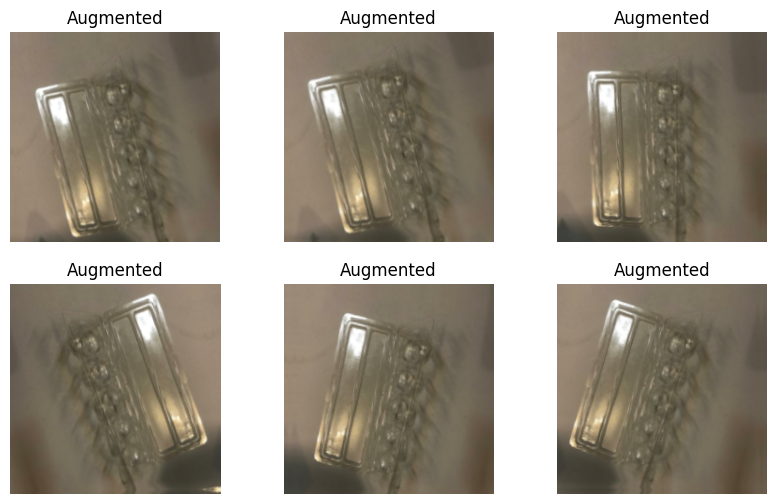

In [16]:
for images, labels in train_ds.take(1):
    sample_image = images[0]
    
    plt.figure(figsize=(10, 6))
    
    for i in range(6):
        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )
        
        augmented_image = tf.clip_by_value(
            tf.squeeze(augmented_image),
            0.0,
            1.0
        )
        
        plt.subplot(2, 3, i + 1)
        plt.imshow(augmented_image)
        plt.axis("off")
        plt.title("Augmented")
    
    plt.show()

Pada tahap ini dilakukan visualisasi hasil augmentation untuk memastikan bahwa transformasi yang diterapkan masih masuk akal. Satu gambar dari training set dipilih, kemudian diberikan augmentation beberapa kali sehingga menghasilkan beberapa versi gambar yang berbeda.

Dari hasil output, objek utama masih dapat dikenali dengan jelas meskipun mengalami sedikit perubahan posisi, rotasi, zoom, dan kontras. Hal ini menunjukkan bahwa konfigurasi augmentation final sudah cukup baik karena memberikan variasi tanpa merusak bentuk dan detail utama objek.

Visualisasi ini penting dilakukan sebelum training karena augmentation yang terlalu agresif dapat membuat gambar menjadi tidak realistis dan justru menurunkan performa model. Berdasarkan hasil visualisasi, konfigurasi augmentation final dinilai layak digunakan untuk membantu model menjadi lebih robust, meningkatkan kemampuan generalisasi, dan mengurangi risiko overfitting.

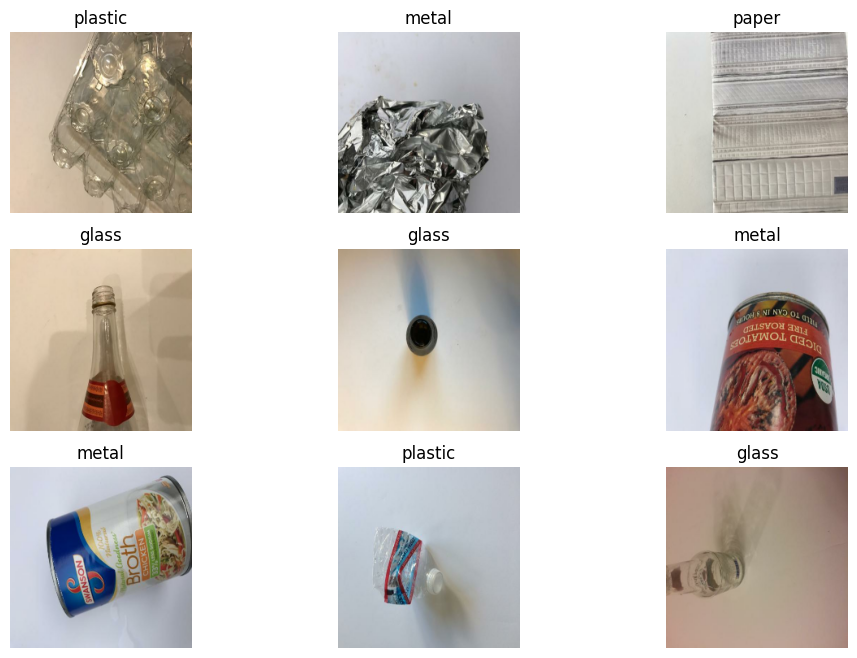

In [17]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        image = images[i]
        label_index = np.argmax(labels[i].numpy())
        label_name = index_to_class[label_index]
        
        plt.subplot(3, 3, i + 1)
        plt.imshow(image)
        plt.title(label_name)
        plt.axis("off")

plt.show()

Pada tahap ini dilakukan visualisasi beberapa contoh gambar dari training set untuk memastikan bahwa data sudah terbaca dengan benar. Gambar ditampilkan bersama labelnya, seperti `plastic`, `metal`, `paper`, dan `glass`.

Visualisasi ini penting karena sebelum model dilatih, kita perlu memastikan bahwa gambar dan label sudah sesuai. Jika gambar yang ditampilkan tidak cocok dengan labelnya, maka model dapat belajar dari data yang salah. Berdasarkan output, gambar berhasil ditampilkan dengan label yang sesuai, sehingga dataset dapat digunakan untuk tahap training model.

Selain itu, visualisasi ini juga membantu memahami karakteristik dataset. Beberapa kelas terlihat memiliki bentuk dan tekstur yang cukup berbeda, tetapi ada juga kelas yang secara visual bisa mirip, misalnya `glass`, `plastic`, dan `metal`. Hal ini dapat menjadi tantangan bagi model saat melakukan klasifikasi.

## Class Weight

In [18]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label_index"]),
    y=train_df["label_index"]
)

class_weights = {
    i: float(weight) for i, weight in enumerate(class_weights_array)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}


Pada tahap ini dilakukan perhitungan class weight untuk menangani masalah class imbalance. Class imbalance terjadi karena jumlah gambar pada setiap kelas tidak sama. Pada dataset ini, kelas seperti `paper`, `glass`, dan `plastic` memiliki jumlah data lebih banyak, sedangkan kelas `trash` memiliki jumlah data paling sedikit.

Class weight dihitung menggunakan `compute_class_weight()` dengan mode `balanced`. Tujuannya adalah agar kelas dengan jumlah data lebih sedikit mendapatkan bobot yang lebih besar saat training. Dengan begitu, model tidak terlalu bias terhadap kelas mayoritas dan tetap memperhatikan kelas minoritas.

Hasil class weight menunjukkan bahwa kelas `trash` mendapatkan bobot paling besar, yaitu sekitar `3.06`. Hal ini masuk akal karena kelas `trash` memiliki jumlah data paling sedikit. Sebaliknya, kelas `paper` mendapatkan bobot paling kecil, yaitu sekitar `0.71`, karena jumlah datanya paling banyak.

Class weight ini nantinya digunakan pada saat `model.fit()` agar kesalahan pada kelas minoritas memiliki pengaruh loss yang lebih besar. Dengan cara ini, model diharapkan dapat belajar lebih seimbang pada seluruh kelas, bukan hanya pada kelas yang jumlah datanya banyak.

In [19]:
# ============================================================
# CUSTOM CLASS WEIGHT UNTUK MENINGKATKAN RECALL GLASS DAN TRASH
# ============================================================

custom_class_weights = class_weights.copy()

print("Class mapping:")
print(class_to_index)

glass_index = class_to_index["glass"]
trash_index = class_to_index["trash"]

# Bobot glass dinaikkan manual karena sebelumnya recall glass rendah
custom_class_weights[glass_index] = 1.3

# Bobot trash juga dinaikkan karena jumlah datanya paling sedikit
# dan pada MobileNetV2 sebelumnya performa trash masih rendah
custom_class_weights[trash_index] = class_weights[trash_index] * 1.2

print("Original class weights:")
print(class_weights)

print("\nCustom class weights:")
print(custom_class_weights)

print("\nGlass index:", glass_index)
print("Trash index:", trash_index)
print("Glass weight:", custom_class_weights[glass_index])
print("Trash weight:", custom_class_weights[trash_index])

Class mapping:
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Original class weights:
{0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}

Custom class weights:
{0: 1.044917257683215, 1: 1.3, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.6833333333333336}

Glass index: 1
Trash index: 5
Glass weight: 1.3
Trash weight: 3.6833333333333336


Pada tahap ini, class weight yang sudah dihitung sebelumnya disesuaikan secara manual untuk kelas tertentu, yaitu `glass` dan `trash`.

Pertama, class weight awal disalin ke variabel baru `custom_class_weights` agar bobot asli tetap tersimpan. Setelah itu, kode mengambil index dari kelas `glass` dan `trash` berdasarkan `class_to_index`.

Bobot kelas `glass` dinaikkan menjadi **1.3** karena pada evaluasi sebelumnya kelas `glass` masih memiliki recall yang rendah. Artinya, model masih sering gagal mengenali gambar yang sebenarnya termasuk kelas `glass`.

Bobot kelas `trash` juga dinaikkan dengan cara mengalikan bobot awalnya sebesar **1.2 kali**. Hal ini dilakukan karena kelas `trash` memiliki jumlah data paling sedikit dan performanya masih perlu ditingkatkan.

Hasil akhirnya menunjukkan bahwa bobot `glass` berubah menjadi **1.3**, sedangkan bobot `trash` meningkat menjadi sekitar **3.68**. Dengan penyesuaian ini, model akan memberikan perhatian lebih besar pada kelas `glass` dan `trash` selama proses training.

In [20]:
# ============================================================
# 18. CEK SHAPE DATASET
# ============================================================

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 6)


Pada tahap ini dilakukan pengecekan shape dari data yang sudah masuk ke TensorFlow dataset pipeline. Pengecekan ini penting untuk memastikan bahwa format gambar dan label sudah sesuai sebelum digunakan untuk training model CNN.

# Transfer Learning dengan MobileNetV2

Setelah tahap data preprocessing selesai, tahap berikutnya adalah membangun model klasifikasi gambar menggunakan pendekatan **transfer learning**. Pada bagian ini, arsitektur yang digunakan adalah **MobileNetV2**.

MobileNetV2 dipilih karena merupakan arsitektur CNN yang ringan, efisien, dan sudah dilatih sebelumnya pada dataset besar seperti ImageNet. Dengan menggunakan model pretrained, model tidak perlu belajar fitur visual dari awal. Model sudah memiliki kemampuan dasar untuk mengenali pola umum pada gambar, seperti garis, warna, tekstur, bentuk, dan bagian objek.

Pendekatan transfer learning digunakan untuk meningkatkan performa model dibandingkan CNN yang dibangun dari awal. Hal ini karena dataset project memiliki jumlah data yang terbatas dan beberapa kelas memiliki karakteristik visual yang mirip. Dengan memanfaatkan fitur yang sudah dipelajari oleh MobileNetV2, model diharapkan dapat mengenali objek sampah dengan lebih baik.

Pada project ini, dibuat dua varian model transfer learning, yaitu **MobileNetV2 V1** dan **MobileNetV2 V2**. Kedua model ini digunakan untuk membandingkan pengaruh konfigurasi training yang berbeda, seperti penggunaan class weight, jumlah layer yang di-fine-tune, dan strategi training. Tujuannya adalah untuk mencari konfigurasi transfer learning yang memberikan hasil terbaik.

Library yang digunakan pada tahap ini meliputi `MobileNetV2` sebagai base model, `layers` dan `models` untuk membangun arsitektur model, serta `classification_report`, `confusion_matrix`, dan `ConfusionMatrixDisplay` untuk mengevaluasi performa model.

Mengimpor seluruh library yang dibutuhkan untuk transfer learning dan evaluasi. `MobileNetV2` adalah arsitektur CNN ringan yang dipakai sebagai base model. `layers` dan `models` digunakan untuk menyusun arsitektur, sedangkan `classification_report`, `confusion_matrix`, dan `ConfusionMatrixDisplay` dari scikit-learn dipakai untuk evaluasi performa model.

In [21]:
# ============================================================
# 30. IMPORT LIBRARY UNTUK TRANSFER LEARNING
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [22]:
# ============================================================
# 31. CEK VARIABEL YANG DIBUTUHKAN
# ============================================================

needed_vars = [
    "train_ds",
    "val_ds",
    "test_ds",
    "IMG_SIZE",
    "NUM_CLASSES",
    "class_names",
    "class_to_index",
    "index_to_class",
    "data_augmentation",
    "class_weights"
]

for var in needed_vars:
    print(var, "ada" if var in globals() else "BELUM ADA")

train_ds ada
val_ds ada
test_ds ada
IMG_SIZE ada
NUM_CLASSES ada
class_names ada
class_to_index ada
index_to_class ada
data_augmentation ada
class_weights ada


Mengecek apakah seluruh variabel penting hasil tahap preprocessing (seperti `train_ds`, `val_ds`, `test_ds`, `IMG_SIZE`, `class_names`, hingga `class_weights`) sudah tersedia di memori. Pengecekan ini memastikan tahap modeling tidak gagal karena ada variabel yang belum dibuat.

## MobileNetV2 Versi 1 (V1)

Varian pertama. Fokus penyesuaian pada kelas `glass` yang sebelumnya memiliki *recall* rendah. Pada tahap *fine-tuning*, 30 layer terakhir base model dibuka.

Membuat *custom class weight* untuk model V1. Bobot dihitung ulang dari `class_weights` dasar, lalu bobot kelas `glass` dinaikkan manual menjadi `1.3`. Tujuannya memaksa model lebih memperhatikan kelas `glass` yang pada percobaan sebelumnya memiliki *recall* rendah, sehingga lebih banyak sampel `glass` dikenali dengan benar.

In [23]:
# ============================================================
# 32. CUSTOM CLASS WEIGHT V1 - FOKUS GLASS
# ============================================================

custom_class_weights_v1 = class_weights.copy()

print("Class mapping:")
print(class_to_index)

glass_index = class_to_index["glass"]

# Bobot glass dinaikkan karena recall glass sebelumnya rendah
custom_class_weights_v1[glass_index] = 1.3

print("Original class weights:")
print(class_weights)

print("\nCustom class weights V1:")
print(custom_class_weights_v1)

print("\nGlass index:", glass_index)
print("Glass weight:", custom_class_weights_v1[glass_index])

Class mapping:
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Original class weights:
{0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}

Custom class weights V1:
{0: 1.044917257683215, 1: 1.3, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}

Glass index: 1
Glass weight: 1.3


Custom class weight V1 dibuat untuk memberikan perhatian tambahan pada kelas `glass`. Berdasarkan mapping kelas, `glass` memiliki index **1**.

Bobot awal kelas `glass` adalah sekitar **0.84**, kemudian dinaikkan secara manual menjadi **1.3**. Penyesuaian ini dilakukan karena kelas `glass` sebelumnya memiliki recall yang rendah, sehingga model masih cukup sering gagal mengenali gambar kaca dengan benar.

Dengan bobot yang lebih besar, kesalahan prediksi pada kelas `glass` akan memberikan penalti loss yang lebih tinggi selama training. Tujuannya adalah agar model lebih fokus mempelajari karakteristik visual kaca, seperti transparansi, pantulan cahaya, bentuk lengkung, dan warna yang sering mirip dengan kelas lain seperti `plastic` atau `metal`.

In [24]:
# ============================================================
# 33. BUILD MODEL MOBILENETV2 TRANSFER LEARNING V1
# ============================================================

def build_mobilenetv2_v1():
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )

    # Phase awal: freeze seluruh pretrained base model
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    # Augmentation hanya aktif saat training
    x = data_augmentation(inputs)

    # Dataset sudah dinormalisasi 0-1.
    # MobileNetV2 lebih cocok input -1 sampai 1.
    x = layers.Rescaling(2.0, offset=-1.0)(x)

    # Base model frozen
    x = base_model(x, training=False)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(
        256,
        activation="relu",
        name="v1_dense"
    )(x)

    x = layers.Dropout(
        0.4,
        name="v1_dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="v1_output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="mobilenetv2_transfer_learning_v1"
    )

    return model, base_model


transfer_model_v1, base_model_v1 = build_mobilenetv2_v1()

transfer_model_v1.summary()

Model: "mobilenetv2_transfer_learning_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v1_dense (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v1_dropout (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v1_output (Dense)               │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,582 (9.89 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

MobileNetV2 V1 dibangun menggunakan pendekatan transfer learning. Model ini menggunakan MobileNetV2 sebagai base model dengan input gambar berukuran **224 x 224 x 3**. Ukuran tersebut sesuai dengan format gambar RGB yang digunakan pada dataset.

MobileNetV2 digunakan dengan `include_top=False`, sehingga layer klasifikasi bawaan dari MobileNetV2 tidak digunakan. Hal ini dilakukan karena layer output bawaan MobileNetV2 tidak sesuai dengan jumlah kelas pada dataset project. Sebagai gantinya, dibuat classification head baru yang disesuaikan dengan jumlah kelas dataset, yaitu **6 kelas**.

Base model MobileNetV2 menggunakan bobot pretrained dari ImageNet melalui `weights='imagenet'`. Artinya, model sudah memiliki pengetahuan awal tentang fitur visual umum seperti edge, tekstur, bentuk, warna, dan pola objek. Pada tahap awal, base model dibuat dalam kondisi frozen dengan `base_model.trainable = False`, sehingga bobot MobileNetV2 tidak ikut berubah selama training awal. Model hanya melatih layer tambahan yang dibuat di atas MobileNetV2.

Sebelum gambar masuk ke MobileNetV2, data melewati `data_augmentation` dan `Rescaling`. Data augmentation hanya aktif saat training untuk membuat variasi gambar lebih banyak, sedangkan `Rescaling` mengubah nilai pixel dari rentang 0–255 menjadi rentang -1 sampai 1. Rentang ini sesuai dengan kebutuhan preprocessing MobileNetV2.

Setelah gambar diproses oleh MobileNetV2, output feature map diringkas menggunakan `GlobalAveragePooling2D`. Layer ini mengubah hasil ekstraksi fitur menjadi vector satu dimensi dengan jumlah fitur 1280. Setelah itu, digunakan `BatchNormalization` untuk membantu menstabilkan proses training.

Classification head terdiri dari `Dense(256)` dengan aktivasi ReLU, kemudian `Dropout(0.4)` untuk mengurangi risiko overfitting. Output terakhir menggunakan `Dense(NUM_CLASSES)` dengan aktivasi softmax. Softmax digunakan karena task ini merupakan multi-class classification, sehingga model menghasilkan probabilitas untuk setiap kelas.

Berdasarkan model summary, total parameter model adalah sekitar **2.592.582 parameter**. Dari jumlah tersebut, hanya sekitar **333.030 parameter** yang trainable, sedangkan sekitar **2.259.544 parameter** tidak trainable. Hal ini menunjukkan bahwa sebagian besar parameter dari MobileNetV2 masih dibekukan, sementara parameter yang dilatih terutama berasal dari classification head baru.

Secara keseluruhan, MobileNetV2 V1 digunakan untuk memanfaatkan kemampuan pretrained MobileNetV2 sebagai feature extractor, lalu menambahkan classifier baru agar model dapat menyesuaikan diri dengan dataset klasifikasi sampah.

In [25]:
# ============================================================
# 34. COMPILE MODEL V1 - PHASE 1 FROZEN
# ============================================================

transfer_model_v1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

Model MobileNetV2 V1 dikompilasi pada fase pertama dengan kondisi base model masih **frozen**. Artinya, bobot pretrained dari MobileNetV2 belum ikut dilatih, sehingga training hanya berfokus pada classification head yang ditambahkan di atas base model.

Optimizer yang digunakan adalah **Adam** dengan learning rate **1e-4**. Learning rate ini dipilih agar proses training berjalan stabil dan tidak terlalu agresif, terutama karena model menggunakan pretrained feature extractor.

Loss function yang digunakan adalah **categorical_crossentropy** karena task ini merupakan **multi-class classification** dengan output softmax dan label berbentuk one-hot encoding.

Metrics yang digunakan adalah **accuracy**, **precision**, dan **recall**. Accuracy digunakan untuk melihat performa keseluruhan model, precision digunakan untuk melihat ketepatan prediksi model pada setiap kelas, sedangkan recall digunakan untuk melihat kemampuan model dalam menemukan data dari kelas sebenarnya.

Pada output juga muncul warning bahwa GPU TensorFlow tidak tersedia secara native di Windows untuk versi TensorFlow tertentu. Warning ini tidak menghentikan proses training, tetapi menunjukkan bahwa training kemungkinan berjalan menggunakan CPU, sehingga prosesnya bisa lebih lambat dibandingkan jika menggunakan GPU.

In [26]:
# ============================================================
# 35. CEK TRAINABLE LAYER V1 SEBELUM TRAINING
# ============================================================

print("Base model V1 trainable:", base_model_v1.trainable)
print("Total layer MobileNetV2 V1:", len(base_model_v1.layers))

trainable_count = 0
non_trainable_count = 0

for layer in transfer_model_v1.layers:
    if layer.trainable:
        trainable_count += 1
    else:
        non_trainable_count += 1

print("Trainable layer pada full model V1:", trainable_count)
print("Non-trainable layer pada full model V1:", non_trainable_count)

Base model V1 trainable: False
Total layer MobileNetV2 V1: 154
Trainable layer pada full model V1: 8
Non-trainable layer pada full model V1: 1


Pengecekan ini dilakukan untuk memastikan status layer sebelum model MobileNetV2 V1 dilatih pada fase pertama.

Hasil output menunjukkan bahwa `base_model_v1.trainable` bernilai **False**. Artinya, base model MobileNetV2 masih dalam kondisi **frozen**, sehingga bobot pretrained dari MobileNetV2 tidak akan diperbarui selama training awal.

Jumlah layer pada base model MobileNetV2 adalah **154 layer**. Karena base model masih frozen, layer-layer tersebut tidak ikut dilatih pada fase pertama.

Pada full model V1, terdapat **8 trainable layer** dan **1 non-trainable layer**. Trainable layer ini berasal dari classification head yang ditambahkan di atas MobileNetV2, seperti GlobalAveragePooling, BatchNormalization, Dense, Dropout, dan output layer.

Dengan kondisi ini, training fase pertama hanya melatih classification head, sementara MobileNetV2 tetap digunakan sebagai feature extractor. Strategi ini membantu model belajar menyesuaikan output dengan kelas dataset tanpa merusak bobot pretrained yang sudah dimiliki MobileNetV2.

In [27]:
# ============================================================
# 36. CALLBACKS V1 - PHASE 1 FROZEN
# ============================================================

frozen_callbacks_v1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_mobilenetv2_v1_frozen.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

Pada training MobileNetV2 V1 fase pertama, digunakan beberapa callback untuk membantu proses training berjalan lebih stabil dan efisien.

`EarlyStopping` digunakan untuk menghentikan training jika `val_accuracy` tidak mengalami peningkatan setelah beberapa epoch. Pada konfigurasi ini, `patience=7`, artinya training akan berhenti jika validation accuracy tidak membaik selama 7 epoch berturut-turut. Parameter `restore_best_weights=True` membuat model mengembalikan bobot terbaik dari epoch dengan validation accuracy tertinggi.

`ReduceLROnPlateau` digunakan untuk menurunkan learning rate ketika `val_accuracy` tidak meningkat. Jika validation accuracy stagnan selama 3 epoch, learning rate akan dikurangi dengan faktor 0.5. Tujuannya adalah agar proses optimasi menjadi lebih halus ketika model mulai sulit mengalami peningkatan.

`ModelCheckpoint` digunakan untuk menyimpan model terbaik selama training. Model disimpan ke file `best_mobilenetv2_v1_frozen.keras` berdasarkan nilai `val_accuracy` tertinggi. Dengan callback ini, model terbaik tetap tersimpan meskipun training berhenti pada epoch yang lebih akhir.

Secara keseluruhan, callback ini digunakan untuk mencegah training yang terlalu lama, menjaga performa terbaik model, dan membantu model mencapai hasil validasi yang lebih optimal pada fase frozen.

In [28]:
# ============================================================
# 37. TRAINING V1 - PHASE 1 FROZEN BASE MODEL
# ============================================================

FROZEN_EPOCHS_V1 = 10

print("Training MobileNetV2 V1 - Phase 1 Frozen")
print("Pada tahap ini, seluruh base model di-freeze.")
print("Yang dilatih hanya classification head.")

start_time = time.time()

history_frozen_v1 = transfer_model_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FROZEN_EPOCHS_V1,
    callbacks=frozen_callbacks_v1,
    class_weight=custom_class_weights_v1,
    verbose=1
)

frozen_training_time_v1 = time.time() - start_time

print("Training V1 Phase 1 selesai.")
print(f"Frozen training time V1: {frozen_training_time_v1:.2f} seconds")

Training MobileNetV2 V1 - Phase 1 Frozen
Pada tahap ini, seluruh base model di-freeze.
Yang dilatih hanya classification head.
Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.2763 - loss: 2.4705 - precision: 0.3176 - recall: 0.1762
Epoch 1: val_accuracy improved from None to 0.62797, saving model to best_mobilenetv2_v1_frozen.keras

Epoch 1: finished saving model to best_mobilenetv2_v1_frozen.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 37s 566ms/step - accuracy: 0.3484 - loss: 2.1305 - precision: 0.4197 - recall: 0.2455 - val_accuracy: 0.6280 - val_loss: 1.1198 - val_precision: 0.8176 - val_recall: 0.3193 - learning_rate: 1.0000e-04
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.5642 - loss: 1.3481 - precision: 0.6436 - recall: 0.4588
Epoch 2: val_accuracy improved from 0.62797 to 0.70976, saving model to best_mobilenetv2_v1_frozen.keras

Epoch 2: finished saving model to best_mobilenetv2_v1_frozen.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 511ms/step - accuracy: 0.

Pada fase pertama, MobileNetV2 V1 dilatih dengan kondisi base model masih **frozen**. Artinya, bobot pretrained dari MobileNetV2 tidak ikut diperbarui, dan training hanya dilakukan pada classification head yang ditambahkan di atas base model.

Model dilatih selama maksimal **10 epoch** menggunakan `custom_class_weights_v1`. Class weight ini digunakan agar model lebih memperhatikan kelas tertentu, terutama kelas `glass`, yang sebelumnya memiliki recall rendah.

Hasil training menunjukkan peningkatan performa yang cukup baik. Training accuracy meningkat dari sekitar **0.3484** pada epoch pertama menjadi **0.8348** pada epoch ke-10. Validation accuracy juga meningkat dari **0.6280** pada epoch pertama menjadi **0.8100** pada epoch ke-9 dan ke-10.

Validation loss juga menurun dari **1.1198** pada epoch pertama menjadi **0.5826** pada epoch ke-10. Penurunan loss ini menunjukkan bahwa kesalahan prediksi model semakin kecil selama proses training.

Model terbaik disimpan menggunakan `ModelCheckpoint` berdasarkan nilai validation accuracy tertinggi. Nilai validation accuracy terbaik diperoleh pada **epoch ke-9**, yaitu sekitar **0.8100**. Pada epoch ke-10, validation accuracy tidak meningkat lagi, sehingga model mengembalikan bobot terbaik dari epoch ke-9.

Secara keseluruhan, fase frozen berhasil membuat classification head belajar dengan baik dari fitur yang sudah diekstraksi oleh MobileNetV2. Hasil ini menunjukkan bahwa transfer learning dengan MobileNetV2 mampu memberikan performa yang cukup baik meskipun base model belum di-fine-tune.

In [29]:
# ============================================================
# 38. SETUP FINE-TUNING V1
# ============================================================

# Buka base model
base_model_v1.trainable = True

# V1: buka 30 layer terakhir
fine_tune_at_v1 = len(base_model_v1.layers) - 30

for layer in base_model_v1.layers[:fine_tune_at_v1]:
    layer.trainable = False

# BatchNormalization tetap freeze agar training lebih stabil
for layer in base_model_v1.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total layer MobileNetV2 V1:", len(base_model_v1.layers))
print("Fine-tuning V1 dimulai dari layer ke:", fine_tune_at_v1)

trainable_base_layers_v1 = sum([layer.trainable for layer in base_model_v1.layers])
print("Jumlah layer base model V1 yang trainable:", trainable_base_layers_v1)

Total layer MobileNetV2 V1: 154
Fine-tuning V1 dimulai dari layer ke: 124
Jumlah layer base model V1 yang trainable: 19


Pada tahap fine-tuning, base model MobileNetV2 V1 dibuka kembali dengan mengubah `base_model_v1.trainable = True`. Artinya, sebagian layer pada MobileNetV2 dapat ikut dilatih agar fitur yang sudah dipelajari dari ImageNet dapat menyesuaikan diri dengan dataset sampah.

Pada V1, fine-tuning dilakukan dengan membuka **30 layer terakhir** dari base model. Karena total layer MobileNetV2 berjumlah **154 layer**, maka fine-tuning dimulai dari layer ke-**124**. Layer sebelum index tersebut tetap dibuat frozen agar fitur dasar dari MobileNetV2 tetap stabil.

Meskipun sebagian layer dibuka untuk training, layer **BatchNormalization** tetap dibuat frozen. Hal ini dilakukan agar proses fine-tuning lebih stabil, karena BatchNormalization menyimpan statistik internal seperti mean dan variance yang dapat berubah jika ikut dilatih.

Hasil output menunjukkan bahwa dari 154 layer MobileNetV2, terdapat **19 layer base model yang trainable**. Ini berarti hanya sebagian kecil layer akhir yang akan diperbarui saat fine-tuning. Strategi ini digunakan agar model dapat menyesuaikan fitur tingkat tinggi dengan dataset project tanpa merusak fitur dasar yang sudah dipelajari dari ImageNet.

In [30]:
# ============================================================
# 39. COMPILE ULANG V1 UNTUK FINE-TUNING
# ============================================================

transfer_model_v1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

transfer_model_v1.summary()

Model: "mobilenetv2_transfer_learning_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v1_dense (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v1_dropout (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v1_output (Dense)               │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,582 (9.89 MB)

 Trainable params: 1,842,758 (7.03 MB)

 Non-trainable params: 749,824 (2.86 MB)

Setelah sebagian layer akhir dari base model MobileNetV2 dibuka, model perlu dikompilasi ulang sebelum proses fine-tuning dijalankan. Compile ulang diperlukan karena perubahan status `trainable` pada layer baru akan diterapkan setelah model dikompilasi kembali.

Pada tahap fine-tuning ini, optimizer yang digunakan tetap **Adam**, tetapi learning rate diturunkan menjadi **1e-5**. Learning rate yang lebih kecil digunakan agar proses update bobot pada layer pretrained berjalan lebih hati-hati dan tidak merusak fitur visual yang sudah dipelajari dari ImageNet.

Loss function yang digunakan tetap **categorical_crossentropy** karena task ini merupakan multi-class classification dengan output softmax. Metrics yang digunakan juga tetap sama, yaitu **accuracy**, **precision**, dan **recall** untuk mengevaluasi performa model secara lebih lengkap.

Berdasarkan model summary, total parameter model adalah **2,592,582**. Setelah fine-tuning diaktifkan, jumlah trainable parameters meningkat menjadi **1,842,758**, sedangkan non-trainable parameters menjadi **749,824**. Hal ini menunjukkan bahwa sebagian layer MobileNetV2 sudah ikut dilatih, tetapi masih ada beberapa parameter yang tetap frozen untuk menjaga stabilitas training.

Dengan compile ulang ini, model MobileNetV2 V1 siap masuk ke tahap fine-tuning agar dapat menyesuaikan fitur tingkat tinggi dengan karakteristik dataset sampah.

In [31]:
# ============================================================
# 40. CALLBACKS V1 - PHASE 2 FINE-TUNING
# ============================================================

finetune_callbacks_v1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-8,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_mobilenetv2_v1_finetuned.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

Pada fase fine-tuning MobileNetV2 V1, digunakan beberapa callback untuk menjaga proses training tetap stabil dan efisien.

`EarlyStopping` digunakan untuk menghentikan training jika `val_accuracy` tidak mengalami peningkatan selama beberapa epoch. Pada konfigurasi ini, `patience=8`, sehingga training akan berhenti jika validation accuracy tidak membaik selama 8 epoch berturut-turut. Parameter `restore_best_weights=True` memastikan model kembali menggunakan bobot terbaik dari epoch dengan validation accuracy tertinggi.

`ReduceLROnPlateau` digunakan untuk menurunkan learning rate ketika `val_accuracy` mulai stagnan. Jika validation accuracy tidak meningkat selama 3 epoch, learning rate akan dikurangi sebesar 50%. Hal ini membantu proses fine-tuning menjadi lebih halus dan mengurangi risiko perubahan bobot pretrained yang terlalu besar.

`ModelCheckpoint` digunakan untuk menyimpan model terbaik selama fine-tuning ke file `best_mobilenetv2_v1_finetuned.keras`. Model terbaik dipilih berdasarkan nilai `val_accuracy` tertinggi.

Secara keseluruhan, callback ini digunakan agar fine-tuning tidak berjalan terlalu lama, tetap menyimpan model terbaik, dan membantu model menyesuaikan fitur MobileNetV2 dengan dataset sampah secara lebih stabil.

In [32]:
# ============================================================
# 41. TRAINING V1 - PHASE 2 FINE-TUNING
# ============================================================

FINETUNE_EPOCHS_V1 = 15

print("Training MobileNetV2 V1 - Phase 2 Fine-tuning")
print("Pada tahap ini, beberapa layer akhir base model ikut dilatih.")

start_time = time.time()

history_finetune_v1 = transfer_model_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINETUNE_EPOCHS_V1,
    callbacks=finetune_callbacks_v1,
    class_weight=custom_class_weights_v1,
    verbose=1
)

finetune_training_time_v1 = time.time() - start_time

print("Training V1 Phase 2 selesai.")
print(f"Fine-tuning time V1: {finetune_training_time_v1:.2f} seconds")

Training MobileNetV2 V1 - Phase 2 Fine-tuning
Pada tahap ini, beberapa layer akhir base model ikut dilatih.
Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.8427 - loss: 0.4757 - precision: 0.8651 - recall: 0.8041
Epoch 1: val_accuracy improved from None to 0.82322, saving model to best_mobilenetv2_v1_finetuned.keras

Epoch 1: finished saving model to best_mobilenetv2_v1_finetuned.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 546ms/step - accuracy: 0.8314 - loss: 0.5058 - precision: 0.8594 - recall: 0.7952 - val_accuracy: 0.8232 - val_loss: 0.5737 - val_precision: 0.8459 - val_recall: 0.7968 - learning_rate: 1.0000e-05
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.8394 - loss: 0.4717 - precision: 0.8645 - recall: 0.8122
Epoch 2: val_accuracy did not improve from 0.82322
56/56 ━━━━━━━━━━━━━━━━━━━━ 30s 537ms/step - accuracy: 0.8388 - loss: 0.4711 - precision: 0.8653 - recall: 0.8100 - val_accuracy: 0.8179 - val_loss: 0.5776 - val_precision: 0.8503 - val_recall

Pada fase kedua, MobileNetV2 V1 dilatih dengan beberapa layer akhir base model yang sudah dibuka. Tujuan fine-tuning adalah agar fitur yang sudah dipelajari dari ImageNet dapat lebih menyesuaikan dengan karakteristik dataset sampah.

Model dilatih selama maksimal **15 epoch** menggunakan `custom_class_weights_v1`. Pada fase ini, learning rate dibuat kecil, yaitu **1e-5**, agar perubahan bobot pretrained tidak terlalu besar dan training tetap stabil.

Hasil training menunjukkan bahwa performa model meningkat dibandingkan fase frozen. Pada epoch pertama, validation accuracy sudah mencapai **0.8232**. Validation accuracy terbaik diperoleh pada **epoch ke-4**, yaitu sebesar **0.8364**, sehingga model terbaik disimpan ke file `best_mobilenetv2_v1_finetuned.keras`.

Setelah epoch ke-4, validation accuracy tidak mengalami peningkatan yang signifikan. Meskipun training accuracy terus meningkat hingga sekitar **0.91**, validation accuracy cenderung stagnan di sekitar **0.83**. Hal ini menunjukkan bahwa model mulai lebih banyak belajar pada data training, tetapi peningkatannya pada data validation sudah terbatas.

Callback `ReduceLROnPlateau` menurunkan learning rate beberapa kali karena validation accuracy tidak membaik. Training kemudian dihentikan lebih awal pada epoch ke-12 oleh `EarlyStopping`, dan bobot model dikembalikan ke epoch terbaik, yaitu epoch ke-4.

Secara keseluruhan, fine-tuning berhasil meningkatkan validation accuracy dari sekitar **0.8100** pada fase frozen menjadi **0.8364**. Artinya, membuka sebagian layer akhir MobileNetV2 membantu model menyesuaikan fitur visualnya dengan dataset sampah, meskipun peningkatannya tidak terlalu besar.

In [33]:
# ============================================================
# 42. EVALUASI MOBILENETV2 V1 PADA TEST SET
# ============================================================

v1_test_loss, v1_test_accuracy, v1_test_precision, v1_test_recall = transfer_model_v1.evaluate(
    test_ds,
    verbose=1
)

print("MobileNetV2 V1 Test Loss     :", v1_test_loss)
print("MobileNetV2 V1 Test Accuracy :", v1_test_accuracy)
print("MobileNetV2 V1 Test Precision:", v1_test_precision)
print("MobileNetV2 V1 Test Recall   :", v1_test_recall)

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 414ms/step - accuracy: 0.8132 - loss: 0.5489 - precision: 0.8405 - recall: 0.7763
MobileNetV2 V1 Test Loss     : 0.5488980412483215
MobileNetV2 V1 Test Accuracy : 0.8131579160690308
MobileNetV2 V1 Test Precision: 0.8404558300971985
MobileNetV2 V1 Test Recall   : 0.7763158082962036


MobileNetV2 V1 dievaluasi menggunakan test set untuk melihat performa model pada data yang belum pernah digunakan selama training maupun validation.

Hasil evaluasi menunjukkan bahwa model memperoleh **test accuracy sebesar 0.8132** atau sekitar **81.32%**. Artinya, model mampu memprediksi sebagian besar gambar test dengan benar.

Nilai **test loss sebesar 0.5489** menunjukkan tingkat kesalahan model pada test set. Nilai loss ini masih cukup wajar dan menunjukkan bahwa model memiliki performa yang cukup stabil.

Nilai **precision sebesar 0.8405** menunjukkan bahwa ketika model memprediksi suatu kelas, sekitar **84.05%** prediksinya benar. Sementara itu, nilai **recall sebesar 0.7763** menunjukkan bahwa model mampu menemukan sekitar **77.63%** data yang seharusnya dikenali pada kelas-kelas sebenarnya.

Secara keseluruhan, hasil ini menunjukkan bahwa MobileNetV2 V1 memiliki performa yang cukup baik pada test set. Model mampu melakukan generalisasi dengan cukup baik, meskipun masih ada ruang peningkatan terutama pada recall, karena masih ada beberapa gambar yang belum berhasil dikenali dengan benar.

In [34]:
# ============================================================
# 43. CLASSIFICATION REPORT MOBILENETV2 V1
# ============================================================

y_true_v1 = []
y_pred_v1 = []

for images, labels in test_ds:
    predictions = transfer_model_v1.predict(images, verbose=0)

    true_labels = np.argmax(labels.numpy(), axis=1)
    pred_labels = np.argmax(predictions, axis=1)

    y_true_v1.extend(true_labels)
    y_pred_v1.extend(pred_labels)

y_true_v1 = np.array(y_true_v1)
y_pred_v1 = np.array(y_pred_v1)

print("Classification Report - MobileNetV2 Transfer Learning V1")
print(
    classification_report(
        y_true_v1,
        y_pred_v1,
        target_names=class_names
    )
)

Classification Report - MobileNetV2 Transfer Learning V1
              precision    recall  f1-score   support

   cardboard       0.84      0.88      0.86        60
       glass       0.83      0.79      0.81        76
       metal       0.72      0.90      0.80        62
       paper       0.92      0.78      0.84        89
     plastic       0.82      0.82      0.82        73
       trash       0.58      0.55      0.56        20

    accuracy                           0.81       380
   macro avg       0.79      0.79      0.78       380
weighted avg       0.82      0.81      0.81       380



Classification report digunakan untuk melihat performa MobileNetV2 V1 pada setiap kelas secara lebih detail. Metrik yang ditampilkan adalah **precision**, **recall**, **f1-score**, dan **support**.

Secara keseluruhan, MobileNetV2 V1 memperoleh **accuracy sebesar 0.81** atau sekitar **81%** pada test set. Hasil ini menunjukkan bahwa model sudah cukup baik dalam melakukan klasifikasi gambar sampah.

Kelas dengan performa terbaik adalah `cardboard`, dengan precision **0.84**, recall **0.88**, dan f1-score **0.86**. Hal ini menunjukkan bahwa model cukup konsisten dalam mengenali gambar cardboard.

Kelas `paper` juga memiliki precision tinggi, yaitu **0.92**, tetapi recall-nya **0.78**. Artinya, ketika model memprediksi gambar sebagai paper, hasilnya cukup tepat, tetapi masih ada beberapa gambar paper yang salah diprediksi sebagai kelas lain.

Kelas `glass` memperoleh precision **0.83**, recall **0.79**, dan f1-score **0.81**. Hasil ini cukup baik dan menunjukkan bahwa penyesuaian class weight pada kelas glass membantu model mengenali gambar kaca dengan lebih baik.

Kelas `metal` memiliki recall paling tinggi, yaitu **0.90**, tetapi precision-nya **0.72**. Artinya, model cukup baik dalam menemukan gambar metal, tetapi masih ada beberapa gambar dari kelas lain yang ikut diprediksi sebagai metal.

Kelas `plastic` memiliki performa yang seimbang, dengan precision, recall, dan f1-score sebesar **0.82**. Ini menunjukkan bahwa model cukup stabil dalam mengenali kelas plastic.

Kelas dengan performa terendah adalah `trash`, dengan precision **0.58**, recall **0.55**, dan f1-score **0.56**. Hal ini menunjukkan bahwa kelas trash masih paling sulit dikenali oleh model. Penyebabnya kemungkinan karena jumlah data trash lebih sedikit dan variasi bentuk objeknya lebih beragam dibandingkan kelas lain.

Nilai macro average precision, recall, dan f1-score adalah **0.79**, **0.79**, dan **0.78**. Sementara itu, weighted average berada di sekitar **0.81–0.82**. Perbedaan ini menunjukkan bahwa performa model secara keseluruhan cukup baik, tetapi masih dipengaruhi oleh kelas yang performanya rendah seperti trash.

Secara keseluruhan, MobileNetV2 V1 sudah memberikan performa yang cukup baik, terutama pada kelas cardboard, paper, glass, metal, dan plastic. Namun, model masih perlu ditingkatkan pada kelas trash agar performa klasifikasi lebih seimbang di semua kelas.

<Figure size 800x800 with 0 Axes>

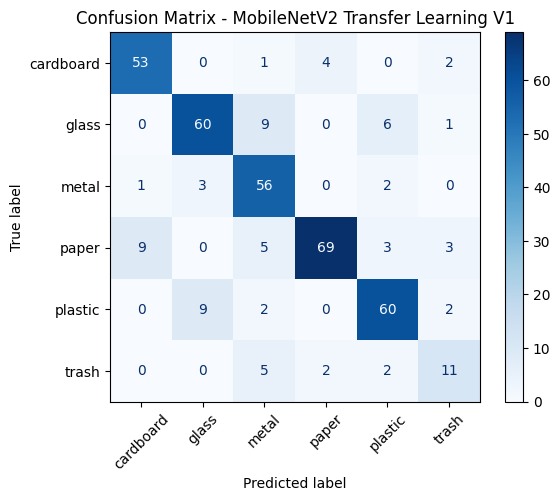

In [35]:
# ============================================================
# 44. CONFUSION MATRIX MOBILENETV2 V1
# ============================================================

cm_v1 = confusion_matrix(
    y_true_v1,
    y_pred_v1
)

disp_v1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_v1,
    display_labels=class_names
)

plt.figure(figsize=(8, 8))
disp_v1.plot(
    cmap="Blues",
    xticks_rotation=45
)
plt.title("Confusion Matrix - MobileNetV2 Transfer Learning V1")
plt.show()

## Confusion Matrix MobileNetV2 V1

Confusion matrix digunakan untuk melihat detail prediksi benar dan salah pada setiap kelas. Baris pada matrix menunjukkan **true label**, sedangkan kolom menunjukkan **predicted label**. Nilai diagonal menunjukkan jumlah prediksi yang benar.

Berdasarkan confusion matrix, model paling banyak memprediksi dengan benar pada kelas `paper`, yaitu **69 gambar**. Kelas `glass` dan `plastic` juga memiliki hasil yang baik, masing-masing dengan **60 prediksi benar**. Kelas `metal` memiliki **56 prediksi benar**, sedangkan `cardboard` memiliki **53 prediksi benar**.

Pada kelas `glass`, terdapat **60 gambar** yang benar diprediksi sebagai glass. Namun, masih ada **9 gambar glass** yang salah diprediksi sebagai `metal` dan **6 gambar glass** yang diprediksi sebagai `plastic`. Hal ini menunjukkan bahwa model masih cukup sering bingung membedakan glass dengan metal dan plastic, kemungkinan karena ketiganya dapat memiliki pantulan cahaya, tekstur mengkilap, atau warna transparan.

Pada kelas `metal`, terdapat **56 gambar** yang benar diprediksi sebagai metal. Kesalahan terbesar pada kelas ini adalah **3 gambar metal** diprediksi sebagai `glass`. Ini menunjukkan adanya kemiripan visual antara metal dan glass, terutama dari sisi refleksi atau permukaan yang mengkilap.

Pada kelas `paper`, terdapat **69 gambar** yang benar diprediksi sebagai paper. Namun, ada **9 gambar paper** yang salah diprediksi sebagai `cardboard` dan **5 gambar paper** sebagai `metal`. Kesalahan antara paper dan cardboard cukup masuk akal karena keduanya sama-sama berbahan dasar kertas dan dapat memiliki warna atau tekstur yang mirip.

Pada kelas `plastic`, terdapat **60 gambar** yang benar diprediksi sebagai plastic. Kesalahan terbesar pada kelas ini adalah **9 gambar plastic** yang diprediksi sebagai `glass`. Hal ini menunjukkan bahwa model masih kesulitan membedakan plastik transparan dengan kaca.

Kelas `trash` memiliki performa paling rendah. Dari 20 gambar trash, hanya **11 gambar** yang benar diprediksi sebagai trash. Sisanya salah diprediksi sebagai `metal`, `paper`, dan `plastic`. Hal ini menunjukkan bahwa kelas trash masih menjadi kelas yang paling sulit dikenali karena bentuk dan karakteristik visualnya sangat beragam.

Secara keseluruhan, confusion matrix menunjukkan bahwa MobileNetV2 V1 sudah cukup baik dalam mengenali kelas `cardboard`, `glass`, `metal`, `paper`, dan `plastic`. Namun, masih terdapat kebingungan antar kelas yang memiliki kemiripan visual, terutama `glass` dengan `plastic` atau `metal`, serta `paper` dengan `cardboard`. Kelas `trash` masih menjadi tantangan utama karena jumlah data lebih sedikit dan variasi objeknya lebih besar.

In [36]:
# ============================================================
# 45. SAVE MODEL MOBILENETV2 V1
# ============================================================

transfer_model_v1.save("final_mobilenetv2_transfer_learning_v1.keras")

print("Model V1 berhasil disimpan.")

Model V1 berhasil disimpan.


Model MobileNetV2 V1 disimpan ke dalam file `final_mobilenetv2_transfer_learning_v1.keras`. Penyimpanan ini dilakukan agar model yang sudah dilatih dapat digunakan kembali tanpa perlu melakukan training ulang.

## MobileNetV2 Versi 2 (V2)

MobileNetV2 V2 dibuat sebagai pengembangan dari MobileNetV2 V1. Pada V1, penyesuaian utama difokuskan pada kelas `glass`, karena kelas tersebut sebelumnya memiliki recall yang rendah. Namun, dari hasil evaluasi V1, kelas `trash` masih memiliki performa yang rendah dan jumlah data paling sedikit dibandingkan kelas lain.

Oleh karena itu, pada V2 dilakukan penyesuaian tambahan. Selain kelas `glass`, kelas `trash` juga diberikan bobot yang lebih besar. Tujuannya adalah agar model lebih memperhatikan dua kelas yang masih sulit dikenali, yaitu `glass` dan `trash`.

Selain perubahan pada class weight, V2 juga dibuat lebih konservatif pada tahap fine-tuning. Jumlah layer yang dibuka lebih sedikit dibandingkan V1, yaitu hanya sebagian layer akhir dari base model. Learning rate juga dibuat lebih kecil agar proses training lebih stabil dan tidak terlalu cepat overfitting.

Secara umum, MobileNetV2 V2 bertujuan untuk memperbaiki kelemahan dari V1, terutama pada kelas `trash`, sambil tetap mempertahankan perhatian tambahan terhadap kelas `glass`.

In [37]:
# ============================================================
# 46. CUSTOM CLASS WEIGHT V2 - FOKUS GLASS DAN TRASH
# ============================================================

custom_class_weights_v2 = class_weights.copy()

print("Class mapping:")
print(class_to_index)

glass_index = class_to_index["glass"]
trash_index = class_to_index["trash"]

# Bobot glass tetap dinaikkan
custom_class_weights_v2[glass_index] = 1.3

# Bobot trash dinaikkan karena performa trash pada V1 masih rendah
custom_class_weights_v2[trash_index] = class_weights[trash_index] * 1.2

print("Original class weights:")
print(class_weights)

print("\nCustom class weights V2:")
print(custom_class_weights_v2)

print("\nGlass index:", glass_index)
print("Trash index:", trash_index)
print("Glass weight:", custom_class_weights_v2[glass_index])
print("Trash weight:", custom_class_weights_v2[trash_index])

Class mapping:
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Original class weights:
{0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}

Custom class weights V2:
{0: 1.044917257683215, 1: 1.3, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.6833333333333336}

Glass index: 1
Trash index: 5
Glass weight: 1.3
Trash weight: 3.6833333333333336


Custom class weight V2 dibuat dengan menaikkan bobot untuk dua kelas, yaitu `glass` dan `trash`.

Berdasarkan mapping kelas, `glass` memiliki index **1**, sedangkan `trash` memiliki index **5**. Bobot awal kelas `glass` adalah sekitar **0.84**, kemudian dinaikkan menjadi **1.3**. Penyesuaian ini tetap dilakukan karena kelas `glass` sebelumnya masih cukup sulit dikenali oleh model.

Selain itu, bobot kelas `trash` juga dinaikkan. Bobot awal `trash` adalah sekitar **3.06**, lalu dikalikan **1.2**, sehingga bobot akhirnya menjadi sekitar **3.68**. Bobot `trash` memang sudah paling besar karena jumlah datanya paling sedikit, tetapi tetap dinaikkan lagi karena performa kelas ini pada V1 masih rendah.

Dengan penyesuaian ini, kesalahan prediksi pada kelas `glass` dan `trash` akan memberikan penalti loss yang lebih besar selama training. Tujuannya adalah agar model lebih fokus mempelajari karakteristik visual kedua kelas tersebut.

Kelas `glass` membutuhkan perhatian tambahan karena sering mirip dengan `plastic` atau `metal`, terutama karena sifatnya yang transparan dan reflektif. Sementara itu, kelas `trash` sulit dikenali karena bentuk dan tampilannya sangat beragam serta jumlah datanya paling sedikit.

In [38]:
# ============================================================
# 47. BUILD MODEL MOBILENETV2 TRANSFER LEARNING V2
# ============================================================

def build_mobilenetv2_v2():
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )

    # Phase awal: freeze seluruh pretrained base model
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    # Data augmentation
    x = data_augmentation(inputs)

    # Rescale dari 0-1 ke -1 sampai 1
    x = layers.Rescaling(2.0, offset=-1.0)(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(
        256,
        activation="relu",
        name="v2_dense"
    )(x)

    # Dropout V2 sedikit lebih besar
    x = layers.Dropout(
        0.45,
        name="v2_dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="v2_output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="mobilenetv2_transfer_learning_v2"
    )

    return model, base_model


transfer_model_v2, base_model_v2 = build_mobilenetv2_v2()

transfer_model_v2.summary()

Model: "mobilenetv2_transfer_learning_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v2_dense (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v2_dropout (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v2_output (Dense)               │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,582 (9.89 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

MobileNetV2 V2 dibangun sebagai pengembangan dari model V1. Struktur dasarnya masih sama, yaitu menggunakan **MobileNetV2** sebagai base model dan menambahkan classification head baru di atasnya untuk menyesuaikan dengan 6 kelas pada dataset.

Model menggunakan input gambar berukuran **224 x 224 x 3**, sesuai dengan ukuran gambar RGB yang digunakan dalam dataset. MobileNetV2 digunakan dengan `include_top=False`, sehingga layer klasifikasi bawaan dari MobileNetV2 tidak digunakan. Sebagai gantinya, dibuat output layer baru dengan jumlah neuron sesuai `NUM_CLASSES`.

MobileNetV2 pada V2 tetap menggunakan bobot pretrained dari ImageNet melalui `weights='imagenet'`. Artinya, model memanfaatkan fitur visual umum yang sudah dipelajari sebelumnya, seperti edge, tekstur, bentuk, dan pola objek. Pada tahap awal, base model dibuat **frozen** dengan `base_model.trainable = False`, sehingga bobot MobileNetV2 tidak ikut dilatih pada fase pertama.

Sebelum masuk ke base model, gambar melewati proses `data_augmentation` untuk menambah variasi data training. Setelah itu, digunakan `Rescaling(1./127.5, offset=-1.0)` agar nilai pixel berada pada rentang **-1 sampai 1**, sesuai dengan format input yang cocok untuk MobileNetV2.

Setelah fitur diekstraksi oleh MobileNetV2, digunakan `GlobalAveragePooling2D` untuk merangkum feature map menjadi vector satu dimensi. Kemudian ditambahkan `BatchNormalization` untuk membantu menstabilkan proses training.

Classification head pada V2 terdiri dari `Dense(256)` dengan aktivasi ReLU, `Dropout(0.45)`, dan output layer `Dense(NUM_CLASSES)` dengan aktivasi softmax. Dropout pada V2 sedikit lebih besar dibandingkan V1, yaitu **0.45**, agar model lebih kuat dalam mengurangi risiko overfitting.

Berdasarkan model summary, total parameter model adalah **2,592,582**. Dari jumlah tersebut, **332,038 parameter** bersifat trainable, sedangkan **2,260,544 parameter** tidak trainable. Hal ini menunjukkan bahwa pada fase awal, sebagian besar parameter MobileNetV2 masih dibekukan, dan training hanya berfokus pada classification head.

Secara keseluruhan, MobileNetV2 V2 dibuat untuk menghasilkan proses training yang lebih stabil dibandingkan V1. Perbedaan utamanya adalah V2 menggunakan dropout yang sedikit lebih besar dan nantinya fine-tuning dibuat lebih konservatif agar model tidak terlalu cepat overfitting.

In [39]:
# ============================================================
# 48. COMPILE MODEL V2 - PHASE 1 FROZEN
# ============================================================

transfer_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

MobileNetV2 V2 dikompilasi pada fase pertama dengan kondisi base model masih **frozen**. Artinya, bobot pretrained dari MobileNetV2 belum ikut dilatih, sehingga proses training awal hanya berfokus pada classification head yang ditambahkan di atas base model.

Optimizer yang digunakan adalah **Adam** dengan learning rate **1e-4**. Learning rate ini digunakan agar proses training berjalan stabil pada tahap awal.

Loss function yang digunakan adalah **categorical_crossentropy** karena task ini merupakan multi-class classification dengan output softmax dan label berbentuk one-hot encoding.

Metrics yang digunakan adalah **accuracy**, **precision**, dan **recall**. Accuracy digunakan untuk mengukur performa keseluruhan, precision untuk melihat ketepatan prediksi model, dan recall untuk melihat kemampuan model dalam mengenali data dari setiap kelas sebenarnya.

In [40]:
# ============================================================
# 49. CALLBACKS V2 - PHASE 1 FROZEN
# ============================================================

frozen_callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_mobilenetv2_v2_frozen.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

Pada fase frozen MobileNetV2 V2, digunakan callback untuk mengontrol proses training agar lebih stabil.

`EarlyStopping` digunakan untuk menghentikan training jika `val_accuracy` tidak meningkat selama **6 epoch**. Dengan `restore_best_weights=True`, model akan kembali menggunakan bobot terbaik dari epoch dengan validation accuracy tertinggi.

`ReduceLROnPlateau` digunakan untuk menurunkan learning rate jika `val_accuracy` stagnan selama **3 epoch**. Learning rate akan dikurangi sebesar **50%** agar proses training menjadi lebih halus.

`ModelCheckpoint` digunakan untuk menyimpan model terbaik ke file `best_mobilenetv2_v2_frozen.keras`. Model yang disimpan adalah model dengan nilai `val_accuracy` tertinggi.

Secara keseluruhan, callback ini membantu mencegah training terlalu lama, menjaga model terbaik, dan membuat proses training MobileNetV2 V2 lebih stabil.

In [41]:
# ============================================================
# 50. TRAINING V2 - PHASE 1 FROZEN BASE MODEL
# ============================================================

FROZEN_EPOCHS_V2 = 10

print("Training MobileNetV2 V2 - Phase 1 Frozen")
print("Pada tahap ini, seluruh base model di-freeze.")
print("Yang dilatih hanya classification head.")

start_time = time.time()

history_frozen_v2 = transfer_model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FROZEN_EPOCHS_V2,
    callbacks=frozen_callbacks_v2,
    class_weight=custom_class_weights_v2,
    verbose=1
)

frozen_training_time_v2 = time.time() - start_time

print("Training V2 Phase 1 selesai.")
print(f"Frozen training time V2: {frozen_training_time_v2:.2f} seconds")

Training MobileNetV2 V2 - Phase 1 Frozen
Pada tahap ini, seluruh base model di-freeze.
Yang dilatih hanya classification head.
Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.2998 - loss: 2.6550 - precision: 0.3297 - recall: 0.1933
Epoch 1: val_accuracy improved from None to 0.61741, saving model to best_mobilenetv2_v2_frozen.keras

Epoch 1: finished saving model to best_mobilenetv2_v2_frozen.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 561ms/step - accuracy: 0.3597 - loss: 2.3144 - precision: 0.4122 - recall: 0.2523 - val_accuracy: 0.6174 - val_loss: 1.1078 - val_precision: 0.7560 - val_recall: 0.3351 - learning_rate: 1.0000e-04
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.5327 - loss: 1.5072 - precision: 0.6119 - recall: 0.4420
Epoch 2: val_accuracy improved from 0.61741 to 0.72559, saving model to best_mobilenetv2_v2_frozen.keras

Epoch 2: finished saving model to best_mobilenetv2_v2_frozen.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 456ms/step - accuracy: 0.

MobileNetV2 V2 dilatih pada fase pertama dengan kondisi base model masih **frozen**. Artinya, bobot MobileNetV2 tidak ikut diperbarui dan training hanya dilakukan pada classification head.

Model dilatih selama **10 epoch** menggunakan `custom_class_weights_v2`, yaitu class weight yang memberi perhatian lebih besar pada kelas `glass` dan `trash`.

Hasil training menunjukkan performa model meningkat secara bertahap. Training accuracy naik dari **0.3597** pada epoch pertama menjadi **0.7862** pada epoch ke-10. Validation accuracy juga meningkat dari **0.6174** menjadi **0.7916**.

Validation loss turun dari **1.1078** menjadi **0.5876**, yang menunjukkan bahwa kesalahan model pada data validation semakin kecil.

Model terbaik diperoleh pada **epoch ke-10** dengan validation accuracy sebesar **0.7916**, lalu disimpan ke file `best_mobilenetv2_v2_frozen.keras`.

Secara keseluruhan, fase frozen pada MobileNetV2 V2 berhasil membuat classification head belajar dari fitur pretrained MobileNetV2. Namun, validation accuracy V2 pada fase frozen masih sedikit lebih rendah dibandingkan V1, sehingga perlu dilanjutkan ke tahap fine-tuning.

In [42]:
# ============================================================
# 51. SETUP FINE-TUNING V2
# ============================================================

base_model_v2.trainable = True

# V2: fine-tuning lebih hati-hati, hanya 20 layer terakhir
fine_tune_at_v2 = len(base_model_v2.layers) - 20

for layer in base_model_v2.layers[:fine_tune_at_v2]:
    layer.trainable = False

# BatchNormalization tetap freeze
for layer in base_model_v2.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total layer MobileNetV2 V2:", len(base_model_v2.layers))
print("Fine-tuning V2 dimulai dari layer ke:", fine_tune_at_v2)

trainable_base_layers_v2 = sum([layer.trainable for layer in base_model_v2.layers])
print("Jumlah layer base model V2 yang trainable:", trainable_base_layers_v2)

Total layer MobileNetV2 V2: 154
Fine-tuning V2 dimulai dari layer ke: 134
Jumlah layer base model V2 yang trainable: 13


Pada tahap fine-tuning V2, base model MobileNetV2 dibuka kembali agar sebagian layer akhirnya dapat ikut dilatih. Tujuannya adalah agar fitur visual yang sudah dipelajari dari ImageNet dapat menyesuaikan lebih baik dengan dataset sampah.

Berbeda dari V1 yang membuka 30 layer terakhir, pada V2 fine-tuning dibuat lebih konservatif dengan hanya membuka **20 layer terakhir**. Karena total layer MobileNetV2 adalah **154 layer**, maka fine-tuning dimulai dari layer ke-**134**.

Layer sebelum index tersebut tetap dibekukan agar fitur dasar MobileNetV2 tidak berubah terlalu banyak. Selain itu, layer **BatchNormalization** tetap dibuat frozen agar proses training lebih stabil.

Hasil output menunjukkan bahwa dari 154 layer MobileNetV2, hanya **13 layer** pada base model V2 yang trainable. Strategi ini digunakan agar fine-tuning lebih hati-hati, mengurangi risiko overfitting, dan tetap memberi kesempatan model untuk menyesuaikan fitur tingkat tinggi dengan dataset sampah.

In [43]:
# ============================================================
# 52. COMPILE ULANG V2 UNTUK FINE-TUNING
# ============================================================

transfer_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

transfer_model_v2.summary()

Model: "mobilenetv2_transfer_learning_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v2_dense (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v2_dropout (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v2_output (Dense)               │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,582 (9.89 MB)

 Trainable params: 1,526,918 (5.82 MB)

 Non-trainable params: 1,065,664 (4.07 MB)

MobileNetV2 V2 dikompilasi ulang setelah sebagian layer akhir base model dibuka untuk fine-tuning. Compile ulang diperlukan agar perubahan status trainable pada layer MobileNetV2 dapat diterapkan saat training berikutnya.

Optimizer yang digunakan adalah **Adam** dengan learning rate **5e-6**. Learning rate ini lebih kecil dibandingkan V1 agar proses fine-tuning lebih hati-hati dan stabil. Tujuannya adalah agar bobot pretrained dari MobileNetV2 tidak berubah terlalu besar.

Loss function yang digunakan tetap **categorical_crossentropy** karena model digunakan untuk multi-class classification dengan output softmax.

Metrics yang digunakan adalah **accuracy**, **precision**, dan **recall** untuk mengevaluasi performa model secara keseluruhan, ketepatan prediksi, dan kemampuan model mengenali data dari kelas sebenarnya.

Berdasarkan model summary, total parameter model adalah **2,592,582**. Setelah fine-tuning V2 diaktifkan, jumlah trainable parameters menjadi **1,526,918**, sedangkan non-trainable parameters sebesar **1,065,664**.

Jumlah trainable parameters V2 lebih sedikit dibandingkan V1 karena V2 hanya membuka 20 layer terakhir. Strategi ini membuat fine-tuning lebih konservatif agar model tidak cepat overfitting dan tetap stabil saat menyesuaikan diri dengan dataset sampah.

In [44]:
# ============================================================
# 53. CALLBACKS V2 - PHASE 2 FINE-TUNING
# ============================================================

finetune_callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-8,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_mobilenetv2_v2_finetuned.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

Pada fase fine-tuning MobileNetV2 V2, digunakan callback untuk menjaga proses training tetap stabil dan mencegah model terlalu lama dilatih.

`EarlyStopping` digunakan untuk menghentikan training jika `val_accuracy` tidak meningkat selama **8 epoch**. Dengan `restore_best_weights=True`, model akan kembali menggunakan bobot terbaik berdasarkan validation accuracy tertinggi.

`ReduceLROnPlateau` digunakan untuk menurunkan learning rate jika `val_accuracy` tidak mengalami peningkatan selama **3 epoch**. Learning rate akan dikurangi sebesar **50%** agar proses fine-tuning menjadi lebih halus.

`ModelCheckpoint` digunakan untuk menyimpan model terbaik ke file `best_mobilenetv2_v2_finetuned.keras`. Model yang disimpan adalah model dengan nilai `val_accuracy` terbaik selama fine-tuning.

Callback ini membantu fine-tuning V2 berjalan lebih aman, stabil, dan tetap menyimpan model dengan performa validation terbaik.

In [45]:
# ============================================================
# 54. TRAINING V2 - PHASE 2 FINE-TUNING
# ============================================================

FINETUNE_EPOCHS_V2 = 15

print("Training MobileNetV2 V2 - Phase 2 Fine-tuning")
print("Pada tahap ini, beberapa layer akhir base model ikut dilatih.")

start_time = time.time()

history_finetune_v2 = transfer_model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINETUNE_EPOCHS_V2,
    callbacks=finetune_callbacks_v2,
    class_weight=custom_class_weights_v2,
    verbose=1
)

finetune_training_time_v2 = time.time() - start_time

print("Training V2 Phase 2 selesai.")
print(f"Fine-tuning time V2: {finetune_training_time_v2:.2f} seconds")

Training MobileNetV2 V2 - Phase 2 Fine-tuning
Pada tahap ini, beberapa layer akhir base model ikut dilatih.
Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8022 - loss: 0.5404 - precision: 0.8395 - recall: 0.7701
Epoch 1: val_accuracy improved from None to 0.78628, saving model to best_mobilenetv2_v2_finetuned.keras

Epoch 1: finished saving model to best_mobilenetv2_v2_finetuned.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 42s 621ms/step - accuracy: 0.8003 - loss: 0.5649 - precision: 0.8369 - recall: 0.7636 - val_accuracy: 0.7863 - val_loss: 0.5901 - val_precision: 0.8102 - val_recall: 0.7546 - learning_rate: 5.0000e-06
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.8054 - loss: 0.5245 - precision: 0.8314 - recall: 0.7763
Epoch 2: val_accuracy improved from 0.78628 to 0.79683, saving model to best_mobilenetv2_v2_finetuned.keras

Epoch 2: finished saving model to best_mobilenetv2_v2_finetuned.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 31s 558ms/step - accuracy: 0.8156 - 

MobileNetV2 V2 dilatih pada fase kedua dengan beberapa layer akhir base model yang sudah dibuka. Tujuannya adalah agar model dapat menyesuaikan fitur pretrained MobileNetV2 dengan karakteristik dataset sampah.

Model dilatih maksimal **15 epoch** menggunakan `custom_class_weights_v2`, yaitu class weight yang memberi bobot lebih besar pada kelas `glass` dan `trash`. Learning rate yang digunakan kecil, yaitu **5e-6**, sehingga proses fine-tuning berjalan lebih hati-hati dan stabil.

Hasil training menunjukkan bahwa validation accuracy terbaik diperoleh pada **epoch ke-3**, yaitu sebesar **0.8127**. Model terbaik kemudian disimpan ke file `best_mobilenetv2_v2_finetuned.keras`.

Setelah epoch ke-3, validation accuracy tidak meningkat lagi dan cenderung berada di sekitar **0.79–0.80**. Meskipun training accuracy masih meningkat, performa validation tidak ikut meningkat secara signifikan. Hal ini menunjukkan bahwa model mulai mengalami keterbatasan dalam generalisasi pada data validation.

Callback `ReduceLROnPlateau` menurunkan learning rate beberapa kali karena validation accuracy tidak membaik. Training akhirnya dihentikan oleh `EarlyStopping` pada epoch ke-11, lalu bobot model dikembalikan ke epoch terbaik, yaitu epoch ke-3.

Secara keseluruhan, fine-tuning V2 berhasil dilakukan dengan lebih konservatif dibandingkan V1. Namun, hasil validation accuracy terbaik V2 sebesar **0.8127** masih lebih rendah dibandingkan V1 yang mencapai **0.8364**. Artinya, strategi V2 yang menambah bobot `trash`, menaikkan dropout, dan membuka layer lebih sedikit belum memberikan performa lebih baik dibandingkan V1.

In [46]:
# ============================================================
# 55. EVALUASI MOBILENETV2 V2 PADA TEST SET
# ============================================================

v2_test_loss, v2_test_accuracy, v2_test_precision, v2_test_recall = transfer_model_v2.evaluate(
    test_ds,
    verbose=1
)

print("MobileNetV2 V2 Test Loss     :", v2_test_loss)
print("MobileNetV2 V2 Test Accuracy :", v2_test_accuracy)
print("MobileNetV2 V2 Test Precision:", v2_test_precision)
print("MobileNetV2 V2 Test Recall   :", v2_test_recall)

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 428ms/step - accuracy: 0.7974 - loss: 0.5591 - precision: 0.8066 - recall: 0.7684
MobileNetV2 V2 Test Loss     : 0.5591075420379639
MobileNetV2 V2 Test Accuracy : 0.7973684072494507
MobileNetV2 V2 Test Precision: 0.8066298365592957
MobileNetV2 V2 Test Recall   : 0.7684210538864136


MobileNetV2 V2 dievaluasi menggunakan test set untuk melihat kemampuan model pada data baru yang tidak digunakan saat training maupun validation.

Hasil evaluasi menunjukkan bahwa model memperoleh **test accuracy sebesar 0.7974** atau sekitar **79.74%**. Nilai ini menunjukkan bahwa model masih mampu melakukan klasifikasi dengan cukup baik, tetapi performanya sedikit lebih rendah dibandingkan MobileNetV2 V1.

Nilai **test loss sebesar 0.5591** menunjukkan tingkat kesalahan model pada data test. Precision model adalah **0.8066**, yang berarti sebagian besar prediksi model masih cukup tepat. Recall sebesar **0.7684** menunjukkan bahwa model mampu mengenali sekitar 76.84% data dari kelas sebenarnya.

Secara keseluruhan, MobileNetV2 V2 memiliki performa yang cukup baik, tetapi belum lebih baik dari V1. Meskipun V2 sudah menambahkan bobot lebih besar untuk kelas `glass` dan `trash`, hasil test accuracy, precision, dan recall masih sedikit lebih rendah. Hal ini menunjukkan bahwa strategi V2 yang lebih konservatif belum berhasil meningkatkan performa keseluruhan model.

In [47]:
# ============================================================
# 56. CLASSIFICATION REPORT MOBILENETV2 V2
# ============================================================

y_true_v2 = []
y_pred_v2 = []

for images, labels in test_ds:
    predictions = transfer_model_v2.predict(images, verbose=0)

    true_labels = np.argmax(labels.numpy(), axis=1)
    pred_labels = np.argmax(predictions, axis=1)

    y_true_v2.extend(true_labels)
    y_pred_v2.extend(pred_labels)

y_true_v2 = np.array(y_true_v2)
y_pred_v2 = np.array(y_pred_v2)

print("Classification Report - MobileNetV2 Transfer Learning V2")
print(
    classification_report(
        y_true_v2,
        y_pred_v2,
        target_names=class_names
    )
)

Classification Report - MobileNetV2 Transfer Learning V2
              precision    recall  f1-score   support

   cardboard       0.88      0.85      0.86        60
       glass       0.73      0.76      0.75        76
       metal       0.70      0.81      0.75        62
       paper       0.88      0.83      0.86        89
     plastic       0.84      0.78      0.81        73
       trash       0.65      0.65      0.65        20

    accuracy                           0.80       380
   macro avg       0.78      0.78      0.78       380
weighted avg       0.80      0.80      0.80       380



Classification report digunakan untuk melihat performa MobileNetV2 V2 pada setiap kelas secara lebih detail. Secara keseluruhan, model memperoleh **accuracy sebesar 0.80** atau sekitar **80%** pada test set.

Kelas `cardboard` memiliki performa yang baik dengan precision **0.88**, recall **0.85**, dan f1-score **0.86**. Ini menunjukkan bahwa model cukup stabil dalam mengenali cardboard.

Kelas `glass` memperoleh precision **0.73**, recall **0.76**, dan f1-score **0.75**. Hasil ini lebih rendah dibandingkan beberapa kelas lain, sehingga model masih cukup kesulitan membedakan glass dari kelas lain seperti plastic atau metal.

Kelas `metal` memiliki precision **0.70**, recall **0.81**, dan f1-score **0.75**. Recall yang cukup tinggi menunjukkan model cukup mampu menemukan gambar metal, tetapi precision yang lebih rendah menunjukkan masih ada gambar kelas lain yang salah diprediksi sebagai metal.

Kelas `paper` memiliki performa sangat baik dengan precision **0.88**, recall **0.83**, dan f1-score **0.86**. Kelas `plastic` juga cukup baik dengan precision **0.84**, recall **0.78**, dan f1-score **0.81**.

Kelas `trash` masih menjadi kelas tersulit. Precision kelas `trash` adalah **0.65**, recall **0.65**, dan f1-score **0.65**. Meskipun masih paling rendah dibandingkan kelas lain, hasil ini lebih baik dibandingkan V1 pada kelas trash.

Nilai macro average precision, recall, dan f1-score adalah **0.78**. Weighted average berada di sekitar **0.80**, sesuai dengan accuracy keseluruhan model.

Secara keseluruhan, MobileNetV2 V2 berhasil meningkatkan performa kelas `trash`, tetapi performa kelas `glass` menurun dibandingkan V1. Hal ini menunjukkan bahwa penambahan bobot pada `trash` membantu kelas tersebut, namun dapat memengaruhi keseimbangan performa antar kelas lainnya.

<Figure size 800x800 with 0 Axes>

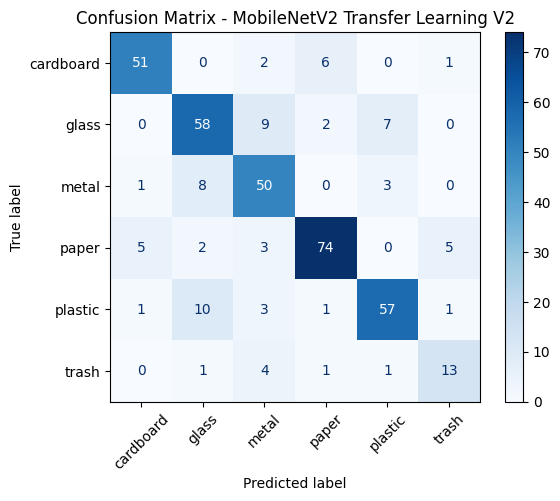

In [48]:
# ============================================================
# 57. CONFUSION MATRIX MOBILENETV2 V2
# ============================================================

cm_v2 = confusion_matrix(
    y_true_v2,
    y_pred_v2
)

disp_v2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=class_names
)

plt.figure(figsize=(8, 8))
disp_v2.plot(
    cmap="Blues",
    xticks_rotation=45
)
plt.title("Confusion Matrix - MobileNetV2 Transfer Learning V2")
plt.show()

Confusion matrix digunakan untuk melihat detail prediksi benar dan salah pada setiap kelas. Nilai diagonal menunjukkan jumlah gambar yang berhasil diprediksi dengan benar.

Pada MobileNetV2 V2, kelas dengan prediksi benar paling tinggi adalah `paper`, yaitu **74 gambar**. Kelas `glass` memiliki **58 prediksi benar**, `plastic` memiliki **57 prediksi benar**, `cardboard` memiliki **51 prediksi benar**, `metal` memiliki **50 prediksi benar**, dan `trash` memiliki **13 prediksi benar**.

Kelas `trash` mengalami peningkatan dibandingkan V1, karena pada V2 terdapat **13 gambar trash** yang benar diprediksi, sedangkan sebelumnya hanya **11 gambar**. Ini menunjukkan bahwa penambahan bobot pada kelas `trash` membantu model mengenali kelas tersebut dengan lebih baik.

Namun, kelas `glass` masih cukup sering tertukar dengan kelas lain. Terdapat **9 gambar glass** yang diprediksi sebagai `metal` dan **7 gambar glass** yang diprediksi sebagai `plastic`. Hal ini menunjukkan bahwa model masih kesulitan membedakan glass dengan material yang memiliki tampilan mirip, seperti metal dan plastic.

Kelas `plastic` juga cukup sering tertukar dengan `glass`, yaitu sebanyak **10 gambar plastic** diprediksi sebagai glass. Ini menunjukkan adanya kemiripan visual antara plastik transparan dan kaca.

Secara keseluruhan, confusion matrix V2 menunjukkan bahwa model cukup baik dalam mengenali `paper`, `glass`, `plastic`, `cardboard`, dan `metal`. Kelas `trash` masih menjadi kelas yang paling sulit, tetapi sudah mengalami peningkatan dibandingkan V1.

In [49]:
# ============================================================
# 58. SAVE MODEL MOBILENETV2 V2
# ============================================================

transfer_model_v2.save("final_mobilenetv2_transfer_learning_v2.keras")

print("Model V2 berhasil disimpan.")

Model V2 berhasil disimpan.


Model MobileNetV2 V2 disimpan ke dalam file `final_mobilenetv2_transfer_learning_v2.keras`. Penyimpanan ini dilakukan agar model yang sudah selesai dilatih dan dievaluasi dapat digunakan kembali tanpa perlu melakukan training ulang.

# Visualisasi dan Perbandingan Model

Setelah semua model selesai dilatih, tahap berikutnya adalah menggabungkan riwayat training dan melakukan visualisasi performa model. Visualisasi ini digunakan untuk melihat perkembangan accuracy dan loss selama training, baik pada fase frozen maupun fine-tuning.

Selain itu, bagian ini juga digunakan untuk membandingkan performa beberapa model, yaitu Baseline CNN, Improved CNN, MobileNetV2 V1, dan MobileNetV2 V2, sehingga dapat ditentukan model mana yang memberikan hasil terbaik.

In [50]:
# ============================================================
# 59. FUNGSI GABUNG HISTORY PHASE 1 DAN PHASE 2
# ============================================================

def combine_history(history_1, history_2):
    combined = {}

    for key in history_1.history.keys():
        if key in history_2.history:
            combined[key] = history_1.history[key] + history_2.history[key]

    return combined


combined_history_v1 = combine_history(history_frozen_v1, history_finetune_v1)
combined_history_v2 = combine_history(history_frozen_v2, history_finetune_v2)

print("History V1 keys:", combined_history_v1.keys())
print("History V2 keys:", combined_history_v2.keys())

History V1 keys: dict_keys(['accuracy', 'loss', 'precision', 'recall', 'val_accuracy', 'val_loss', 'val_precision', 'val_recall', 'learning_rate'])
History V2 keys: dict_keys(['accuracy', 'loss', 'precision', 'recall', 'val_accuracy', 'val_loss', 'val_precision', 'val_recall', 'learning_rate'])


Fungsi `combine_history()` digunakan untuk menggabungkan history dari dua fase training, yaitu fase frozen dan fase fine-tuning. Penggabungan ini diperlukan karena MobileNetV2 dilatih dalam dua tahap, sehingga riwayat training-nya tersimpan pada dua variabel yang berbeda.

Dengan menggabungkan kedua history tersebut, kurva training dapat ditampilkan secara utuh dari awal sampai akhir. Hal ini memudahkan analisis apakah performa model meningkat, stabil, atau mulai mengalami overfitting setelah fine-tuning dilakukan.

Hasil output menunjukkan bahwa history V1 dan V2 memiliki metrik yang lengkap, seperti `accuracy`, `loss`, `precision`, `recall`, `val_accuracy`, `val_loss`, `val_precision`, `val_recall`, dan `learning_rate`. Artinya, data training sudah siap digunakan untuk visualisasi dan perbandingan model.

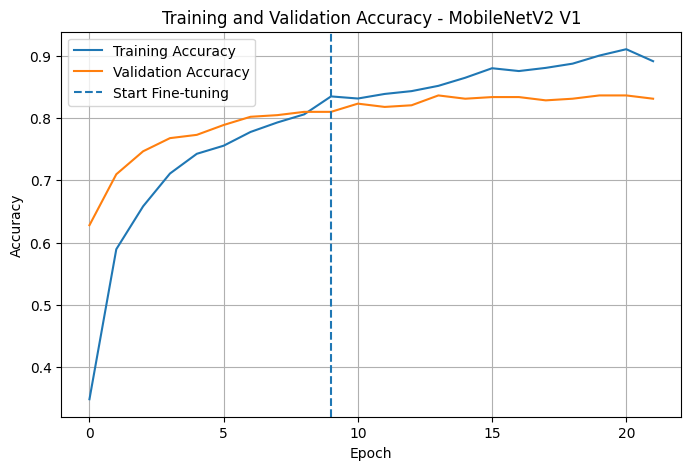

In [51]:
# ============================================================
# 60. PLOT ACCURACY MOBILENETV2 V1
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    combined_history_v1["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    combined_history_v1["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=FROZEN_EPOCHS_V1 - 1,
    linestyle="--",
    label="Start Fine-tuning"
)

plt.title("Training and Validation Accuracy - MobileNetV2 V1")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Grafik ini menunjukkan perkembangan **training accuracy** dan **validation accuracy** pada MobileNetV2 V1 selama proses training.

Pada fase awal, training accuracy meningkat cukup cepat dari sekitar **0.35** hingga mendekati **0.81**. Validation accuracy juga ikut meningkat dari sekitar **0.63** sampai sekitar **0.81**. Hal ini menunjukkan bahwa classification head berhasil belajar dari fitur yang sudah diekstraksi oleh MobileNetV2.

Garis vertikal putus-putus menunjukkan titik mulai **fine-tuning**. Setelah fine-tuning dimulai, training accuracy masih terus meningkat hingga mendekati **0.90**. Namun, validation accuracy hanya naik sedikit dan cenderung stabil di sekitar **0.82–0.84**.

Perbedaan antara training accuracy dan validation accuracy mulai terlihat setelah fine-tuning. Training accuracy lebih tinggi daripada validation accuracy, yang menunjukkan bahwa model mulai belajar lebih detail pada data training. Namun, karena validation accuracy masih stabil dan tidak turun drastis, overfitting yang terjadi masih tergolong ringan.

Secara keseluruhan, grafik ini menunjukkan bahwa MobileNetV2 V1 belajar dengan baik. Fase frozen membantu model mencapai performa awal yang cukup tinggi, sedangkan fine-tuning memberikan sedikit peningkatan tambahan pada validation accuracy.

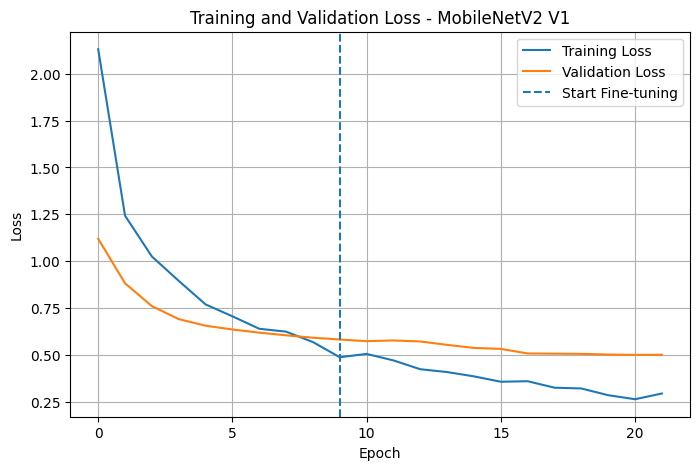

In [52]:
# ============================================================
# 61. PLOT LOSS MOBILENETV2 V1
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    combined_history_v1["loss"],
    label="Training Loss"
)

plt.plot(
    combined_history_v1["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=FROZEN_EPOCHS_V1 - 1,
    linestyle="--",
    label="Start Fine-tuning"
)

plt.title("Training and Validation Loss - MobileNetV2 V1")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Grafik ini menunjukkan perubahan **training loss** dan **validation loss** pada MobileNetV2 V1 selama proses training.

Pada awal training, training loss turun sangat cepat dari sekitar **2.1** menjadi di bawah **0.6**. Validation loss juga ikut turun dari sekitar **1.1** menjadi sekitar **0.58**. Penurunan ini menunjukkan bahwa model berhasil belajar dan kesalahan prediksi semakin berkurang.

Garis vertikal putus-putus menunjukkan awal proses **fine-tuning**. Setelah fine-tuning dimulai, training loss terus menurun hingga sekitar **0.3**, sedangkan validation loss cenderung stabil di sekitar **0.5**.

Perbedaan antara training loss dan validation loss menunjukkan bahwa model mulai lebih menyesuaikan diri dengan data training. Namun, karena validation loss tidak naik secara drastis, overfitting masih tergolong ringan.

Secara keseluruhan, grafik ini menunjukkan bahwa MobileNetV2 V1 memiliki proses training yang cukup stabil. Fase frozen berhasil menurunkan loss secara besar, sedangkan fine-tuning membantu menurunkan training loss lebih lanjut meskipun peningkatan pada validation loss tidak terlalu besar.

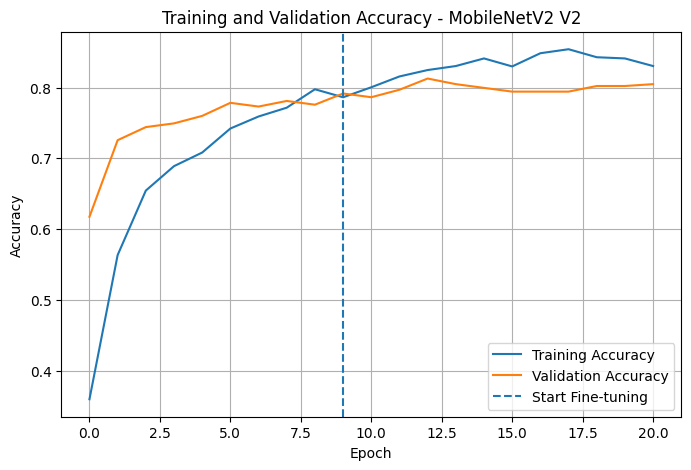

In [53]:
# ============================================================
# 62. PLOT ACCURACY MOBILENETV2 V2
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    combined_history_v2["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    combined_history_v2["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=FROZEN_EPOCHS_V2 - 1,
    linestyle="--",
    label="Start Fine-tuning"
)

plt.title("Training and Validation Accuracy - MobileNetV2 V2")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Grafik ini menunjukkan perkembangan **training accuracy** dan **validation accuracy** pada MobileNetV2 V2 selama proses training.

Pada fase awal, training accuracy meningkat dari sekitar **0.36** menjadi sekitar **0.79**. Validation accuracy juga meningkat dari sekitar **0.62** menjadi sekitar **0.79**. Hal ini menunjukkan bahwa classification head berhasil belajar dari fitur yang dihasilkan oleh MobileNetV2.

Garis vertikal putus-putus menunjukkan awal proses **fine-tuning**. Setelah fine-tuning dimulai, training accuracy masih naik hingga sekitar **0.85**, tetapi validation accuracy hanya meningkat sedikit dan cenderung stabil di sekitar **0.80–0.81**.

Perbedaan antara training accuracy dan validation accuracy tidak terlalu besar, sehingga model V2 terlihat cukup stabil. Namun, peningkatan validation accuracy setelah fine-tuning tidak terlalu signifikan. Ini menunjukkan bahwa strategi V2 yang lebih konservatif membantu menjaga stabilitas training, tetapi belum memberikan peningkatan performa yang besar dibandingkan fase frozen.

Secara keseluruhan, MobileNetV2 V2 mampu belajar dengan cukup baik, tetapi performa validasinya cenderung stagnan setelah fine-tuning. Model tidak mengalami overfitting berat, namun peningkatan akurasinya juga lebih terbatas dibandingkan V1.

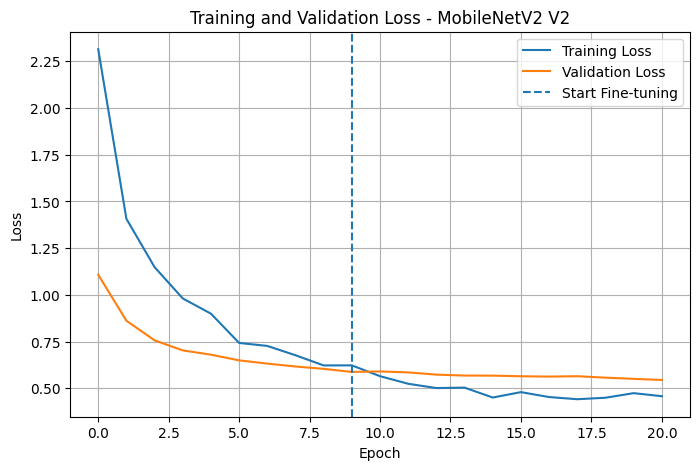

In [54]:
# ============================================================
# 63. PLOT LOSS MOBILENETV2 V2
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    combined_history_v2["loss"],
    label="Training Loss"
)

plt.plot(
    combined_history_v2["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=FROZEN_EPOCHS_V2 - 1,
    linestyle="--",
    label="Start Fine-tuning"
)

plt.title("Training and Validation Loss - MobileNetV2 V2")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Grafik ini menunjukkan perubahan **training loss** dan **validation loss** pada MobileNetV2 V2 selama proses training.

Pada fase awal, training loss turun cukup cepat dari sekitar **2.3** menjadi sekitar **0.6**. Validation loss juga ikut menurun dari sekitar **1.1** menjadi sekitar **0.59**. Hal ini menunjukkan bahwa model berhasil belajar dan kesalahan prediksi semakin berkurang.

Garis vertikal putus-putus menunjukkan awal proses **fine-tuning**. Setelah fine-tuning dimulai, training loss masih terus menurun hingga sekitar **0.45**, sedangkan validation loss cenderung stabil di sekitar **0.55**.

Perbedaan antara training loss dan validation loss tidak terlalu besar, sehingga model V2 terlihat cukup stabil dan tidak menunjukkan overfitting yang berat. Namun, validation loss juga tidak turun banyak setelah fine-tuning, sehingga peningkatan performa model pada data validation cukup terbatas.

Secara keseluruhan, MobileNetV2 V2 memiliki proses training yang stabil, tetapi fine-tuning tidak memberikan peningkatan loss yang terlalu signifikan dibandingkan fase frozen.

In [55]:
# ============================================================
# 64. PERBANDINGAN MODEL FINAL
# ============================================================

v1_training_time = frozen_training_time_v1 + finetune_training_time_v1
v2_training_time = frozen_training_time_v2 + finetune_training_time_v2

comparison_all_df = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Improved CNN",
        "MobileNetV2 V1",
        "MobileNetV2 V2"
    ],
    "Test Loss": [
        1.191789,
        0.586481,
        v1_test_loss,
        v2_test_loss
    ],
    "Test Accuracy": [
        0.547368,
        0.802632,
        v1_test_accuracy,
        v2_test_accuracy
    ],
    "Test Precision": [
        0.739362,
        0.871473,
        v1_test_precision,
        v2_test_precision
    ],
    "Test Recall": [
        0.365789,
        0.731579,
        v1_test_recall,
        v2_test_recall
    ],
    "Training Time (seconds)": [
        371.33,
        11892.25,
        v1_training_time,
        v2_training_time
    ]
})

comparison_all_df

,Model,Test Loss,Test Accuracy,Test Precision,Test Recall,Training Time (seconds)
0,Baseline CNN,1.191789,0.547368,0.739362,0.365789,371.330000
1,Improved CNN,0.586481,0.802632,0.871473,0.731579,11892.250000
2,MobileNetV2 V1,0.548898,0.813158,0.840456,0.776316,669.819063
3,MobileNetV2 V2,0.559108,0.797368,0.806630,0.768421,670.168866


Tabel ini digunakan untuk membandingkan performa akhir dari empat model, yaitu **Baseline CNN**, **Improved CNN**, **MobileNetV2 V1**, dan **MobileNetV2 V2**.

Berdasarkan hasil perbandingan, **MobileNetV2 V1** menjadi model dengan performa terbaik secara keseluruhan. Model ini memperoleh **test accuracy sebesar 0.8132**, **precision sebesar 0.8405**, dan **recall sebesar 0.7763**. Hasil ini menunjukkan bahwa MobileNetV2 V1 mampu memberikan keseimbangan performa yang baik antara ketepatan prediksi dan kemampuan mengenali data dari setiap kelas.

**Improved CNN** juga memiliki performa yang cukup baik dengan test accuracy sebesar **0.8026**, tetapi masih sedikit lebih rendah dibandingkan MobileNetV2 V1. Sementara itu, **MobileNetV2 V2** memiliki test accuracy sebesar **0.7974**, sehingga performanya sedikit di bawah V1 dan Improved CNN.

**Baseline CNN** memiliki performa paling rendah dengan test accuracy sebesar **0.5474**. Hal ini menunjukkan bahwa CNN sederhana belum cukup kuat untuk menangkap fitur visual kompleks pada dataset gambar sampah.

Dari sisi training time, MobileNetV2 membutuhkan waktu training lebih lama dibandingkan CNN biasa karena menggunakan arsitektur pretrained yang lebih kompleks dan memiliki dua fase training, yaitu frozen dan fine-tuning. Namun, waktu training yang lebih panjang ini memberikan hasil performa yang lebih baik.

Secara keseluruhan, **MobileNetV2 V1 dipilih sebagai model terbaik** karena memiliki test accuracy, precision, dan recall tertinggi dibandingkan model lainnya.

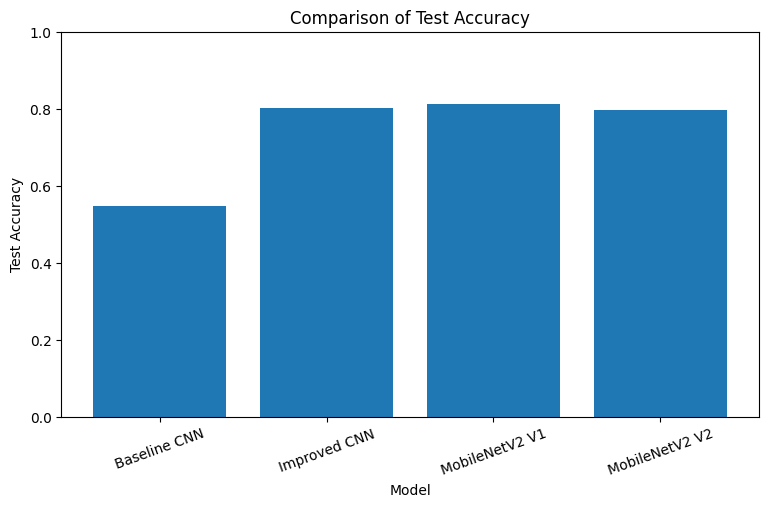

In [56]:
# ============================================================
# 65. VISUALISASI PERBANDINGAN TEST ACCURACY
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_all_df["Model"],
    comparison_all_df["Test Accuracy"]
)

plt.title("Comparison of Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

Grafik ini menampilkan perbandingan **test accuracy** dari empat model, yaitu Baseline CNN, Improved CNN, MobileNetV2 V1, dan MobileNetV2 V2.

Berdasarkan grafik, **Baseline CNN** memiliki test accuracy paling rendah, yaitu sekitar **0.55**. Hal ini menunjukkan bahwa arsitektur CNN sederhana belum cukup kuat untuk mengenali pola visual pada dataset gambar sampah.

**Improved CNN** mengalami peningkatan besar dibandingkan Baseline CNN, dengan test accuracy sekitar **0.80**. Peningkatan ini menunjukkan bahwa modifikasi seperti penambahan layer, BatchNormalization, Dropout, dan GlobalAveragePooling2D membantu model belajar lebih baik.

**MobileNetV2 V1** memiliki test accuracy tertinggi, yaitu sekitar **0.81**. Model ini menjadi yang terbaik karena memanfaatkan transfer learning dari MobileNetV2 dan fine-tuning yang cukup efektif.

**MobileNetV2 V2** juga memiliki performa yang baik dengan test accuracy sekitar **0.80**, tetapi masih sedikit lebih rendah dibandingkan V1. Hal ini menunjukkan bahwa strategi V2 yang lebih konservatif belum berhasil mengungguli V1.

Secara keseluruhan, grafik ini menunjukkan bahwa model berbasis transfer learning, terutama **MobileNetV2 V1**, memberikan performa terbaik dibandingkan CNN yang dibuat dari awal.

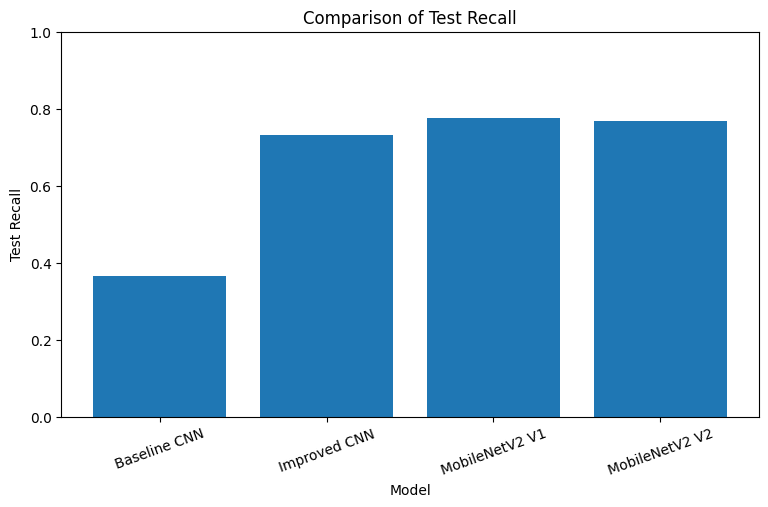

In [57]:
# ============================================================
# 66. VISUALISASI PERBANDINGAN TEST RECALL
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_all_df["Model"],
    comparison_all_df["Test Recall"]
)

plt.title("Comparison of Test Recall")
plt.xlabel("Model")
plt.ylabel("Test Recall")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

Grafik ini menampilkan perbandingan **test recall** dari empat model, yaitu Baseline CNN, Improved CNN, MobileNetV2 V1, dan MobileNetV2 V2.

**Baseline CNN** memiliki test recall paling rendah, yaitu sekitar **0.37**. Artinya, model baseline masih banyak gagal mengenali gambar dari kelas sebenarnya.

**Improved CNN** menunjukkan peningkatan yang cukup besar dengan test recall sekitar **0.73**. Hal ini menunjukkan bahwa modifikasi arsitektur CNN membantu model mengenali lebih banyak data dengan benar.

**MobileNetV2 V1** memiliki test recall tertinggi, yaitu sekitar **0.78**. Ini menunjukkan bahwa V1 paling baik dalam menemukan atau mengenali gambar dari kelas sebenarnya.

**MobileNetV2 V2** juga memiliki recall yang tinggi, sekitar **0.77**, tetapi masih sedikit di bawah V1.

Secara keseluruhan, grafik ini menunjukkan bahwa **MobileNetV2 V1 adalah model terbaik dari sisi recall**, karena paling mampu mengenali data aktual pada test set dibandingkan model lainnya.

In [58]:
# ============================================================
# 67. PERBANDINGAN PER CLASS V1 DAN V2
# ============================================================

report_v1 = classification_report(
    y_true_v1,
    y_pred_v1,
    target_names=class_names,
    output_dict=True
)

report_v2 = classification_report(
    y_true_v2,
    y_pred_v2,
    target_names=class_names,
    output_dict=True
)

per_class_comparison = []

for class_name in class_names:
    per_class_comparison.append({
        "Class": class_name,
        "V1 Precision": report_v1[class_name]["precision"],
        "V1 Recall": report_v1[class_name]["recall"],
        "V1 F1-score": report_v1[class_name]["f1-score"],
        "V2 Precision": report_v2[class_name]["precision"],
        "V2 Recall": report_v2[class_name]["recall"],
        "V2 F1-score": report_v2[class_name]["f1-score"],
    })

per_class_comparison_df = pd.DataFrame(per_class_comparison)

per_class_comparison_df

,Class,V1 Precision,V1 Recall,V1 F1-score,V2 Precision,V2 Recall,V2 F1-score
0,cardboard,0.841270,0.883333,0.861789,0.879310,0.850000,0.864407
1,glass,0.833333,0.789474,0.810811,0.734177,0.763158,0.748387
2,metal,0.717949,0.903226,0.800000,0.704225,0.806452,0.751880
3,paper,0.920000,0.775281,0.841463,0.880952,0.831461,0.855491
4,plastic,0.821918,0.821918,0.821918,0.838235,0.780822,0.808511
5,trash,0.578947,0.550000,0.564103,0.650000,0.650000,0.650000


Tabel ini membandingkan performa **MobileNetV2 V1** dan **MobileNetV2 V2** pada setiap kelas menggunakan metrik precision, recall, dan f1-score.

Secara umum, **V1 lebih unggul pada sebagian besar kelas**, terutama pada `glass`, `metal`, dan `plastic`. Pada kelas `glass`, V1 memiliki f1-score **0.81**, sedangkan V2 turun menjadi **0.75**. Hal ini menunjukkan bahwa strategi V1 yang fokus menaikkan bobot kelas `glass` lebih efektif untuk mengenali kelas tersebut.

Pada kelas `metal`, V1 juga lebih baik dengan recall **0.90** dan f1-score **0.80**, sedangkan V2 memiliki recall **0.81** dan f1-score **0.75**. Artinya, V1 lebih mampu mengenali gambar metal dengan benar.

Namun, **V2 lebih baik pada kelas `trash`**. Pada V1, f1-score kelas `trash` hanya **0.56**, sedangkan pada V2 meningkat menjadi **0.65**. Ini menunjukkan bahwa penambahan bobot untuk kelas `trash` pada V2 berhasil membantu model mengenali kelas tersebut dengan lebih baik.

Kelas `paper` juga sedikit lebih baik pada V2, dengan f1-score **0.86**, dibandingkan V1 yang memperoleh **0.84**. Sementara itu, kelas `cardboard` relatif stabil pada kedua model, dengan f1-score sekitar **0.86**.

Secara keseluruhan, V2 berhasil memperbaiki performa pada kelas `trash`, tetapi menyebabkan penurunan pada beberapa kelas lain, terutama `glass` dan `metal`. Karena performa keseluruhan V1 masih lebih tinggi, MobileNetV2 V1 tetap menjadi model terbaik secara umum.

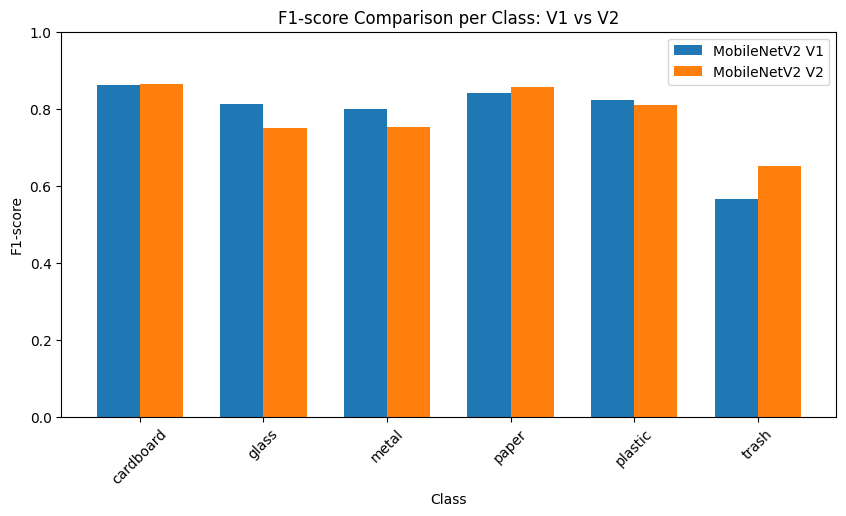

In [59]:
# ============================================================
# 68. VISUALISASI PERBANDINGAN F1-SCORE PER CLASS V1 DAN V2
# ============================================================

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    per_class_comparison_df["V1 F1-score"],
    width,
    label="MobileNetV2 V1"
)

plt.bar(
    x + width / 2,
    per_class_comparison_df["V2 F1-score"],
    width,
    label="MobileNetV2 V2"
)

plt.title("F1-score Comparison per Class: V1 vs V2")
plt.xlabel("Class")
plt.ylabel("F1-score")
plt.xticks(x, class_names, rotation=45)
plt.ylim(0, 1)
plt.legend()
plt.show()

Grafik ini membandingkan **F1-score** antara MobileNetV2 V1 dan MobileNetV2 V2 untuk setiap kelas. F1-score digunakan karena menggabungkan precision dan recall, sehingga cocok untuk melihat keseimbangan performa model pada masing-masing kelas.

Berdasarkan grafik, kelas `cardboard` memiliki performa yang hampir sama pada V1 dan V2, dengan F1-score sekitar **0.86**. Kelas `paper` sedikit lebih baik pada V2, yaitu sekitar **0.86**, dibandingkan V1 yang sekitar **0.84**.

Namun, V1 lebih unggul pada kelas `glass`, `metal`, dan `plastic`. Pada kelas `glass`, F1-score V1 lebih tinggi dibandingkan V2, yang menunjukkan bahwa V1 lebih baik dalam mengenali kaca secara seimbang antara precision dan recall. Hal yang sama juga terlihat pada kelas `metal` dan `plastic`.

Perbedaan paling terlihat ada pada kelas `trash`. Pada V1, F1-score kelas `trash` sekitar **0.56**, sedangkan pada V2 meningkat menjadi sekitar **0.65**. Ini menunjukkan bahwa penambahan bobot kelas `trash` pada V2 berhasil meningkatkan performa model untuk kelas tersebut.

Secara keseluruhan, grafik ini menunjukkan bahwa V2 berhasil memperbaiki performa pada kelas `trash`, tetapi V1 masih lebih unggul pada beberapa kelas lain seperti `glass`, `metal`, dan `plastic`. Karena itu, secara keseluruhan MobileNetV2 V1 tetap lebih stabil sebagai model final.

# Attention Map / Grad-CAM

Grad-CAM digunakan untuk melihat bagian gambar yang paling diperhatikan oleh model ketika melakukan prediksi. Visualisasi ini penting agar hasil model tidak hanya dilihat dari angka accuracy atau recall saja, tetapi juga dari cara model mengambil keputusan.

Dengan Grad-CAM, dapat dilihat apakah model benar-benar fokus pada objek sampah, atau justru lebih banyak fokus pada background, bayangan, warna, atau area lain yang kurang relevan. Hal ini membantu proses interpretability, yaitu memahami alasan di balik prediksi model.

In [60]:
# Pilih model transfer learning yang ingin dianalisis dengan Grad-CAM
transfer_model = transfer_model_v2
base_model = base_model_v2

print("Transfer model yang digunakan:", transfer_model.name)
print("Base model yang digunakan:", base_model.name)

Transfer model yang digunakan: mobilenetv2_transfer_learning_v2
Base model yang digunakan: mobilenetv2_1.00_224


Pada tahap ini dipilih model transfer learning yang akan dianalisis menggunakan Grad-CAM. Model yang digunakan adalah `transfer_model_v2` dengan base model `base_model_v2`.

`transfer_model_v2` merupakan model MobileNetV2 V2 yang sudah dilatih pada dataset klasifikasi sampah, sedangkan `base_model_v2` adalah bagian MobileNetV2 yang digunakan sebagai feature extractor. Base model ini diperlukan karena Grad-CAM membutuhkan convolution layer terakhir untuk menghasilkan heatmap.

Output menunjukkan bahwa model yang digunakan adalah `mobilenetv2_transfer_learning_v2`, dengan base model `mobilenetv2_1.00_224`. Artinya, proses Grad-CAM akan dilakukan pada model MobileNetV2 V2.

In [61]:
# Pilih model transfer learning yang ingin dianalisis
# Karena model yang lebih bagus adalah V2, kita gunakan transfer_model_v2 dan base_model_v2

transfer_model = transfer_model_v2
base_model = base_model_v2

print("Transfer model yang digunakan:", transfer_model.name)
print("Base model yang digunakan:", base_model.name)

Transfer model yang digunakan: mobilenetv2_transfer_learning_v2
Base model yang digunakan: mobilenetv2_1.00_224


Model yang digunakan untuk analisis Grad-CAM adalah `transfer_model_v2` dan `base_model_v2`. `transfer_model_v2` merupakan model MobileNetV2 V2 yang sudah dilatih untuk klasifikasi gambar sampah, sedangkan `base_model_v2` adalah bagian MobileNetV2 yang berfungsi sebagai feature extractor.

Output menunjukkan bahwa model yang dipakai adalah `mobilenetv2_transfer_learning_v2`, dengan base model `mobilenetv2_1.00_224`. Artinya, Grad-CAM akan mengambil informasi dari struktur convolutional MobileNetV2 V2 untuk melihat area gambar yang paling memengaruhi prediksi model.

In [62]:
# Pastikan IMG_SIZE berbentuk tuple, misalnya (224, 224)

print("IMG_SIZE:", IMG_SIZE)
print("Transfer model input shape:", transfer_model.input_shape)
print("Transfer model output shape:", transfer_model.output_shape)

IMG_SIZE: (224, 224)
Transfer model input shape: (None, 224, 224, 3)
Transfer model output shape: (None, 6)


Pengecekan `IMG_SIZE`, input shape, dan output shape dilakukan untuk memastikan bahwa dimensi data sudah sesuai sebelum Grad-CAM dijalankan.

Hasil output menunjukkan bahwa `IMG_SIZE` adalah `(224, 224)`, sehingga gambar yang masuk ke model berukuran 224 x 224 pixel. Input shape model adalah `(None, 224, 224, 3)`, yang berarti model menerima gambar RGB dengan 3 channel warna.

Output shape model adalah `(None, 6)`, yang menunjukkan bahwa model menghasilkan prediksi untuk 6 kelas, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Dengan hasil ini, model sudah memiliki format input dan output yang sesuai untuk proses Grad-CAM.

In [63]:
# ============================================================
# B. CEK DAN SIAPKAN LABEL MAPPING
# ============================================================

# Pastikan index_to_class tersedia.
# Kalau belum ada, kode ini akan mencoba membuatnya dari class_names.

if "index_to_class" not in globals():
    if "class_names" in globals():
        index_to_class = {i: class_name for i, class_name in enumerate(class_names)}
        print("index_to_class berhasil dibuat dari class_names.")
    elif "train_ds" in globals() and hasattr(train_ds, "class_names"):
        index_to_class = {i: class_name for i, class_name in enumerate(train_ds.class_names)}
        print("index_to_class berhasil dibuat dari train_ds.class_names.")
    elif "train_data" in globals() and hasattr(train_data, "class_names"):
        index_to_class = {i: class_name for i, class_name in enumerate(train_data.class_names)}
        print("index_to_class berhasil dibuat dari train_data.class_names.")
    else:
        raise ValueError(
            "index_to_class belum tersedia. Buat dulu mapping label, misalnya:\n"
            "index_to_class = {0:'cardboard', 1:'glass', 2:'metal', 3:'paper', 4:'plastic', 5:'trash'}"
        )

print("Index to class mapping:")
print(index_to_class)

Index to class mapping:
{0: 'cardboard', 1: 'glass', 2: 'metal', 3: 'paper', 4: 'plastic', 5: 'trash'}


Label mapping digunakan untuk menghubungkan index hasil prediksi model dengan nama kelas aslinya. Karena output model berbentuk probabilitas untuk setiap index kelas, mapping ini diperlukan agar hasil prediksi dapat ditampilkan dalam bentuk nama kelas seperti `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Variabel `index_to_class` dicek terlebih dahulu. Jika belum tersedia, mapping akan dibuat otomatis dari `class_names`, `train_ds.class_names`, atau `train_data.class_names` jika salah satunya tersedia.

Hasil output menunjukkan bahwa mapping sudah berhasil dibuat, yaitu:

`0: cardboard`, `1: glass`, `2: metal`, `3: paper`, `4: plastic`, dan `5: trash`.

Mapping ini akan digunakan pada proses Grad-CAM untuk menampilkan label prediksi model secara jelas.

In [ ]:
# BUAT FOLDER OUTPUT ATTENTION MAP
transfer_attention_output_dir = Path("transfer_attention_outputs")
transfer_attention_output_dir.mkdir(exist_ok=True)

transfer_attention_correct_dir = transfer_attention_output_dir / "correct_predictions"
transfer_attention_correct_dir.mkdir(exist_ok=True)

transfer_attention_wrong_dir = transfer_attention_output_dir / "wrong_predictions"
transfer_attention_wrong_dir.mkdir(exist_ok=True)

transfer_attention_glass_dir = transfer_attention_output_dir / "glass_predictions"
transfer_attention_glass_dir.mkdir(exist_ok=True)

transfer_attention_high_conf_wrong_dir = transfer_attention_output_dir / "high_confidence_wrong_predictions"
transfer_attention_high_conf_wrong_dir.mkdir(exist_ok=True)

print("Folder output attention map berhasil dibuat:")
print(transfer_attention_output_dir)

Folder output attention map berhasil dibuat:
transfer_attention_outputs


Folder output dibuat untuk menyimpan hasil visualisasi Grad-CAM dari model transfer learning. Folder utama yang digunakan adalah `transfer_attention_outputs`.

Di dalam folder utama tersebut, dibuat beberapa subfolder sesuai jenis hasil analisis, yaitu:

`correct_predictions` untuk menyimpan attention map dari prediksi yang benar.

`wrong_predictions` untuk menyimpan attention map dari prediksi yang salah.

`glass_predictions` untuk menyimpan attention map khusus pada kelas `glass`.

`high_confidence_wrong_predictions` untuk menyimpan attention map dari prediksi yang salah tetapi memiliki confidence tinggi.

Pemisahan folder ini membuat hasil Grad-CAM lebih rapi dan mudah dianalisis. Dengan struktur folder tersebut, gambar hasil interpretasi model dapat dikelompokkan berdasarkan tujuan evaluasinya.

In [ ]:
# FUNGSI LOAD IMAGE UNTUK TRANSFER ATTENTION MAP
def load_image_for_transfer_attention(image_path):
    """
    Membaca gambar dari path, mengubah ukuran gambar sesuai IMG_SIZE,
    dan melakukan normalisasi ke rentang 0 sampai 1.
    """

    image_path = str(image_path)

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32) / 255.0

    return image

Fungsi `load_image_for_transfer_attention()` digunakan untuk membaca dan menyiapkan gambar sebelum diproses oleh model transfer learning dan Grad-CAM.

Gambar dibaca dari `image_path`, lalu di-decode menjadi gambar RGB dengan 3 channel warna. Setelah itu, gambar diubah ukurannya sesuai `IMG_SIZE`, yaitu ukuran input yang digunakan oleh model.

Nilai pixel gambar kemudian diubah ke tipe `float32` dan dinormalisasi ke rentang **0 sampai 1** dengan membagi nilai pixel menggunakan 255.0. Normalisasi ini dilakukan agar format gambar sesuai dengan input model.

Output dari fungsi ini adalah gambar yang sudah siap digunakan untuk prediksi dan pembuatan attention map.

In [ ]:
# CARI LAST CONVOLUTION LAYER PADA BASE MODEL
def find_last_conv_layer(model):
    """
    Mencari Conv2D layer terakhir pada base model.
    Conv2D terakhir biasanya paling cocok untuk Grad-CAM
    karena masih menyimpan informasi spasial dan fitur visual tingkat tinggi.
    """

    last_conv_layer = None

    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.Conv2D):
            last_conv_layer = layer

    return last_conv_layer

Fungsi `find_last_conv_layer()` digunakan untuk mencari layer convolution terakhir pada base model. Layer convolution terakhir penting dalam Grad-CAM karena layer ini masih menyimpan informasi spasial gambar, seperti posisi dan area objek yang diperhatikan model.

Fungsi ini mengecek setiap layer dalam model, lalu mencari layer yang bertipe `Conv2D`. Setiap kali ditemukan layer convolution, layer tersebut disimpan sebagai `last_conv_layer`. Karena pengecekan dilakukan dari awal sampai akhir, hasil akhirnya adalah convolution layer terakhir yang ditemukan.

Layer convolution terakhir biasanya paling cocok digunakan untuk Grad-CAM karena sudah menangkap fitur visual tingkat tinggi, tetapi masih mempertahankan informasi lokasi pada gambar. Dengan layer ini, Grad-CAM dapat menunjukkan area gambar mana yang paling berpengaruh terhadap prediksi model.

In [67]:
# Cek semua layer pada base_model
print("Daftar layer pada base_model:")
print("-" * 60)

for layer in base_model.layers:
    print(layer.name, type(layer))

Daftar layer pada base_model:
------------------------------------------------------------
input_layer_3 <class 'keras.src.layers.core.input_layer.InputLayer'>
Conv1 <class 'keras.src.layers.convolutional.conv2d.Conv2D'>
bn_Conv1 <class 'keras.src.layers.normalization.batch_normalization.BatchNormalization'>
Conv1_relu <class 'keras.src.layers.activations.relu.ReLU'>
expanded_conv_depthwise <class 'keras.src.layers.convolutional.depthwise_conv2d.DepthwiseConv2D'>
expanded_conv_depthwise_BN <class 'keras.src.layers.normalization.batch_normalization.BatchNormalization'>
expanded_conv_depthwise_relu <class 'keras.src.layers.activations.relu.ReLU'>
expanded_conv_project <class 'keras.src.layers.convolutional.conv2d.Conv2D'>
expanded_conv_project_BN <class 'keras.src.layers.normalization.batch_normalization.BatchNormalization'>
block_1_expand <class 'keras.src.layers.convolutional.conv2d.Conv2D'>
block_1_expand_BN <class 'keras.src.layers.normalization.batch_normalization.BatchNormalization

Daftar layer pada `base_model` ditampilkan untuk melihat struktur internal MobileNetV2 yang digunakan sebagai feature extractor.

Output menunjukkan berbagai layer di dalam MobileNetV2, seperti convolution layer, batch normalization, activation ReLU, dan depthwise convolution. Informasi ini penting karena Grad-CAM membutuhkan convolution layer terakhir untuk membuat heatmap.

Dengan melihat daftar layer, dapat dipastikan bahwa base model memiliki layer convolution yang bisa digunakan untuk proses Grad-CAM.

In [ ]:
# Cari Conv2D terakhir secara otomatis
last_conv_layer = find_last_conv_layer(base_model)

if last_conv_layer is None:
    raise ValueError(
        "Tidak ditemukan Conv2D layer pada base_model. "
        "Pastikan base_model adalah model CNN pretrained seperti MobileNetV2, EfficientNet, atau ResNet."
    )

last_conv_layer_name = last_conv_layer.name

print("Last convolution layer pada base_model:")
print(last_conv_layer_name)

Last convolution layer pada base_model:
Conv_1


Last convolution layer dicari secara otomatis menggunakan fungsi `find_last_conv_layer()`. Layer ini digunakan sebagai dasar pembuatan Grad-CAM karena masih menyimpan informasi spasial dari gambar.

Hasil output menunjukkan bahwa last convolution layer pada base model adalah `Conv_1`. Artinya, layer `Conv_1` akan digunakan untuk menghasilkan heatmap yang menunjukkan area gambar mana yang paling berpengaruh terhadap prediksi model.

Pemilihan layer convolution terakhir cocok untuk Grad-CAM karena layer ini sudah menangkap fitur visual tingkat tinggi, tetapi masih mempertahankan informasi lokasi objek pada gambar.

In [ ]:
# CEK MODEL SUDAH SIAP DIPAKAI
dummy_input = tf.zeros((1, IMG_SIZE[0], IMG_SIZE[1], 3))

_ = transfer_model(dummy_input, training=False)

print("Transfer model sudah siap untuk Attention Map / Grad-CAM.")
print("Last conv layer yang digunakan:", last_conv_layer_name)

Transfer model sudah siap untuk Attention Map / Grad-CAM.
Last conv layer yang digunakan: Conv_1


Model dicek dengan memberikan `dummy_input` berukuran sesuai input model, yaitu `(1, 224, 224, 3)`. Tujuannya adalah memastikan model sudah pernah dipanggil dan siap digunakan untuk proses Grad-CAM.

Setelah dummy input berhasil diproses, output menunjukkan bahwa transfer model sudah siap digunakan untuk Attention Map atau Grad-CAM.

Last convolution layer yang digunakan adalah `Conv_1`. Layer ini akan menjadi dasar untuk membuat heatmap, karena layer tersebut menyimpan fitur visual tingkat tinggi yang masih memiliki informasi posisi pada gambar.

In [ ]:
# FUNGSI MEMBUAT GRAD-CAM HEATMAP UNTUK TRANSFER MODEL
def make_transfer_attention_heatmap(
    img_array,
    transfer_model,
    base_model,
    last_conv_layer_name,
    pred_index=None
):
    """
    Membuat Grad-CAM heatmap untuk model transfer learning.

    Fungsi ini dibuat khusus untuk struktur transfer learning yang memiliki:
    - transfer_model sebagai model penuh
    - base_model sebagai pretrained CNN di dalam transfer_model

    Fungsi ini akan:
    1. Mengambil output dari convolution layer terakhir base_model
    2. Melanjutkan output base_model ke classifier head transfer_model
    3. Menghitung gradient kelas prediksi terhadap output convolution layer
    4. Membuat heatmap Grad-CAM
    """

    # Ambil layer convolution terakhir dari base_model
    target_conv_layer = base_model.get_layer(last_conv_layer_name)

    # Buat model extractor untuk base_model
    # Output pertama: output convolution layer terakhir
    # Output kedua  : output akhir base_model
    base_grad_model = tf.keras.models.Model(
        inputs=base_model.inputs,
        outputs=[
            target_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        x = img_array
        conv_outputs = None

        # Jalankan transfer_model layer-by-layer.
        # Saat sampai pada base_model, kita ambil conv_outputs dan base_output.
        for layer in transfer_model.layers:

            # Skip InputLayer karena tidak perlu dipanggil manual
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            # Jika layer ini adalah base_model, gunakan base_grad_model
            if layer.name == base_model.name:
                conv_outputs, x = base_grad_model(x, training=False)
                tape.watch(conv_outputs)

            else:
                try:
                    x = layer(x, training=False)
                except TypeError:
                    x = layer(x)

        predictions = x

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    if conv_outputs is None:
        raise ValueError(
            "conv_outputs tidak ditemukan. Kemungkinan base_model tidak berada langsung "
            "di dalam transfer_model.layers, atau nama base_model berbeda."
        )

    grads = tape.gradient(class_channel, conv_outputs)

    if grads is None:
        raise ValueError(
            "Gradient bernilai None. Pastikan base_model yang dipakai adalah instance yang sama "
            "dengan base model di dalam transfer_model."
        )

    # Rata-rata gradient pada dimensi batch, height, dan width
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Hilangkan batch dimension
    conv_outputs = conv_outputs[0]

    # Kalikan feature map dengan bobot gradient
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Hanya ambil kontribusi positif
    heatmap = tf.maximum(heatmap, 0)

    # Normalisasi heatmap ke rentang 0-1
    max_value = tf.reduce_max(heatmap)

    if max_value == 0:
        return heatmap.numpy()

    heatmap = heatmap / max_value

    return heatmap.numpy()

Fungsi `make_transfer_attention_heatmap()` digunakan untuk membuat heatmap Grad-CAM pada model transfer learning. Heatmap ini menunjukkan area gambar yang paling berpengaruh terhadap hasil prediksi model.

Fungsi ini menerima input berupa gambar, transfer model, base model, nama last convolution layer, dan index kelas prediksi. Last convolution layer digunakan karena layer tersebut masih menyimpan informasi spasial gambar sekaligus fitur visual tingkat tinggi.

Di dalam fungsi ini, dibuat model extractor untuk mengambil output dari convolution layer terakhir pada base model. Output layer ini kemudian diteruskan melalui layer-layer berikutnya dalam transfer model sampai menghasilkan prediksi akhir.

Grad-CAM bekerja dengan menghitung gradient dari skor kelas prediksi terhadap output convolution layer terakhir. Gradient ini menunjukkan seberapa besar pengaruh setiap feature map terhadap prediksi model.

Setelah gradient diperoleh, dilakukan proses rata-rata gradient untuk menghasilkan bobot penting dari setiap channel feature map. Bobot ini kemudian dikalikan dengan output convolution layer untuk menghasilkan heatmap.

Nilai heatmap yang negatif dihilangkan menggunakan `tf.maximum(heatmap, 0)` karena Grad-CAM hanya menampilkan area yang mendukung prediksi model. Setelah itu, heatmap dinormalisasi ke rentang 0 sampai 1 agar mudah divisualisasikan.

Hasil akhir dari fungsi ini adalah heatmap Grad-CAM yang dapat digunakan untuk melihat bagian gambar mana yang paling diperhatikan model saat membuat prediksi.

In [ ]:
# FUNGSI DISPLAY ATTENTION MAP
def display_transfer_attention_map(
    image_path,
    transfer_model,
    base_model,
    last_conv_layer_name,
    true_label=None,
    save_path=None,
    alpha=0.4
):
    """
    Menampilkan:
    1. Gambar asli
    2. Heatmap Grad-CAM
    3. Overlay heatmap pada gambar asli

    Fungsi juga mengembalikan informasi prediksi dalam bentuk dictionary.
    """

    image = load_image_for_transfer_attention(image_path)
    img_array = tf.expand_dims(image, axis=0)

    predictions = transfer_model(img_array, training=False).numpy()

    predicted_index = np.argmax(predictions[0])
    predicted_label = index_to_class[predicted_index]
    confidence = predictions[0][predicted_index]

    heatmap = make_transfer_attention_heatmap(
        img_array=img_array,
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        pred_index=predicted_index
    )

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        IMG_SIZE
    )

    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    fig = plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title(f"Original Image\nTrue Label: {true_label}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Transfer Model Attention Map")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image)
    plt.imshow(heatmap_resized, cmap="jet", alpha=alpha)
    plt.title(
        f"Overlay\nPredicted: {predicted_label}\nConfidence: {confidence:.2f}"
    )
    plt.axis("off")

    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)

        plt.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

    print("True Label      :", true_label)
    print("Predicted Label :", predicted_label)
    print("Confidence      :", round(float(confidence), 4))

    if save_path is not None:
        print("Saved to        :", save_path)

    return {
        "image_path": str(image_path),
        "true_label": true_label,
        "predicted_label": predicted_label,
        "confidence": float(confidence),
        "save_path": str(save_path) if save_path is not None else None
    }

Fungsi `display_transfer_attention_map()` digunakan untuk menampilkan hasil Grad-CAM pada satu gambar. Fungsi ini menampilkan tiga visualisasi utama, yaitu gambar asli, heatmap Grad-CAM, dan overlay antara gambar asli dengan heatmap.

Pertama, gambar dibaca dan diproses menggunakan `load_image_for_transfer_attention()`. Setelah itu, gambar diberi tambahan dimensi batch agar sesuai dengan input model.

Model kemudian melakukan prediksi terhadap gambar tersebut. Hasil prediksi diambil dari probabilitas tertinggi menggunakan `np.argmax()`, lalu index prediksi diubah menjadi nama kelas menggunakan `index_to_class`. Confidence menunjukkan seberapa yakin model terhadap prediksi tersebut.

Setelah prediksi diperoleh, fungsi `make_transfer_attention_heatmap()` digunakan untuk membuat heatmap Grad-CAM berdasarkan kelas yang diprediksi oleh model. Heatmap kemudian di-resize agar ukurannya sama dengan gambar input.

Visualisasi dibagi menjadi tiga bagian:

1. **Original Image**  
   Menampilkan gambar asli beserta true label.

2. **Transfer Model Attention Map**  
   Menampilkan heatmap Grad-CAM. Area dengan warna lebih panas menunjukkan bagian gambar yang lebih diperhatikan model.

3. **Overlay**  
   Menampilkan gabungan antara gambar asli dan heatmap. Bagian ini membantu melihat apakah model fokus pada objek utama atau justru pada background.

Jika `save_path` diberikan, hasil visualisasi akan disimpan ke folder yang sudah ditentukan. Fungsi ini juga mencetak true label, predicted label, confidence, dan lokasi penyimpanan gambar.

Output akhir fungsi berupa dictionary yang berisi `image_path`, `true_label`, `predicted_label`, `confidence`, dan `save_path`. Informasi ini berguna untuk analisis lanjutan, terutama saat membandingkan prediksi benar dan salah.

Gambar yang digunakan:
trash_images\glass\glass_001.jpg


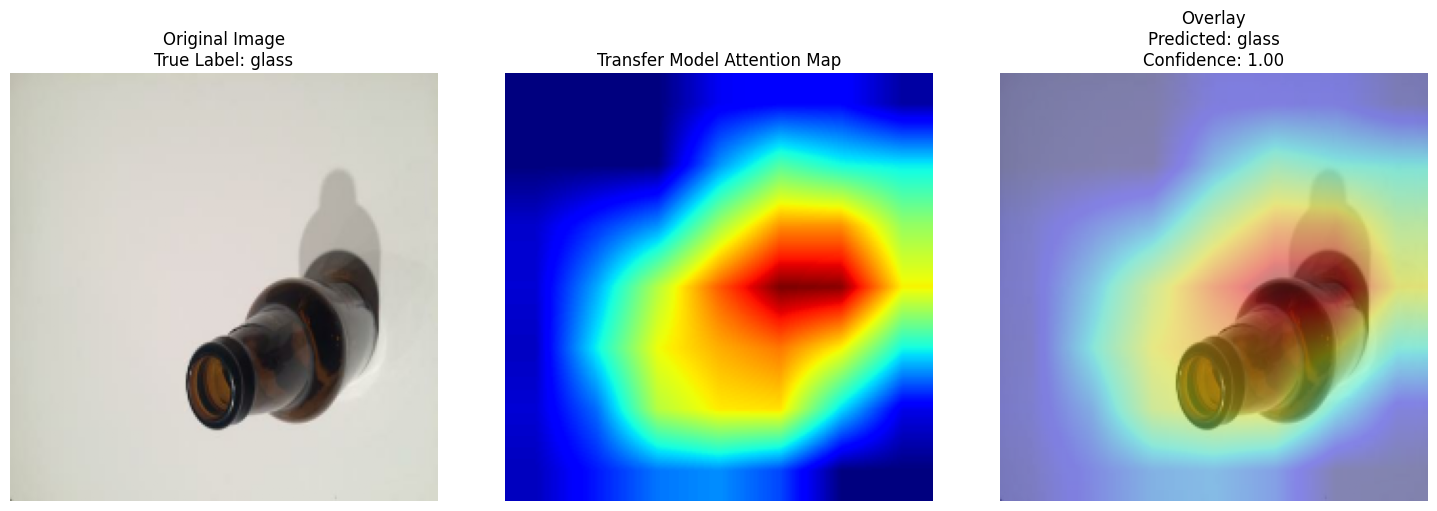

True Label      : glass
Predicted Label : glass
Confidence      : 0.9998
Saved to        : transfer_attention_outputs\sample_transfer_attention.png


{'image_path': 'trash_images\\glass\\glass_001.jpg',
 'true_label': 'glass',
 'predicted_label': 'glass',
 'confidence': 0.9997671246528625,
 'save_path': 'transfer_attention_outputs\\sample_transfer_attention.png'}

In [ ]:
# TEST ATTENTION MAP PADA SATU GAMBAR
from pathlib import Path

# Cari otomatis gambar dari kelas glass
glass_paths = []

for ext in ["*.jpg", "*.jpeg", "*.png", "*.webp"]:
    glass_paths.extend(list(Path(".").rglob(f"glass/{ext}")))

glass_paths = sorted(glass_paths)

if len(glass_paths) == 0:
    raise FileNotFoundError(
        "Tidak ada gambar glass yang ditemukan. "
        "Pastikan folder dataset berada di folder kerja notebook."
    )

sample_image_path = str(glass_paths[0])

print("Gambar yang digunakan:")
print(sample_image_path)

result_attention = display_transfer_attention_map(
    image_path=sample_image_path,
    transfer_model=transfer_model,
    base_model=base_model,
    last_conv_layer_name=last_conv_layer_name,
    true_label="glass",
    save_path=transfer_attention_output_dir / "sample_transfer_attention.png",
    alpha=0.4
)

result_attention

Grad-CAM diuji pada satu gambar contoh dari kelas `glass` untuk memastikan pipeline attention map berjalan dengan benar. Gambar yang digunakan adalah `trash_images/glass/glass_001.jpg`.

Hasil prediksi menunjukkan bahwa true label gambar adalah `glass` dan model juga memprediksi gambar tersebut sebagai `glass`. Confidence yang diperoleh sangat tinggi, yaitu sekitar **1.00**. Artinya, model sangat yakin bahwa gambar tersebut termasuk kelas `glass`.

Pada visualisasi Grad-CAM, terdapat tiga tampilan utama. Gambar pertama menunjukkan gambar asli. Gambar kedua menunjukkan heatmap attention map, yaitu area yang paling diperhatikan model. Gambar ketiga adalah overlay antara gambar asli dan heatmap.

Dari hasil overlay, area merah dan kuning terlihat berada di sekitar objek kaca. Hal ini menunjukkan bahwa model cukup fokus pada objek utama, bukan hanya pada background. Fokus model terutama berada pada bagian badan botol kaca dan area pantulan/warna gelap pada objek.

Hasil ini dapat dianggap baik karena model tidak hanya memprediksi kelas dengan benar, tetapi juga memperhatikan area yang relevan pada gambar. Dengan demikian, Grad-CAM membantu menunjukkan bahwa keputusan model cukup masuk akal secara visual.

In [ ]:
# CARI GAMBAR OTOMATIS DARI FOLDER
def get_image_paths_from_folder(folder_path, max_images=5):
    folder_path = Path(folder_path)

    image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp"]

    image_paths = []

    for ext in image_extensions:
        image_paths.extend(list(folder_path.glob(ext)))

    image_paths = sorted(image_paths)

    return image_paths[:max_images]

Fungsi `get_image_paths_from_folder()` digunakan untuk mengambil beberapa path gambar secara otomatis dari folder tertentu.

Fungsi ini menerima dua input, yaitu `folder_path` sebagai lokasi folder gambar dan `max_images` sebagai jumlah maksimal gambar yang ingin diambil. Ekstensi gambar yang dicari adalah `.jpg`, `.jpeg`, `.png`, dan `.webp`.

Setelah semua gambar ditemukan, path gambar diurutkan menggunakan `sorted()`, lalu hanya sejumlah `max_images` gambar pertama yang dikembalikan.

Fungsi ini berguna agar proses pengambilan gambar untuk Grad-CAM lebih otomatis dan tidak perlu menulis path gambar satu per satu secara manual.

In [75]:
# Contoh ambil gambar dari folder glass_images

glass_image_paths = get_image_paths_from_folder(
    folder_path="glass_images",
    max_images=5
)

print("Jumlah gambar ditemukan:", len(glass_image_paths))

for path in glass_image_paths:
    print(path)

Jumlah gambar ditemukan: 0


pada tahap ini kami mengambil maksimal 5 gambar dari folder `glass_images` menggunakan fungsi `get_image_paths_from_folder()`.

Namun, hasil output menunjukkan **jumlah gambar ditemukan = 0**. Artinya, tidak ada gambar yang berhasil ditemukan pada folder tersebut.

Hal ini kemungkinan terjadi karena folder `glass_images` tidak ada, kosong, atau bukan folder dataset asli yang digunakan. Pada dataset project ini, gambar kelas glass seharusnya berada di dalam folder seperti `trash_images/glass`, bukan `glass_images`.

Karena itu, path folder perlu disesuaikan agar fungsi dapat menemukan gambar glass yang benar dari dataset asli.

In [76]:
from pathlib import Path
import os

print("Current working directory:")
print(os.getcwd())

print("\nIsi folder sekarang:")
for item in Path(".").iterdir():
    print(item)

Current working directory:
c:\Users\USER\Documents\semt 4\Deep Learning\P

Isi folder sekarang:
Baru.ipynb
best_mobilenetv2_v1_finetuned.keras
best_mobilenetv2_v1_frozen.keras
best_mobilenetv2_v2_finetuned.keras
best_mobilenetv2_v2_frozen.keras
final_mobilenetv2_transfer_learning_v1.keras
final_mobilenetv2_transfer_learning_v2.keras
transfer_attention_outputs
trash_images


Pengecekan ini dilakukan untuk melihat lokasi notebook yang sedang aktif dan isi folder di dalamnya. Hasilnya menunjukkan bahwa notebook berada di folder project yang benar dan folder `trash_images` sudah tersedia.

In [77]:
from pathlib import Path

print("Daftar folder yang ditemukan:")

for path in Path(".").rglob("*"):
    if path.is_dir():
        print(path)

Daftar folder yang ditemukan:
transfer_attention_outputs
trash_images
transfer_attention_outputs\correct_predictions
transfer_attention_outputs\glass_predictions
transfer_attention_outputs\high_confidence_wrong_predictions
transfer_attention_outputs\wrong_predictions
trash_images\cardboard
trash_images\glass
trash_images\metal
trash_images\paper
trash_images\plastic
trash_images\trash


Pengecekan ini dilakukan untuk memastikan folder dataset dan subfolder kelas tersedia. Hasil output menunjukkan bahwa folder `trash_images` berisi kelas `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`, sehingga path dataset sudah benar untuk digunakan pada Grad-CAM.

In [78]:
from pathlib import Path

image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp"]

all_image_paths = []

for ext in image_extensions:
    all_image_paths.extend(list(Path(".").rglob(ext)))

all_image_paths = sorted(all_image_paths)

print("Jumlah total gambar ditemukan:", len(all_image_paths))

for path in all_image_paths[:30]:
    print(path)

Jumlah total gambar ditemukan: 2528
transfer_attention_outputs\sample_transfer_attention.png
trash_images\cardboard\cardboard_001.jpg
trash_images\cardboard\cardboard_002.jpg
trash_images\cardboard\cardboard_003.jpg
trash_images\cardboard\cardboard_004.jpg
trash_images\cardboard\cardboard_005.jpg
trash_images\cardboard\cardboard_006.jpg
trash_images\cardboard\cardboard_007.jpg
trash_images\cardboard\cardboard_008.jpg
trash_images\cardboard\cardboard_009.jpg
trash_images\cardboard\cardboard_010.jpg
trash_images\cardboard\cardboard_011.jpg
trash_images\cardboard\cardboard_012.jpg
trash_images\cardboard\cardboard_013.jpg
trash_images\cardboard\cardboard_014.jpg
trash_images\cardboard\cardboard_015.jpg
trash_images\cardboard\cardboard_016.jpg
trash_images\cardboard\cardboard_017.jpg
trash_images\cardboard\cardboard_018.jpg
trash_images\cardboard\cardboard_019.jpg
trash_images\cardboard\cardboard_020.jpg
trash_images\cardboard\cardboard_021.jpg
trash_images\cardboard\cardboard_022.jpg
trash

Pengecekan ini dilakukan untuk mencari seluruh file gambar dengan format `.jpg`, `.jpeg`, `.png`, dan `.webp` di folder project.

Hasil output menunjukkan bahwa gambar dari dataset berhasil ditemukan, terutama dari folder `trash_images`. Namun, terlihat juga ada gambar dari folder `transfer_attention_outputs`, sehingga untuk analisis Grad-CAM sebaiknya path dari folder output tersebut tidak digunakan agar tidak membaca hasil visualisasi sebelumnya sebagai input.

In [79]:
glass_paths = [
    path for path in all_image_paths
    if "glass" in str(path).lower()
]

print("Jumlah gambar glass ditemukan:", len(glass_paths))

for path in glass_paths[:20]:
    print(path)

Jumlah gambar glass ditemukan: 501
trash_images\glass\glass_001.jpg
trash_images\glass\glass_002.jpg
trash_images\glass\glass_003.jpg
trash_images\glass\glass_004.jpg
trash_images\glass\glass_005.jpg
trash_images\glass\glass_006.jpg
trash_images\glass\glass_007.jpg
trash_images\glass\glass_008.jpg
trash_images\glass\glass_009.jpg
trash_images\glass\glass_010.jpg
trash_images\glass\glass_011.jpg
trash_images\glass\glass_012.jpg
trash_images\glass\glass_013.jpg
trash_images\glass\glass_014.jpg
trash_images\glass\glass_015.jpg
trash_images\glass\glass_016.jpg
trash_images\glass\glass_017.jpg
trash_images\glass\glass_018.jpg
trash_images\glass\glass_019.jpg
trash_images\glass\glass_020.jpg


Path gambar kemudian difilter untuk mengambil hanya gambar yang berasal dari kelas `glass`.

Hasil output menunjukkan bahwa terdapat **501 gambar glass** yang berhasil ditemukan di folder `trash_images/glass`. Dengan demikian, path gambar kelas glass sudah benar dan siap digunakan untuk proses Attention Map / Grad-CAM.

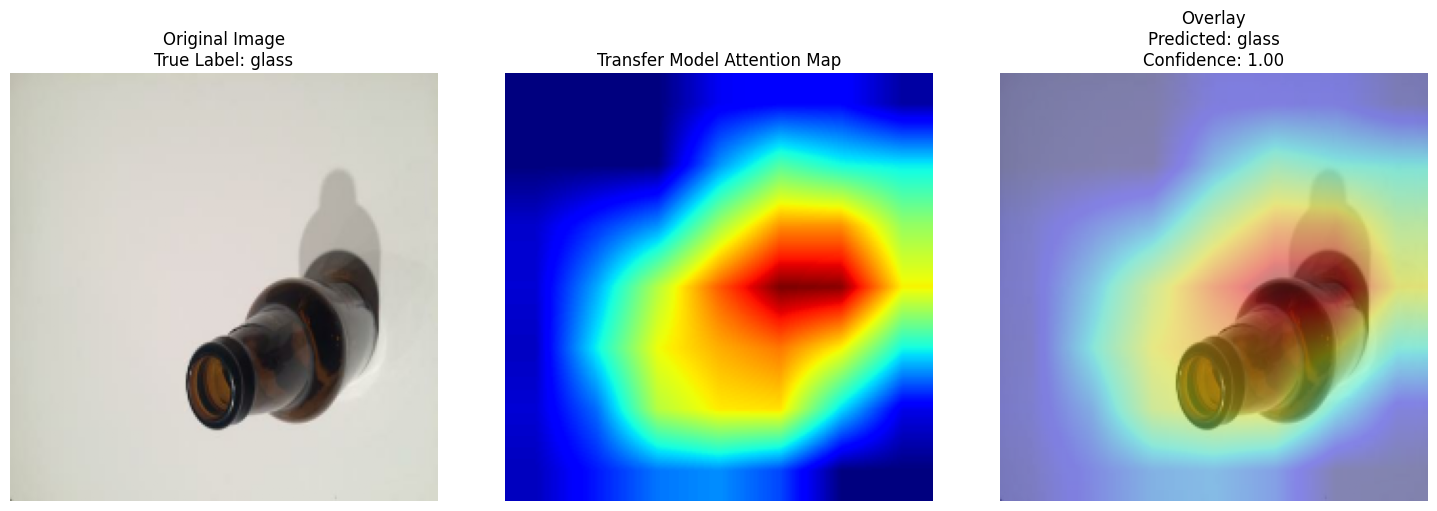

True Label      : glass
Predicted Label : glass
Confidence      : 0.9998
Saved to        : transfer_attention_outputs\sample_transfer_attention.png


{'image_path': 'trash_images\\glass\\glass_001.jpg',
 'true_label': 'glass',
 'predicted_label': 'glass',
 'confidence': 0.9997671246528625,
 'save_path': 'transfer_attention_outputs\\sample_transfer_attention.png'}

In [80]:
sample_image_path = glass_paths[0]

result_attention = display_transfer_attention_map(
    image_path=sample_image_path,
    transfer_model=transfer_model,
    base_model=base_model,
    last_conv_layer_name=last_conv_layer_name,
    true_label="glass",
    save_path=transfer_attention_output_dir / "sample_transfer_attention.png",
    alpha=0.4
)

result_attention

Attention map diuji pada satu gambar dari kelas `glass`, yaitu `trash_images/glass/glass_001.jpg`.

Hasil prediksi menunjukkan bahwa model berhasil memprediksi gambar sebagai `glass` dengan confidence sangat tinggi, yaitu sekitar **0.9999**. Artinya, model sangat yakin bahwa gambar tersebut termasuk kelas glass.

Dari visualisasi Grad-CAM, area merah dan kuning berada di sekitar objek kaca, terutama pada bagian badan dan mulut botol. Hal ini menunjukkan bahwa model cukup fokus pada objek utama, bukan hanya pada background.

Secara keseluruhan, hasil ini menunjukkan bahwa pipeline Grad-CAM sudah berjalan dengan benar dan prediksi model pada gambar contoh ini dapat dianggap baik karena model memperhatikan area yang relevan.

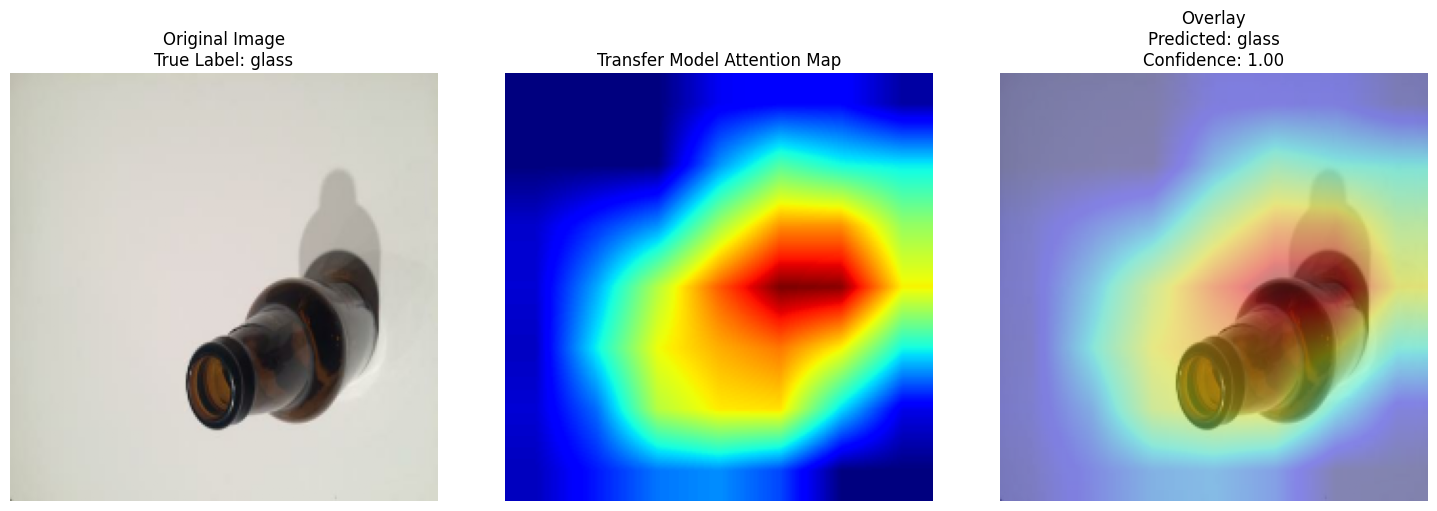

True Label      : glass
Predicted Label : glass
Confidence      : 0.9998
Saved to        : transfer_attention_outputs\glass_predictions\transfer_glass_attention_1.png
------------------------------------------------------------


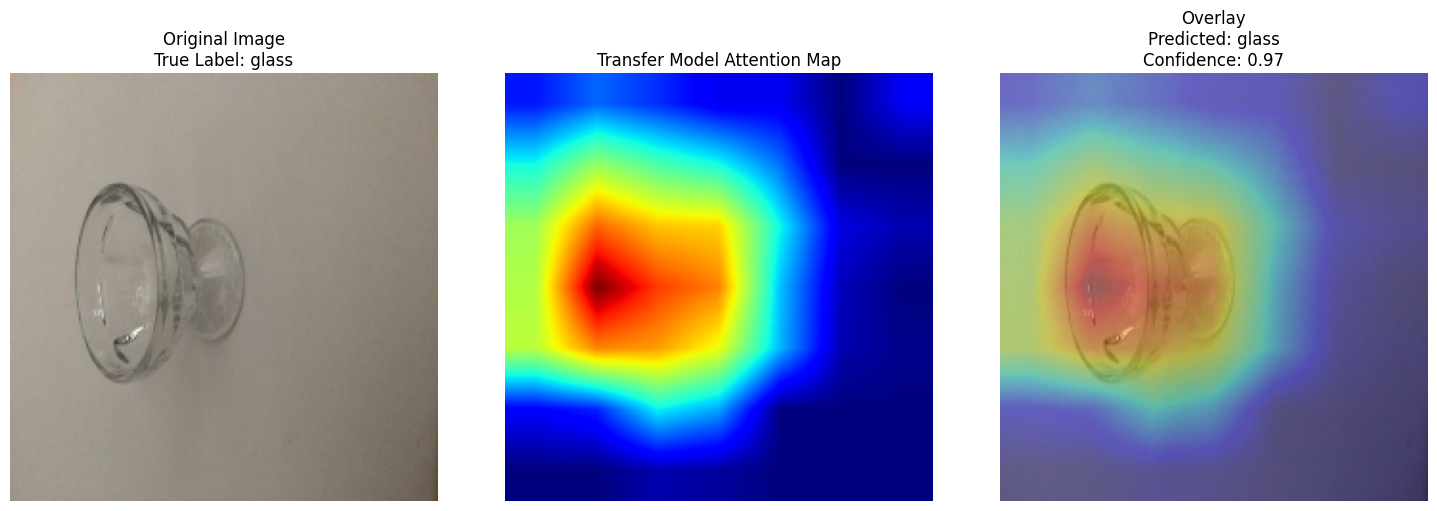

True Label      : glass
Predicted Label : glass
Confidence      : 0.9695
Saved to        : transfer_attention_outputs\glass_predictions\transfer_glass_attention_2.png
------------------------------------------------------------


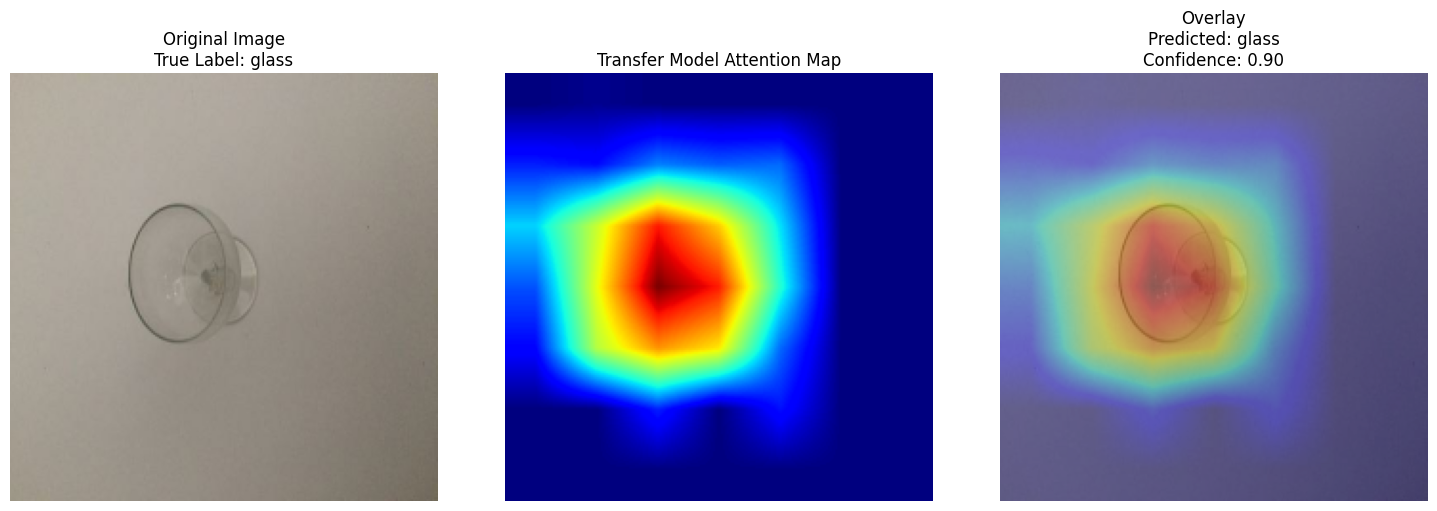

True Label      : glass
Predicted Label : glass
Confidence      : 0.9025
Saved to        : transfer_attention_outputs\glass_predictions\transfer_glass_attention_3.png
------------------------------------------------------------


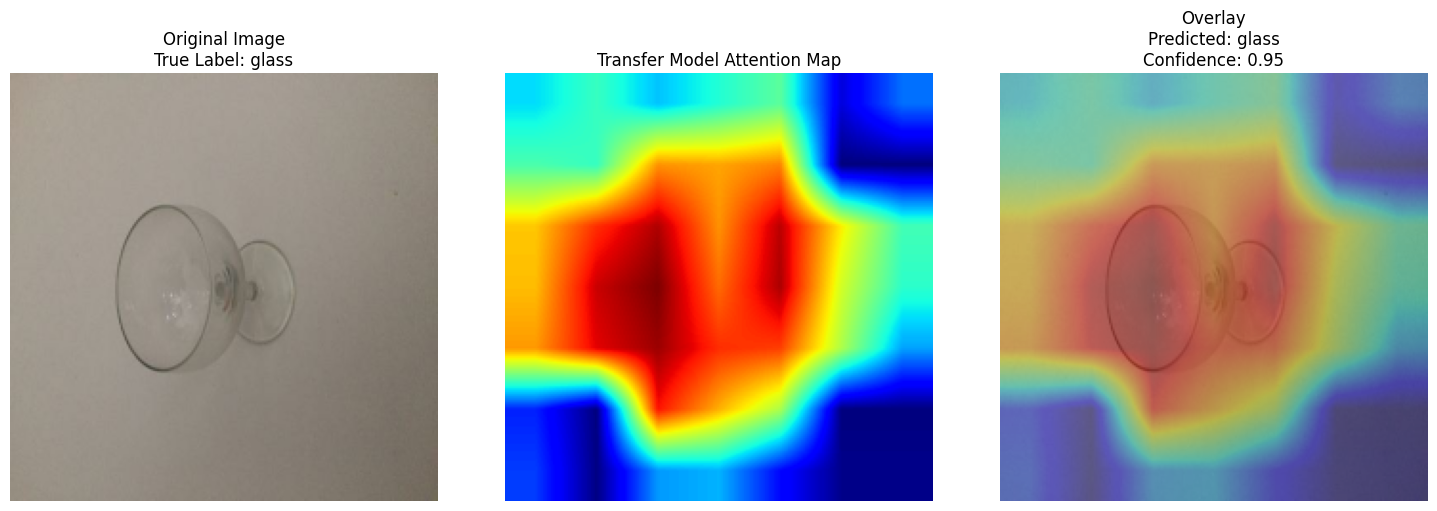

True Label      : glass
Predicted Label : glass
Confidence      : 0.9459
Saved to        : transfer_attention_outputs\glass_predictions\transfer_glass_attention_4.png
------------------------------------------------------------


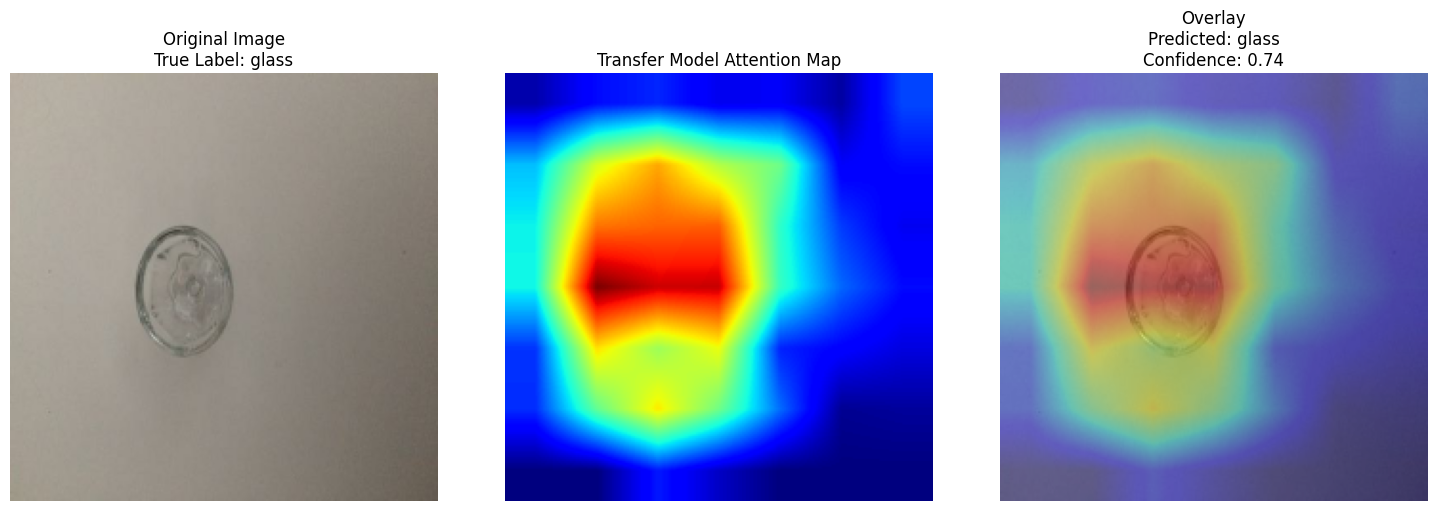

True Label      : glass
Predicted Label : glass
Confidence      : 0.7398
Saved to        : transfer_attention_outputs\glass_predictions\transfer_glass_attention_5.png
------------------------------------------------------------


[{'image_path': 'trash_images\\glass\\glass_001.jpg',
  'true_label': 'glass',
  'predicted_label': 'glass',
  'confidence': 0.9997671246528625,
  'save_path': 'transfer_attention_outputs\\glass_predictions\\transfer_glass_attention_1.png'},
 {'image_path': 'trash_images\\glass\\glass_002.jpg',
  'true_label': 'glass',
  'predicted_label': 'glass',
  'confidence': 0.9695109128952026,
  'save_path': 'transfer_attention_outputs\\glass_predictions\\transfer_glass_attention_2.png'},
 {'image_path': 'trash_images\\glass\\glass_003.jpg',
  'true_label': 'glass',
  'predicted_label': 'glass',
  'confidence': 0.9024736285209656,
  'save_path': 'transfer_attention_outputs\\glass_predictions\\transfer_glass_attention_3.png'},
 {'image_path': 'trash_images\\glass\\glass_004.jpg',
  'true_label': 'glass',
  'predicted_label': 'glass',
  'confidence': 0.9458552002906799,
  'save_path': 'transfer_attention_outputs\\glass_predictions\\transfer_glass_attention_4.png'},
 {'image_path': 'trash_images\\g

In [81]:
glass_attention_results = []

for i, image_path in enumerate(glass_paths[:5]):
    save_path = transfer_attention_glass_dir / f"transfer_glass_attention_{i+1}.png"

    result = display_transfer_attention_map(
        image_path=image_path,
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        true_label="glass",
        save_path=save_path,
        alpha=0.4
    )

    glass_attention_results.append(result)
    print("-" * 60)

glass_attention_results

Grad-CAM dijalankan pada 5 gambar pertama dari kelas `glass`. Tujuannya adalah melihat apakah model konsisten memperhatikan area objek kaca ketika melakukan prediksi.

Dari hasil output, seluruh gambar berhasil diprediksi sebagai `glass`. Confidence model juga cukup tinggi, yaitu sekitar **1.00**, **0.97**, **0.90**, **0.95**, dan **0.74**. Hal ini menunjukkan bahwa model secara umum mampu mengenali gambar kaca dengan baik.

Pada beberapa gambar pertama, area heatmap merah dan kuning terlihat berada di sekitar objek kaca. Ini berarti model cukup fokus pada bagian objek utama, seperti badan gelas, mulut botol, bentuk transparan, dan area pantulan cahaya. Hasil ini menunjukkan bahwa keputusan model cukup masuk akal secara visual.

Namun, pada beberapa gambar, heatmap juga melebar ke area sekitar objek dan tidak hanya tepat pada kaca. Hal ini bisa terjadi karena objek kaca bersifat transparan, sehingga model juga memperhatikan bayangan, background, atau perubahan warna di sekitar objek. Pada gambar kaca, batas objek sering tidak terlalu jelas, sehingga model dapat menggunakan konteks sekitar sebagai informasi tambahan.

Confidence paling rendah muncul pada gambar kelima, yaitu sekitar **0.74**. Meskipun prediksinya masih benar, nilai confidence yang lebih rendah menunjukkan bahwa model tidak seyakin gambar lainnya. Kemungkinan penyebabnya adalah bentuk objek lebih kecil, transparansi tinggi, atau fitur visual kaca kurang kuat dibandingkan gambar lain.

Secara keseluruhan, hasil Grad-CAM menunjukkan bahwa model cukup berhasil mengenali kelas `glass`. Model banyak memperhatikan area yang relevan, meskipun masih ada beberapa fokus yang melebar ke background. Ini menunjukkan bahwa model sudah belajar karakteristik visual kaca, tetapi masih dapat dipengaruhi oleh bayangan dan latar belakang gambar.

Jumlah gambar glass ditemukan: 506
Gambar yang digunakan:
transfer_attention_outputs\glass_predictions\transfer_glass_attention_1.png


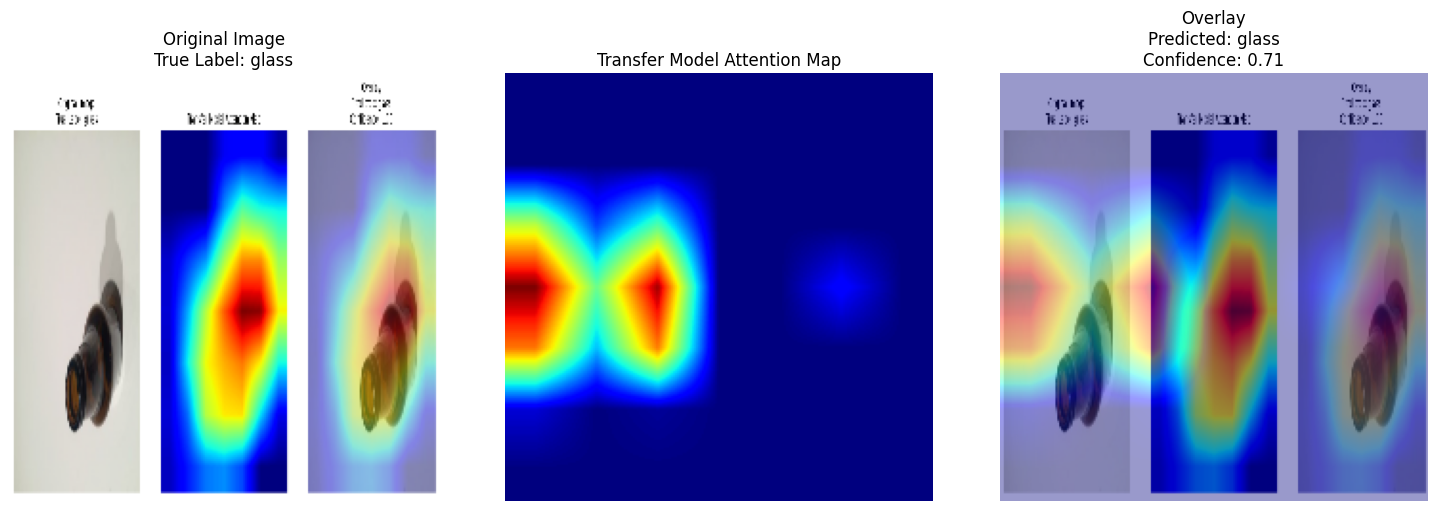

True Label      : glass
Predicted Label : glass
Confidence      : 0.7081
Saved to        : transfer_attention_outputs\sample_transfer_attention.png


In [82]:
# Cari semua gambar glass secara otomatis
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp"]

all_image_paths = []

for ext in image_extensions:
    all_image_paths.extend(list(Path(".").rglob(ext)))

all_image_paths = sorted(all_image_paths)

glass_paths = [
    path for path in all_image_paths
    if "glass" in str(path).lower()
]

print("Jumlah gambar glass ditemukan:", len(glass_paths))

if len(glass_paths) == 0:
    print("Tidak ada gambar glass yang ditemukan.")
    print("Cek kembali lokasi folder dataset kamu.")
else:
    sample_image_path = glass_paths[0]

    print("Gambar yang digunakan:")
    print(sample_image_path)

    result_attention = display_transfer_attention_map(
        image_path=sample_image_path,
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        true_label="glass",
        save_path=transfer_attention_output_dir / "sample_transfer_attention.png",
        alpha=0.4
    )

    result_attention

Pada bagian ini dilakukan pencarian otomatis terhadap semua file gambar yang mengandung kata `glass`, lalu satu gambar pertama digunakan untuk diuji dengan Grad-CAM.

Hasil output menunjukkan bahwa terdapat **506 gambar glass** yang ditemukan. Namun, gambar yang digunakan berasal dari folder:

`transfer_attention_outputs/glass_predictions/transfer_glass_attention_1.png`

Artinya, gambar yang dipakai bukan gambar asli dari dataset, melainkan gambar hasil attention map sebelumnya. Karena itu, tampilan visualisasi terlihat tidak normal dan seperti bertumpuk.

Meskipun model tetap memprediksi kelas `glass` dengan confidence sekitar **0.71**, hasil Grad-CAM ini kurang valid untuk dianalisis karena inputnya bukan gambar asli. Untuk analisis yang benar, gambar seharusnya diambil dari folder dataset asli, yaitu:

`trash_images/glass`

Dengan demikian, pencarian gambar perlu dibatasi hanya pada folder dataset asli agar hasil Grad-CAM lebih bersih dan interpretasinya lebih akurat.

## Prediksi Seluruh Gambar & Analisis Kesalahan

Tahap ini dilakukan untuk mengevaluasi model secara lebih mendalam, bukan hanya berdasarkan nilai accuracy, precision, dan recall. Model akan digunakan untuk memprediksi banyak gambar, lalu hasilnya dikelompokkan menjadi prediksi benar dan prediksi salah.

Analisis ini penting karena dari prediksi yang salah, kita bisa melihat pola kesalahan model. Misalnya, apakah model sering salah membedakan `glass` dengan `plastic`, `paper` dengan `cardboard`, atau `trash` dengan kelas lain.

Selain itu, hasil prediksi salah juga akan dianalisis menggunakan Grad-CAM. Tujuannya adalah untuk melihat apakah kesalahan terjadi karena model fokus pada objek yang salah, background, bayangan, warna, atau area lain yang kurang relevan.

In [83]:
from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf

# Folder utama
transfer_attention_output_dir = Path("transfer_attention_outputs")
transfer_attention_output_dir.mkdir(exist_ok=True)

# Folder untuk hasil benar
transfer_correct_dir = transfer_attention_output_dir / "correct_predictions"
transfer_correct_dir.mkdir(exist_ok=True)

# Folder untuk hasil salah bebas
transfer_wrong_dir = transfer_attention_output_dir / "wrong_predictions"
transfer_wrong_dir.mkdir(exist_ok=True)

# Folder untuk hasil salah confidence tinggi
transfer_high_conf_wrong_dir = transfer_attention_output_dir / "high_confidence_wrong_predictions"
transfer_high_conf_wrong_dir.mkdir(exist_ok=True)

print("Folder output berhasil dibuat:")
print(transfer_attention_output_dir)

Folder output berhasil dibuat:
transfer_attention_outputs


Folder output dibuat ulang untuk menyimpan hasil analisis prediksi model secara rapi. Folder utama yang digunakan adalah `transfer_attention_outputs`.

Di dalam folder tersebut dibuat beberapa subfolder, yaitu `correct_predictions`, `wrong_predictions`, dan `high_confidence_wrong_predictions`.

Folder `correct_predictions` digunakan untuk menyimpan hasil prediksi yang benar. Folder `wrong_predictions` digunakan untuk menyimpan hasil prediksi yang salah. Folder `high_confidence_wrong_predictions` digunakan untuk menyimpan kasus prediksi yang salah tetapi model memiliki confidence tinggi.

Pemisahan folder ini membantu proses analisis error agar lebih terstruktur dan mudah diperiksa kembali.

In [ ]:
# Cari semua gambar dari folder project
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp"]

all_image_paths = []

for ext in image_extensions:
    all_image_paths.extend(list(Path(".").rglob(ext)))

all_image_paths = sorted(all_image_paths)

print("Jumlah total gambar ditemukan:", len(all_image_paths))

for path in all_image_paths[:20]:
    print(path)

Jumlah total gambar ditemukan: 2533
transfer_attention_outputs\glass_predictions\transfer_glass_attention_1.png
transfer_attention_outputs\glass_predictions\transfer_glass_attention_2.png
transfer_attention_outputs\glass_predictions\transfer_glass_attention_3.png
transfer_attention_outputs\glass_predictions\transfer_glass_attention_4.png
transfer_attention_outputs\glass_predictions\transfer_glass_attention_5.png
transfer_attention_outputs\sample_transfer_attention.png
trash_images\cardboard\cardboard_001.jpg
trash_images\cardboard\cardboard_002.jpg
trash_images\cardboard\cardboard_003.jpg
trash_images\cardboard\cardboard_004.jpg
trash_images\cardboard\cardboard_005.jpg
trash_images\cardboard\cardboard_006.jpg
trash_images\cardboard\cardboard_007.jpg
trash_images\cardboard\cardboard_008.jpg
trash_images\cardboard\cardboard_009.jpg
trash_images\cardboard\cardboard_010.jpg
trash_images\cardboard\cardboard_011.jpg
trash_images\cardboard\cardboard_012.jpg
trash_images\cardboard\cardboard_01

Pada bagian ini, semua file gambar dengan format `.jpg`, `.jpeg`, `.png`, dan `.webp` dicari secara otomatis dari seluruh folder project.

Hasil output menunjukkan bahwa terdapat **2533 gambar** yang ditemukan. Namun, beberapa gambar yang muncul berasal dari folder `transfer_attention_outputs`, yaitu hasil Grad-CAM sebelumnya.

Hal ini perlu diperhatikan karena untuk prediksi massal, gambar yang seharusnya digunakan adalah gambar asli dari dataset, yaitu dari folder `trash_images`, bukan gambar hasil visualisasi Grad-CAM. Jika gambar output ikut terbaca, hasil analisis bisa menjadi tidak akurat.

In [ ]:
# Ambil daftar nama kelas
class_names = list(index_to_class.values())

print("Class names:")
print(class_names)

Class names:
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Daftar nama kelas diambil dari `index_to_class`, yaitu mapping antara index prediksi model dan nama kelas sebenarnya.

Hasil output menunjukkan bahwa terdapat 6 kelas, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Daftar kelas ini akan digunakan untuk membaca label asli gambar dan membandingkannya dengan hasil prediksi model.

In [ ]:
# Fungsi untuk mengambil true label dari path gambar
def get_true_label_from_path(image_path, class_names):
    """
    Mengambil true label dari path gambar berdasarkan nama folder.
    Contoh path: dataset/glass/glass1.jpg
    Maka true label = glass
    """
    image_path = Path(image_path)
    path_parts = [part.lower() for part in image_path.parts]

    for class_name in class_names:
        if class_name.lower() in path_parts:
            return class_name

    return None

Fungsi `get_true_label_from_path()` digunakan untuk mengambil label asli gambar berdasarkan nama folder pada path gambar.

Contohnya, jika path gambar adalah `trash_images/glass/glass_001.jpg`, maka fungsi akan membaca bahwa gambar tersebut berada di folder `glass`, sehingga true label-nya adalah `glass`.

Fungsi ini bekerja dengan memecah path gambar menjadi beberapa bagian, lalu mengecek apakah salah satu bagian path sesuai dengan nama kelas yang tersedia. Jika ditemukan, fungsi akan mengembalikan nama kelas tersebut.

Fungsi ini penting untuk membandingkan label asli gambar dengan hasil prediksi model, sehingga dapat diketahui apakah prediksi model benar atau salah.

In [ ]:
# Buat dataframe kandidat gambar
image_records = []

for image_path in all_image_paths:
    true_label = get_true_label_from_path(image_path, class_names)

    if true_label is not None:
        image_records.append({
            "image_path": image_path,
            "true_label": true_label
        })

image_df = pd.DataFrame(image_records)

print("Jumlah gambar yang berhasil diberi label:", len(image_df))
display(image_df.head())

Jumlah gambar yang berhasil diberi label: 2527


,image_path,true_label
0,trash_images\cardboard\cardboard_001.jpg,cardboard
1,trash_images\cardboard\cardboard_002.jpg,cardboard
2,trash_images\cardboard\cardboard_003.jpg,cardboard
3,trash_images\cardboard\cardboard_004.jpg,cardboard
4,trash_images\cardboard\cardboard_005.jpg,cardboard


DataFrame dibuat untuk menyimpan daftar gambar yang akan dianalisis. Setiap gambar dicatat dalam dua informasi utama, yaitu `image_path` dan `true_label`.

Label asli diperoleh dari nama folder pada path gambar menggunakan fungsi `get_true_label_from_path()`. Jika gambar berhasil dikenali labelnya, maka gambar tersebut dimasukkan ke dalam `image_records`.

Hasil output menunjukkan bahwa terdapat **2527 gambar** yang berhasil diberi label. Jumlah ini sesuai dengan total gambar asli pada dataset, sehingga data sudah siap digunakan untuk proses prediksi massal.

DataFrame ini nantinya akan dipakai untuk membandingkan true label dengan predicted label dari model.

In [ ]:
# Fungsi prediksi satu gambar
def predict_image_transfer_attention(image_path, true_label):
    image = load_image_for_transfer_attention(image_path)
    img_array = tf.expand_dims(image, axis=0)

    predictions = transfer_model(img_array, training=False).numpy()

    predicted_index = np.argmax(predictions[0])
    predicted_label = index_to_class[predicted_index]
    confidence = float(predictions[0][predicted_index])

    is_correct = predicted_label == true_label

    return {
        "image_path": str(image_path),
        "true_label": true_label,
        "predicted_label": predicted_label,
        "confidence": confidence,
        "is_correct": is_correct
    }

Fungsi `predict_image_transfer_attention()` digunakan untuk melakukan prediksi pada satu gambar menggunakan model transfer learning.

Gambar terlebih dahulu dibaca dan diproses menggunakan `load_image_for_transfer_attention()`, lalu ditambahkan dimensi batch agar sesuai dengan input model. Setelah itu, model menghasilkan probabilitas prediksi untuk setiap kelas.

Index dengan probabilitas tertinggi diambil sebagai hasil prediksi, kemudian diubah menjadi nama kelas menggunakan `index_to_class`. Nilai confidence menunjukkan seberapa yakin model terhadap prediksi tersebut.

Fungsi ini juga membandingkan `predicted_label` dengan `true_label`. Jika keduanya sama, maka hasilnya dianggap benar. Output fungsi berupa dictionary yang berisi path gambar, true label, predicted label, confidence, dan status benar atau salah.

In [ ]:
# Prediksi seluruh gambar
prediction_records = []

for _, row in image_df.iterrows():
    record = predict_image_transfer_attention(
        image_path=row["image_path"],
        true_label=row["true_label"]
    )

    prediction_records.append(record)

transfer_prediction_df = pd.DataFrame(prediction_records)

display(transfer_prediction_df.head())

print("Jumlah data prediksi:", len(transfer_prediction_df))
print("Jumlah prediksi benar:", transfer_prediction_df["is_correct"].sum())
print("Jumlah prediksi salah:", (~transfer_prediction_df["is_correct"]).sum())

,image_path,true_label,predicted_label,confidence,is_correct
0,trash_images\cardboard\cardboard_001.jpg,cardboard,cardboard,0.999859,True
1,trash_images\cardboard\cardboard_002.jpg,cardboard,cardboard,0.998541,True
2,trash_images\cardboard\cardboard_003.jpg,cardboard,cardboard,0.999998,True
3,trash_images\cardboard\cardboard_004.jpg,cardboard,cardboard,0.986798,True
4,trash_images\cardboard\cardboard_005.jpg,cardboard,cardboard,0.999983,True


Jumlah data prediksi: 2527
Jumlah prediksi benar: 2195
Jumlah prediksi salah: 332


Seluruh gambar pada dataset diprediksi menggunakan model transfer learning. Setiap hasil prediksi disimpan ke dalam DataFrame yang berisi `image_path`, `true_label`, `predicted_label`, `confidence`, dan status `is_correct`.

Hasil output menunjukkan bahwa terdapat **2527 gambar** yang berhasil diprediksi. Dari jumlah tersebut, **2195 gambar** diprediksi dengan benar, sedangkan **332 gambar** masih salah diprediksi.

Data ini penting untuk analisis lanjutan karena hasil prediksi dapat dipisahkan menjadi prediksi benar dan salah. Dari prediksi yang salah, dapat dianalisis kelas mana yang paling sering tertukar dan apakah model salah fokus saat dilihat menggunakan Grad-CAM.

In [ ]:
# Pisahkan correct dan wrong prediction
correct_predictions_df = transfer_prediction_df[
    transfer_prediction_df["is_correct"] == True
].copy()

wrong_predictions_df = transfer_prediction_df[
    transfer_prediction_df["is_correct"] == False
].copy()

print("Jumlah correct predictions:", len(correct_predictions_df))
print("Jumlah wrong predictions:", len(wrong_predictions_df))

display(correct_predictions_df.head())
display(wrong_predictions_df.head())

Jumlah correct predictions: 2195
Jumlah wrong predictions: 332


,image_path,true_label,predicted_label,confidence,is_correct
0,trash_images\cardboard\cardboard_001.jpg,cardboard,cardboard,0.999859,True
1,trash_images\cardboard\cardboard_002.jpg,cardboard,cardboard,0.998541,True
2,trash_images\cardboard\cardboard_003.jpg,cardboard,cardboard,0.999998,True
3,trash_images\cardboard\cardboard_004.jpg,cardboard,cardboard,0.986798,True
4,trash_images\cardboard\cardboard_005.jpg,cardboard,cardboard,0.999983,True


,image_path,true_label,predicted_label,confidence,is_correct
32,trash_images\cardboard\cardboard_033.jpg,cardboard,paper,0.907678,False
40,trash_images\cardboard\cardboard_041.jpg,cardboard,paper,0.707498,False
98,trash_images\cardboard\cardboard_099.jpg,cardboard,paper,0.890106,False
127,trash_images\cardboard\cardboard_128.jpg,cardboard,paper,0.783248,False
143,trash_images\cardboard\cardboard_144.jpg,cardboard,paper,0.621963,False


Hasil prediksi seluruh gambar dipisahkan menjadi dua kelompok, yaitu prediksi benar dan prediksi salah.

Prediksi benar disimpan ke dalam `correct_predictions_df`, yaitu data ketika `true_label` sama dengan `predicted_label`. Prediksi salah disimpan ke dalam `wrong_predictions_df`, yaitu data ketika `true_label` berbeda dengan `predicted_label`.

Hasil output menunjukkan bahwa terdapat **2195 prediksi benar** dan **332 prediksi salah**. Data prediksi salah ini penting untuk dianalisis lebih lanjut karena dapat menunjukkan pola kesalahan model, misalnya gambar `cardboard` yang diprediksi sebagai `paper`.

Dengan pemisahan ini, analisis error menjadi lebih mudah dilakukan, terutama untuk melihat contoh kesalahan model dan mengevaluasinya menggunakan Grad-CAM.

Contoh prediksi benar:
image_path         trash_images\cardboard\cardboard_329.jpg
true_label                                        cardboard
predicted_label                                   cardboard
confidence                                              1.0
is_correct                                             True
Name: 328, dtype: object


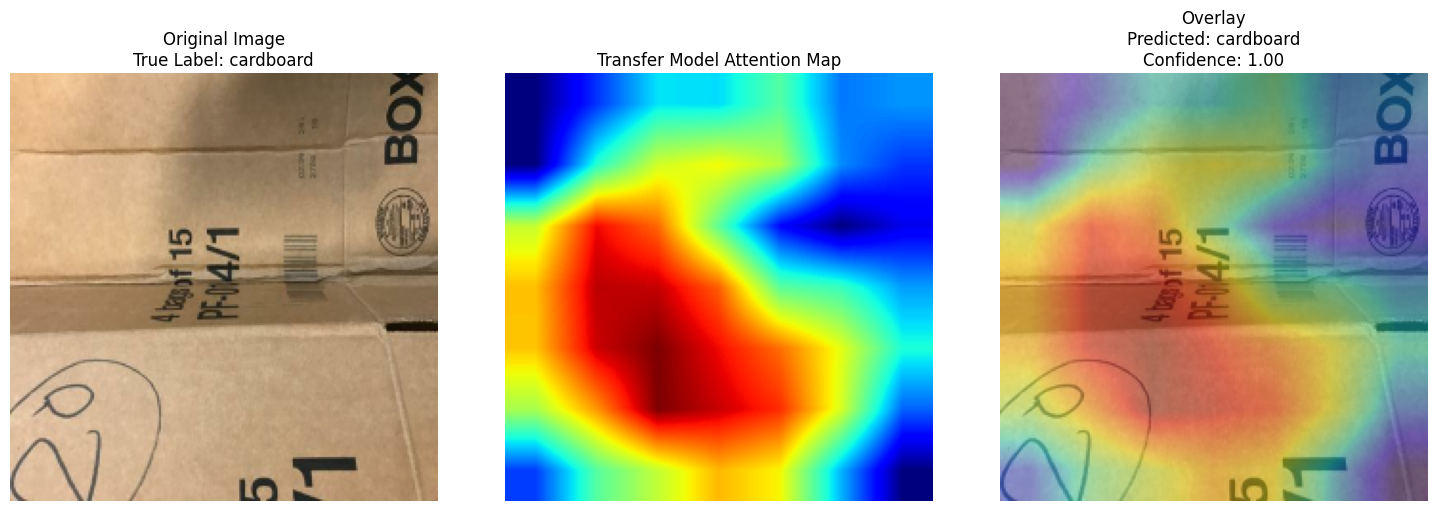

True Label      : cardboard
Predicted Label : cardboard
Confidence      : 1.0
Saved to        : transfer_attention_outputs\correct_predictions\transfer_correct_prediction_attention.png


In [ ]:
# Contoh prediksi benar
if len(correct_predictions_df) == 0:
    print("Tidak ada prediksi benar yang ditemukan.")
else:
    correct_sample = correct_predictions_df.sort_values(
        by="confidence",
        ascending=False
    ).iloc[0]

    print("Contoh prediksi benar:")
    print(correct_sample)

    correct_save_path = transfer_correct_dir / "transfer_correct_prediction_attention.png"

    correct_attention_result = display_transfer_attention_map(
        image_path=correct_sample["image_path"],
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        true_label=correct_sample["true_label"],
        save_path=correct_save_path,
        alpha=0.4
    )

    correct_attention_result

Contoh prediksi benar diambil dari data yang memiliki confidence tertinggi. Pada hasil ini, gambar `cardboard_329.jpg` memiliki true label `cardboard` dan model juga memprediksinya sebagai `cardboard`.

Confidence model adalah **1.00**, yang berarti model sangat yakin terhadap prediksi tersebut. Hasil ini menunjukkan bahwa model berhasil mengenali gambar cardboard dengan sangat baik.

Pada visualisasi Grad-CAM, area merah dan kuning terlihat berada pada bagian utama kardus, terutama area tekstur, lipatan, tulisan, dan permukaan cardboard. Hal ini menunjukkan bahwa model memperhatikan area yang relevan untuk menentukan kelas gambar.

Secara keseluruhan, contoh ini menunjukkan prediksi yang baik karena label asli dan label prediksi sama, confidence sangat tinggi, serta attention map berada pada objek utama.

Contoh prediksi salah:
image_path         trash_images\cardboard\cardboard_033.jpg
true_label                                        cardboard
predicted_label                                       paper
confidence                                         0.907678
is_correct                                            False
Name: 32, dtype: object


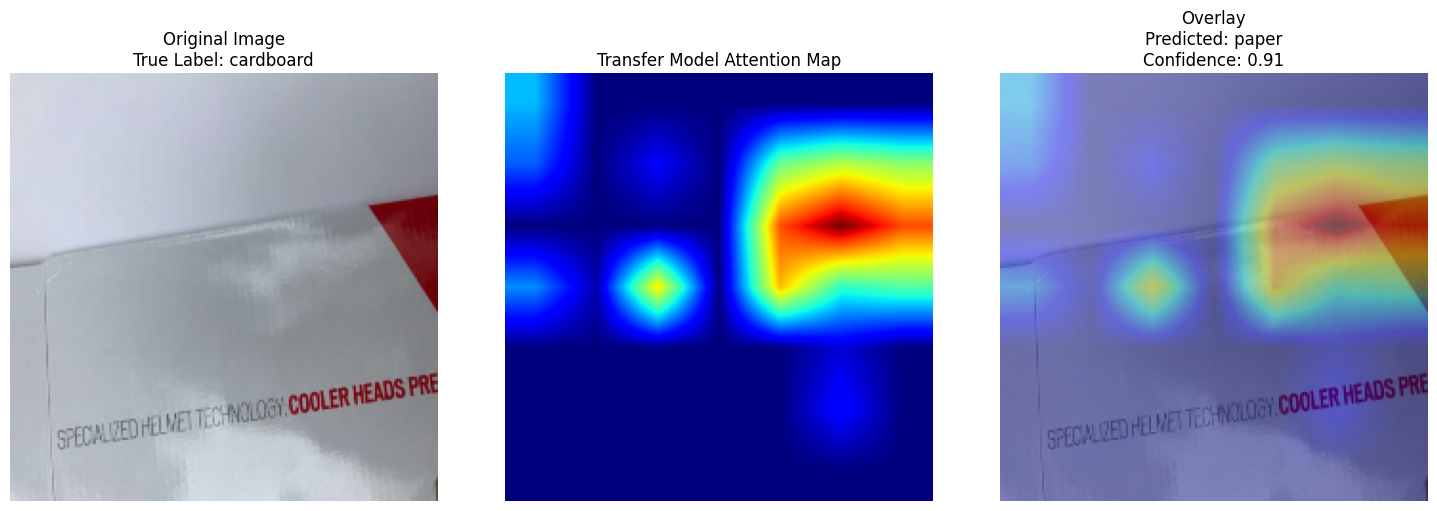

True Label      : cardboard
Predicted Label : paper
Confidence      : 0.9077
Saved to        : transfer_attention_outputs\wrong_predictions\transfer_wrong_prediction_attention.png


In [ ]:
# Contoh prediksi salah bebas
if len(wrong_predictions_df) == 0:
    print("Tidak ada prediksi salah yang ditemukan.")
else:
    wrong_sample = wrong_predictions_df.iloc[0]

    print("Contoh prediksi salah:")
    print(wrong_sample)

    wrong_save_path = transfer_wrong_dir / "transfer_wrong_prediction_attention.png"

    wrong_attention_result = display_transfer_attention_map(
        image_path=wrong_sample["image_path"],
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        true_label=wrong_sample["true_label"],
        save_path=wrong_save_path,
        alpha=0.4
    )

    wrong_attention_result

Contoh prediksi salah diambil dari data yang memiliki hasil prediksi tidak sesuai dengan label aslinya. Pada contoh ini, gambar memiliki true label `cardboard`, tetapi model memprediksinya sebagai `paper`.

Confidence model cukup tinggi, yaitu sekitar **0.91**. Artinya, model cukup yakin bahwa gambar tersebut adalah `paper`, meskipun prediksinya salah. Hal ini menunjukkan bahwa kesalahan model bukan terjadi karena model ragu, tetapi karena model menangkap fitur visual yang dianggap mirip dengan kelas `paper`.

Dari visualisasi Grad-CAM, area yang paling diperhatikan model berada pada bagian permukaan objek yang berwarna terang, datar, dan memiliki tulisan. Karakteristik ini memang bisa terlihat mirip dengan kertas atau paper, sehingga model salah mengklasifikasikan gambar cardboard sebagai paper.

Kesalahan ini cukup masuk akal karena `cardboard` dan `paper` memiliki kemiripan visual. Keduanya sama-sama berbahan dasar kertas, memiliki tekstur datar, warna yang mirip, dan sering memiliki tulisan atau pola pada permukaannya.

Secara keseluruhan, hasil ini menunjukkan bahwa model masih dapat tertukar pada kelas yang memiliki karakteristik visual berdekatan. Grad-CAM membantu menjelaskan bahwa model salah karena fokus pada area yang terlihat seperti paper, bukan karena proses prediksi gagal sepenuhnya.

Prediksi salah dengan confidence tertinggi:
image_path         trash_images\trash\trash_093.jpg
true_label                                    trash
predicted_label                           cardboard
confidence                                  0.99916
is_correct                                    False
Name: 2482, dtype: object


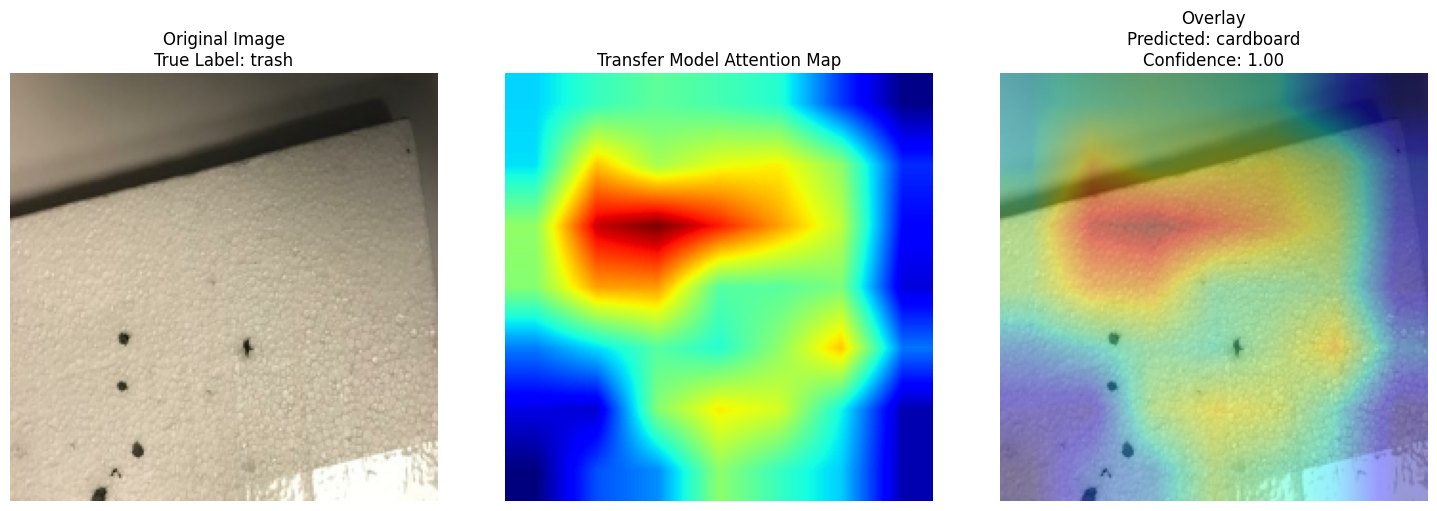

True Label      : trash
Predicted Label : cardboard
Confidence      : 0.9992
Saved to        : transfer_attention_outputs\high_confidence_wrong_predictions\transfer_high_confidence_wrong_prediction_attention.png


In [ ]:
# Prediksi salah dengan confidence tertinggi
if len(wrong_predictions_df) == 0:
    print("Tidak ada prediksi salah yang ditemukan.")
else:
    high_conf_wrong_sample = wrong_predictions_df.sort_values(
        by="confidence",
        ascending=False
    ).iloc[0]

    print("Prediksi salah dengan confidence tertinggi:")
    print(high_conf_wrong_sample)

    high_conf_wrong_save_path = (
        transfer_high_conf_wrong_dir / 
        "transfer_high_confidence_wrong_prediction_attention.png"
    )

    high_conf_wrong_attention_result = display_transfer_attention_map(
        image_path=high_conf_wrong_sample["image_path"],
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        true_label=high_conf_wrong_sample["true_label"],
        save_path=high_conf_wrong_save_path,
        alpha=0.4
    )

    high_conf_wrong_attention_result

Contoh ini menunjukkan kasus prediksi salah dengan confidence paling tinggi. Gambar memiliki true label `trash`, tetapi model memprediksinya sebagai `cardboard`.

Confidence model sangat tinggi, yaitu sekitar **0.9992** atau hampir **1.00**. Artinya, model sangat yakin bahwa gambar tersebut adalah `cardboard`, padahal label aslinya adalah `trash`.

Dari visualisasi Grad-CAM, area yang paling diperhatikan model berada pada permukaan objek yang terlihat datar, terang, dan memiliki tekstur seperti bahan kertas/kardus. Karena karakteristik visual tersebut mirip dengan `cardboard`, model akhirnya salah mengklasifikasikan gambar `trash` sebagai `cardboard`.

Kesalahan ini menunjukkan bahwa model masih dapat terlalu yakin pada prediksi yang salah, terutama jika objek memiliki fitur visual yang mirip dengan kelas lain. Dalam kasus ini, kelas `trash` memang cukup sulit karena bentuk dan tampilannya sangat bervariasi. Jika gambar trash terlihat seperti potongan kardus, kertas, atau material datar, model bisa tertukar dengan kelas `cardboard`.

Grad-CAM membantu menjelaskan penyebab kesalahan tersebut. Model tidak sepenuhnya asal menebak, tetapi fokus pada area visual yang menurut model menyerupai cardboard. Namun, karena konteks gambar sebenarnya adalah trash, prediksi akhirnya tetap salah.

In [ ]:
# Ringkasan prediksi
summary_cols = [
    "image_path",
    "true_label",
    "predicted_label",
    "confidence",
    "is_correct"
]

transfer_prediction_summary = transfer_prediction_df[summary_cols].copy()

display(
    transfer_prediction_summary.sort_values(
        by="confidence",
        ascending=False
    ).head(20)
)

,image_path,true_label,predicted_label,confidence,is_correct
328,trash_images\cardboard\cardboard_329.jpg,cardboard,cardboard,1.000000,True
221,trash_images\cardboard\cardboard_222.jpg,cardboard,cardboard,1.000000,True
227,trash_images\cardboard\cardboard_228.jpg,cardboard,cardboard,1.000000,True
100,trash_images\cardboard\cardboard_101.jpg,cardboard,cardboard,1.000000,True
364,trash_images\cardboard\cardboard_365.jpg,cardboard,cardboard,1.000000,True
159,trash_images\cardboard\cardboard_160.jpg,cardboard,cardboard,1.000000,True
52,trash_images\cardboard\cardboard_053.jpg,cardboard,cardboard,1.000000,True
59,trash_images\cardboard\cardboard_060.jpg,cardboard,cardboard,1.000000,True
86,trash_images\cardboard\cardboard_087.jpg,cardboard,cardboard,1.000000,True
326,trash_images\cardboard\cardboard_327.jpg,cardboard,cardboard,0.999999,True


Ringkasan prediksi dibuat untuk menampilkan hasil prediksi model dalam bentuk tabel yang lebih sederhana. Kolom yang ditampilkan adalah `image_path`, `true_label`, `predicted_label`, `confidence`, dan `is_correct`.

Data kemudian diurutkan berdasarkan nilai `confidence` dari yang paling tinggi. Tujuannya adalah melihat gambar mana yang diprediksi model dengan keyakinan paling besar.

Dari hasil output, beberapa prediksi teratas memiliki confidence sangat tinggi, bahkan mendekati **1.00**. Sebagian besar contoh yang muncul adalah gambar `cardboard` yang berhasil diprediksi dengan benar sebagai `cardboard`.

Ringkasan ini berguna untuk melihat prediksi model secara umum, terutama untuk membandingkan kasus prediksi benar dengan confidence tinggi dan kasus prediksi salah dengan confidence tinggi.

In [ ]:
# Top 5 wrong predictions berdasarkan confidence
top_wrong_predictions = wrong_predictions_df.sort_values(
    by="confidence",
    ascending=False
).head(5)

display(top_wrong_predictions)

,image_path,true_label,predicted_label,confidence,is_correct
2482,trash_images\trash\trash_093.jpg,trash,cardboard,0.999160,False
2417,trash_images\trash\trash_028.jpg,trash,cardboard,0.999155,False
588,trash_images\glass\glass_186.jpg,glass,metal,0.998307,False
855,trash_images\glass\glass_453.jpg,glass,metal,0.995939,False
1989,trash_images\plastic\plastic_082.jpg,plastic,paper,0.993259,False


Tabel ini menampilkan 5 prediksi salah dengan nilai confidence tertinggi. Data diambil dari `wrong_predictions_df`, kemudian diurutkan berdasarkan confidence secara menurun.

Hasil ini penting karena menunjukkan kasus ketika model salah, tetapi tetap sangat yakin terhadap prediksinya. Contohnya, beberapa gambar dengan true label `trash` diprediksi sebagai `cardboard` dengan confidence hampir **1.00**.

Kesalahan seperti ini menunjukkan bahwa model masih bisa tertukar pada gambar yang memiliki kemiripan visual antar kelas. Misalnya, gambar `trash` bisa terlihat seperti kardus atau kertas, sehingga model menganggapnya sebagai `cardboard`.

Tabel ini berguna untuk analisis error lanjutan, karena kasus salah dengan confidence tinggi perlu diperhatikan lebih serius dibandingkan kesalahan dengan confidence rendah.

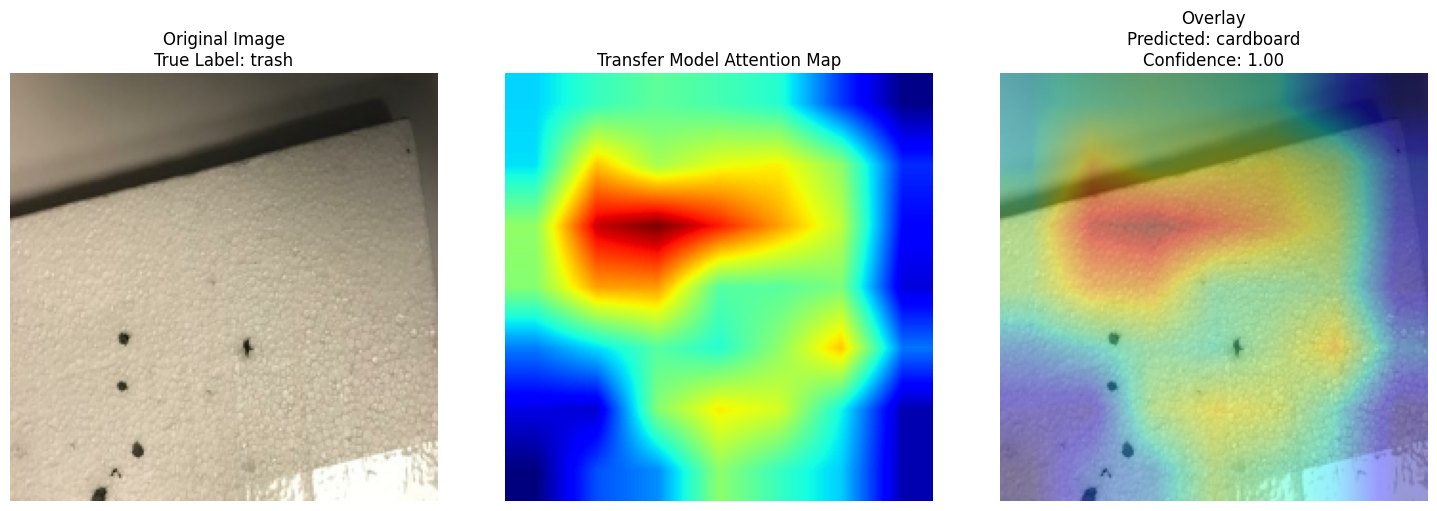

True Label      : trash
Predicted Label : cardboard
Confidence      : 0.9992
Saved to        : transfer_attention_outputs\high_confidence_wrong_predictions\top_high_conf_wrong_2482.png
------------------------------------------------------------


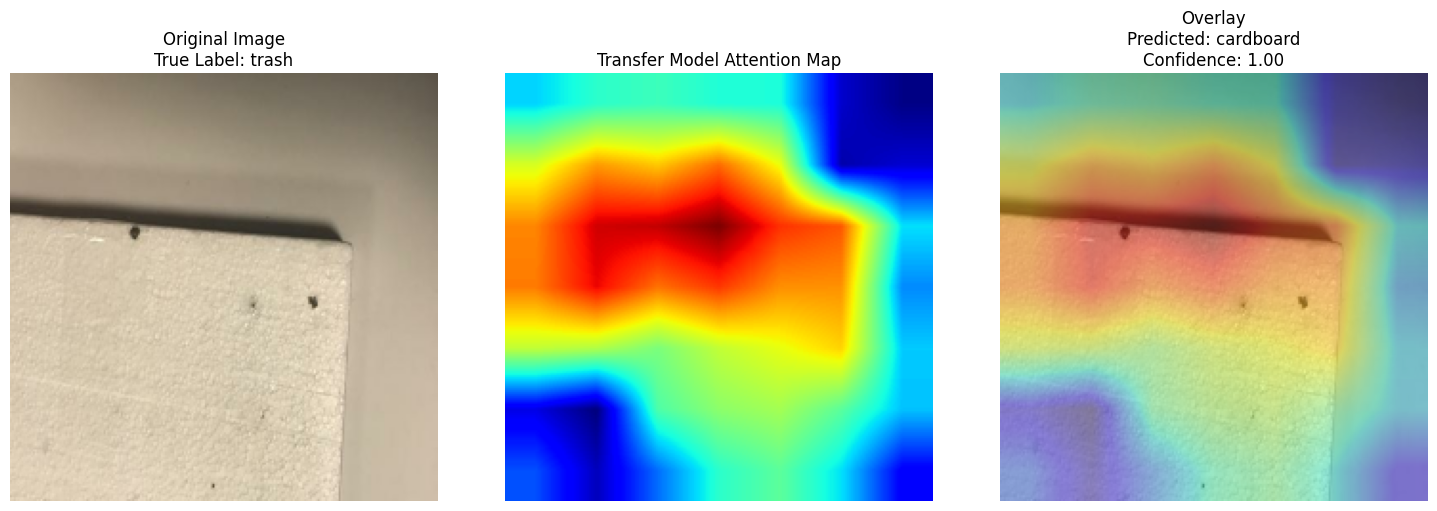

True Label      : trash
Predicted Label : cardboard
Confidence      : 0.9992
Saved to        : transfer_attention_outputs\high_confidence_wrong_predictions\top_high_conf_wrong_2417.png
------------------------------------------------------------


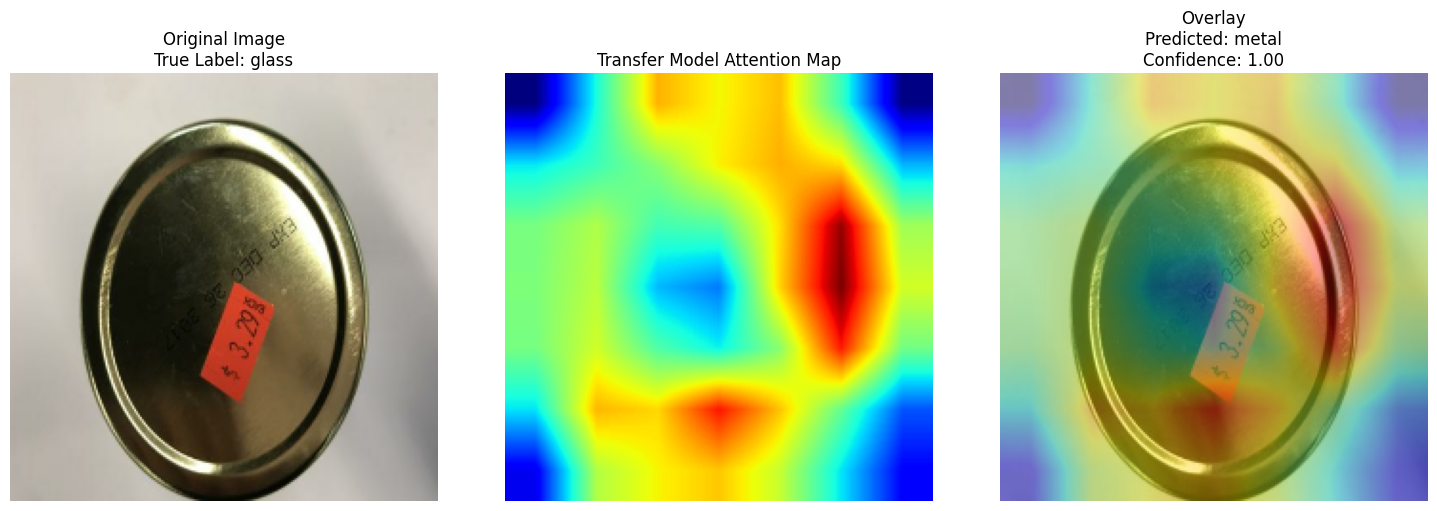

True Label      : glass
Predicted Label : metal
Confidence      : 0.9983
Saved to        : transfer_attention_outputs\high_confidence_wrong_predictions\top_high_conf_wrong_588.png
------------------------------------------------------------


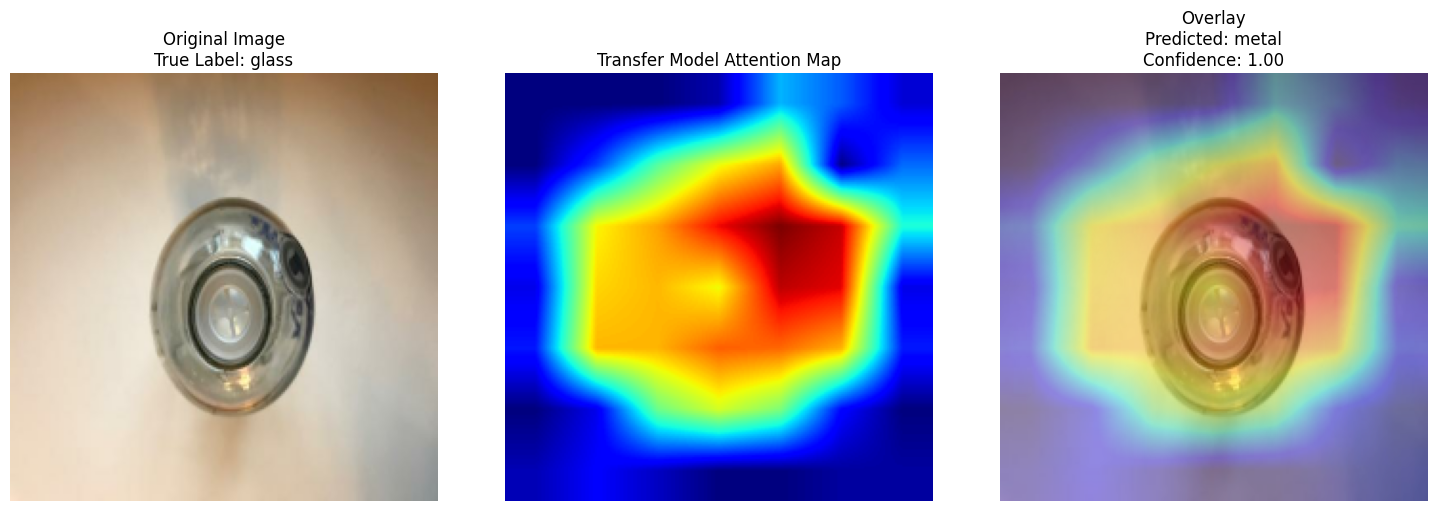

True Label      : glass
Predicted Label : metal
Confidence      : 0.9959
Saved to        : transfer_attention_outputs\high_confidence_wrong_predictions\top_high_conf_wrong_855.png
------------------------------------------------------------


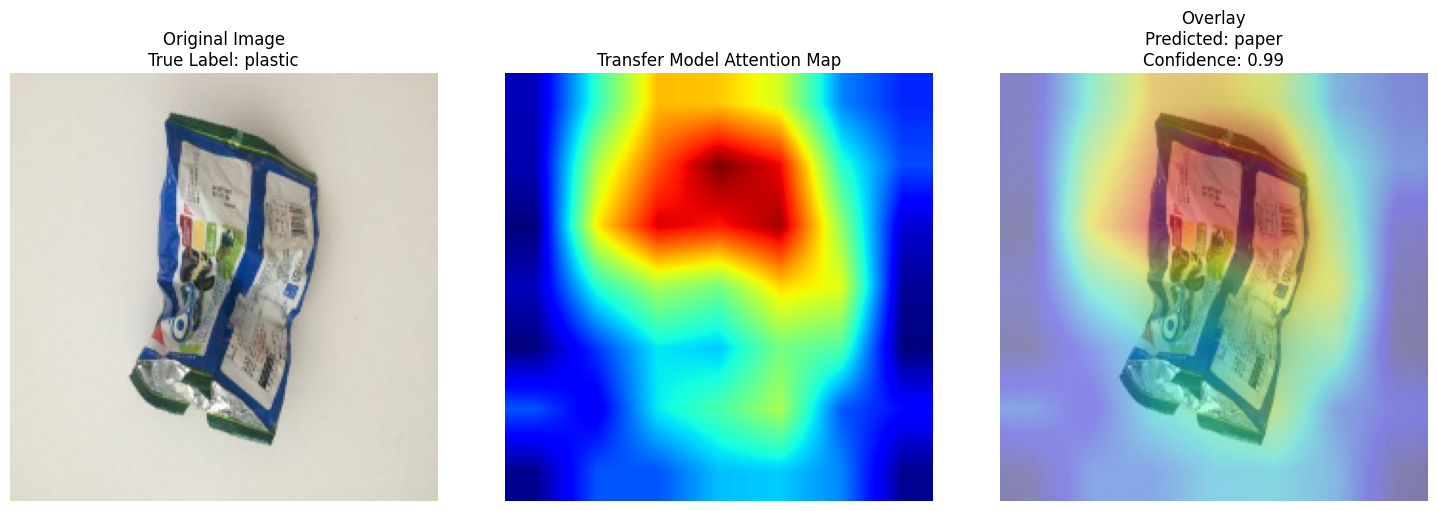

True Label      : plastic
Predicted Label : paper
Confidence      : 0.9933
Saved to        : transfer_attention_outputs\high_confidence_wrong_predictions\top_high_conf_wrong_1989.png
------------------------------------------------------------


[{'image_path': 'trash_images\\trash\\trash_093.jpg',
  'true_label': 'trash',
  'predicted_label': 'cardboard',
  'confidence': 0.9991601705551147,
  'save_path': 'transfer_attention_outputs\\high_confidence_wrong_predictions\\top_high_conf_wrong_2482.png'},
 {'image_path': 'trash_images\\trash\\trash_028.jpg',
  'true_label': 'trash',
  'predicted_label': 'cardboard',
  'confidence': 0.9991551637649536,
  'save_path': 'transfer_attention_outputs\\high_confidence_wrong_predictions\\top_high_conf_wrong_2417.png'},
 {'image_path': 'trash_images\\glass\\glass_186.jpg',
  'true_label': 'glass',
  'predicted_label': 'metal',
  'confidence': 0.9983071088790894,
  'save_path': 'transfer_attention_outputs\\high_confidence_wrong_predictions\\top_high_conf_wrong_588.png'},
 {'image_path': 'trash_images\\glass\\glass_453.jpg',
  'true_label': 'glass',
  'predicted_label': 'metal',
  'confidence': 0.9959392547607422,
  'save_path': 'transfer_attention_outputs\\high_confidence_wrong_predictions\\t

In [ ]:
# Attention map untuk Top 5 High Confidence Wrong Predictions
top_high_conf_wrong_results = []

for i, row in top_wrong_predictions.iterrows():
    save_path = transfer_high_conf_wrong_dir / f"top_high_conf_wrong_{i}.png"

    result = display_transfer_attention_map(
        image_path=row["image_path"],
        transfer_model=transfer_model,
        base_model=base_model,
        last_conv_layer_name=last_conv_layer_name,
        true_label=row["true_label"],
        save_path=save_path,
        alpha=0.4
    )

    top_high_conf_wrong_results.append(result)

    print("-" * 60)

top_high_conf_wrong_results

Grad-CAM dijalankan pada 5 gambar yang salah diprediksi tetapi memiliki confidence paling tinggi. Analisis ini penting karena menunjukkan kasus ketika model sangat yakin, tetapi hasil prediksinya tetap salah.

Pada dua contoh pertama, true label gambar adalah `trash`, tetapi model memprediksinya sebagai `cardboard` dengan confidence hampir **1.00**. Dari attention map, model terlihat fokus pada permukaan objek yang datar, terang, dan memiliki tekstur seperti kardus. Hal ini membuat model menganggap gambar tersebut sebagai `cardboard`, meskipun sebenarnya termasuk `trash`.

Pada contoh berikutnya, true label gambar adalah `glass`, tetapi model memprediksinya sebagai `metal` dengan confidence sangat tinggi. Kesalahan ini cukup masuk akal karena objek glass pada gambar memiliki bentuk bulat, permukaan mengkilap, dan pantulan cahaya yang mirip dengan metal. Grad-CAM menunjukkan bahwa model memperhatikan area objek utama, tetapi fitur visual yang ditangkap lebih mirip metal daripada glass.

Pada contoh terakhir, true label gambar adalah `plastic`, tetapi model memprediksinya sebagai `paper`. Dari visualisasi, objek terlihat seperti kemasan plastik yang memiliki label atau area datar seperti kertas. Model kemungkinan terlalu fokus pada bagian label dan permukaan kemasan, sehingga salah mengenalinya sebagai paper.

Secara keseluruhan, hasil ini menunjukkan bahwa kesalahan model banyak terjadi pada kelas yang memiliki kemiripan visual. `Trash` dapat terlihat seperti cardboard, `glass` dapat terlihat seperti metal, dan `plastic` dapat terlihat seperti paper. Grad-CAM membantu menjelaskan bahwa model tidak asal menebak, tetapi fokus pada area yang menurut model memiliki fitur kuat, meskipun fitur tersebut mengarah ke kelas yang salah.

## Display Semua Wrong Predictions per Kelas

Bagian ini digunakan untuk menampilkan seluruh gambar yang salah diprediksi oleh model, lalu mengelompokkannya berdasarkan kelas asli.

Tujuannya adalah melihat pola kesalahan model secara lebih detail untuk setiap kategori. Dengan cara ini, dapat dianalisis kelas mana yang paling sering salah dikenali dan kelas apa yang paling sering menjadi hasil prediksi keliru.

Analisis ini juga membantu menjelaskan kelemahan model secara visual, misalnya apakah `glass` sering tertukar dengan `metal`, `plastic` tertukar dengan `paper`, atau `trash` tertukar dengan `cardboard`.

In [ ]:
# DISPLAY ALL WRONG PREDICTIONS FOR EACH CLASS
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
import math

In [ ]:
# Filter Semua Prediksi yang Salah
wrong_predictions_df = transfer_prediction_df[
    transfer_prediction_df["is_correct"] == False
].copy()

print("Total wrong predictions:", len(wrong_predictions_df))

display(wrong_predictions_df.head())

Total wrong predictions: 332


,image_path,true_label,predicted_label,confidence,is_correct
32,trash_images\cardboard\cardboard_033.jpg,cardboard,paper,0.907678,False
40,trash_images\cardboard\cardboard_041.jpg,cardboard,paper,0.707498,False
98,trash_images\cardboard\cardboard_099.jpg,cardboard,paper,0.890106,False
127,trash_images\cardboard\cardboard_128.jpg,cardboard,paper,0.783248,False
143,trash_images\cardboard\cardboard_144.jpg,cardboard,paper,0.621963,False


Data hasil prediksi difilter untuk mengambil hanya gambar yang salah diprediksi, yaitu ketika nilai `is_correct` bernilai `False`.

Hasil output menunjukkan bahwa terdapat **332 wrong predictions**. Data ini berisi gambar yang label aslinya berbeda dengan hasil prediksi model.

Contoh yang ditampilkan menunjukkan beberapa gambar `cardboard` yang salah diprediksi sebagai `paper`. Hal ini menunjukkan bahwa model masih cukup sering tertukar pada kelas yang memiliki kemiripan visual, terutama antara cardboard dan paper.

Data wrong predictions ini akan digunakan untuk analisis lanjutan, khususnya untuk menampilkan kesalahan model per kelas.

In [ ]:
# Hitung Jumlah Prediksi Salah per True Class
wrong_count_per_class = (
    wrong_predictions_df
    .groupby("true_label")
    .size()
    .reset_index(name="wrong_count")
    .sort_values(by="wrong_count", ascending=False)
)

display(wrong_count_per_class)

,true_label,wrong_count
4,plastic,93
3,paper,76
1,glass,64
2,metal,44
0,cardboard,31
5,trash,24


Jumlah prediksi salah dihitung berdasarkan `true_label` untuk melihat kelas mana yang paling sering gagal dikenali oleh model.

Hasil output menunjukkan bahwa kelas dengan jumlah kesalahan terbanyak adalah `plastic` dengan **93 kesalahan**, diikuti oleh `paper` dengan **76 kesalahan**, dan `glass` dengan **64 kesalahan**.

Kelas `trash` memiliki jumlah kesalahan paling sedikit, yaitu **24 kesalahan**, tetapi hal ini juga dipengaruhi oleh jumlah data trash yang memang lebih sedikit dibandingkan kelas lain.

Perhitungan ini membantu mengetahui kelas mana yang perlu dianalisis lebih lanjut secara visual, terutama kelas dengan jumlah kesalahan tinggi seperti `plastic`, `paper`, dan `glass`.

In [ ]:
# Hitung Salahnya Diprediksi Menjadi Kelas Apa Saja
wrong_detail_per_class = (
    wrong_predictions_df
    .groupby(["true_label", "predicted_label"])
    .size()
    .reset_index(name="count")
    .sort_values(by=["true_label", "count"], ascending=[True, False])
)

display(wrong_detail_per_class)

,true_label,predicted_label,count
2,cardboard,paper,20
3,cardboard,trash,8
1,cardboard,metal,2
0,cardboard,glass,1
6,glass,plastic,30
4,glass,metal,25
5,glass,paper,7
7,glass,trash,2
9,metal,glass,29
11,metal,plastic,12


Pola kesalahan dihitung berdasarkan kombinasi `true_label` dan `predicted_label`. Tujuannya adalah melihat kelas asli tertentu paling sering salah diprediksi menjadi kelas apa.

Hasil output menunjukkan beberapa pola kesalahan penting. Misalnya, `cardboard` paling sering salah diprediksi sebagai `paper` sebanyak **20 kali**, sedangkan `glass` paling sering salah diprediksi sebagai `metal` sebanyak **25 kali**.

Kelas `paper` juga cukup sering salah diprediksi sebagai `cardboard` sebanyak **31 kali**, yang menunjukkan adanya kemiripan visual antara paper dan cardboard. Selain itu, `plastic` paling sering salah diprediksi sebagai `glass` sebanyak **51 kali**, kemungkinan karena beberapa plastik memiliki tampilan transparan atau reflektif seperti kaca.

Pada kelas `trash`, kesalahan paling banyak terjadi ketika gambar trash diprediksi sebagai `metal` sebanyak **12 kali**. Hal ini menunjukkan bahwa kelas trash masih sulit karena bentuknya sangat bervariasi dan dapat menyerupai kelas lain.

Analisis ini membantu mengetahui hubungan kesalahan antar kelas, sehingga kelemahan model dapat dijelaskan lebih detail berdasarkan pola visual masing-masing kategori.

In [ ]:
# Tampilkan Seluruh Prediksi Salah untuk Masing-Masing Kelas
class_names = sorted(transfer_prediction_df["true_label"].unique())

for class_name in class_names:
    class_wrong_df = wrong_predictions_df[
        wrong_predictions_df["true_label"] == class_name
    ].copy()

    print("=" * 80)
    print(f"TRUE CLASS: {class_name}")
    print(f"Jumlah prediksi salah: {len(class_wrong_df)}")
    print("=" * 80)

    if len(class_wrong_df) == 0:
        print("Tidak ada prediksi salah untuk kelas ini.")
    else:
        display(
            class_wrong_df[
                ["image_path", "true_label", "predicted_label", "confidence"]
            ].sort_values(by="confidence", ascending=False)
        )

TRUE CLASS: cardboard
Jumlah prediksi salah: 31


,image_path,true_label,predicted_label,confidence
161,trash_images\cardboard\cardboard_162.jpg,cardboard,paper,0.985345
253,trash_images\cardboard\cardboard_254.jpg,cardboard,paper,0.984861
330,trash_images\cardboard\cardboard_331.jpg,cardboard,paper,0.977879
160,trash_images\cardboard\cardboard_161.jpg,cardboard,paper,0.973160
276,trash_images\cardboard\cardboard_277.jpg,cardboard,paper,0.969243
189,trash_images\cardboard\cardboard_190.jpg,cardboard,paper,0.935067
32,trash_images\cardboard\cardboard_033.jpg,cardboard,paper,0.907678
162,trash_images\cardboard\cardboard_163.jpg,cardboard,paper,0.904094
98,trash_images\cardboard\cardboard_099.jpg,cardboard,paper,0.890106
265,trash_images\cardboard\cardboard_266.jpg,cardboard,paper,0.883069


TRUE CLASS: glass
Jumlah prediksi salah: 64


,image_path,true_label,predicted_label,confidence
588,trash_images\glass\glass_186.jpg,glass,metal,0.998307
855,trash_images\glass\glass_453.jpg,glass,metal,0.995939
802,trash_images\glass\glass_400.jpg,glass,metal,0.974147
575,trash_images\glass\glass_173.jpg,glass,metal,0.967553
577,trash_images\glass\glass_175.jpg,glass,metal,0.949955
...,...,...,...,...
766,trash_images\glass\glass_364.jpg,glass,paper,0.457611
459,trash_images\glass\glass_057.jpg,glass,paper,0.457094
695,trash_images\glass\glass_293.jpg,glass,plastic,0.448720
408,trash_images\glass\glass_006.jpg,glass,plastic,0.398587


TRUE CLASS: metal
Jumlah prediksi salah: 44


...

,image_path,true_label,predicted_label,confidence
1476,trash_images\paper\paper_163.jpg,paper,metal,0.987946
1625,trash_images\paper\paper_312.jpg,paper,cardboard,0.981816
1536,trash_images\paper\paper_223.jpg,paper,trash,0.978912
1739,trash_images\paper\paper_426.jpg,paper,cardboard,0.971505
1404,trash_images\paper\paper_091.jpg,paper,cardboard,0.967467
...,...,...,...,...
1348,trash_images\paper\paper_035.jpg,paper,glass,0.365698
1529,trash_images\paper\paper_216.jpg,paper,trash,0.362762
1321,trash_images\paper\paper_008.jpg,paper,metal,0.347371
1836,trash_images\paper\paper_523.jpg,paper,metal,0.331895


TRUE CLASS: plastic
Jumlah prediksi salah: 93


,image_path,true_label,predicted_label,confidence
1989,trash_images\plastic\plastic_082.jpg,plastic,paper,0.993259
1978,trash_images\plastic\plastic_071.jpg,plastic,metal,0.973053
1980,trash_images\plastic\plastic_073.jpg,plastic,glass,0.961152
2106,trash_images\plastic\plastic_199.jpg,plastic,glass,0.960040
2050,trash_images\plastic\plastic_143.jpg,plastic,glass,0.950549
...,...,...,...,...
2280,trash_images\plastic\plastic_373.jpg,plastic,glass,0.386389
1968,trash_images\plastic\plastic_061.jpg,plastic,paper,0.379930
1972,trash_images\plastic\plastic_065.jpg,plastic,cardboard,0.331397
2138,trash_images\plastic\plastic_231.jpg,plastic,glass,0.307559


TRUE CLASS: trash
Jumlah prediksi salah: 24


,image_path,true_label,predicted_label,confidence
2482,trash_images\trash\trash_093.jpg,trash,cardboard,0.999160
2417,trash_images\trash\trash_028.jpg,trash,cardboard,0.999155
2427,trash_images\trash\trash_038.jpg,trash,paper,0.897751
2410,trash_images\trash\trash_021.jpg,trash,metal,0.866302
2478,trash_images\trash\trash_089.jpg,trash,metal,0.858618
2451,trash_images\trash\trash_062.jpg,trash,metal,0.826902
2491,trash_images\trash\trash_102.jpg,trash,plastic,0.798657
2479,trash_images\trash\trash_090.jpg,trash,metal,0.772275
2407,trash_images\trash\trash_018.jpg,trash,paper,0.742969
2426,trash_images\trash\trash_037.jpg,trash,plastic,0.719176


Prediksi salah ditampilkan berdasarkan masing-masing `true_label`. Tujuannya adalah melihat semua gambar yang gagal diprediksi oleh model pada setiap kelas asli.

Setiap kelas ditampilkan secara terpisah, mulai dari `cardboard`, `glass`, `metal`, `paper`, `plastic`, sampai `trash`. Untuk setiap kelas, ditampilkan jumlah prediksi salah dan detail gambar yang salah diprediksi, seperti `image_path`, `true_label`, `predicted_label`, dan `confidence`.

Hasil output menunjukkan bahwa jumlah kesalahan tiap kelas berbeda-beda. Kelas `plastic` memiliki jumlah kesalahan paling banyak, yaitu **93 gambar**, diikuti oleh `paper` sebanyak **76 gambar**, `glass` sebanyak **64 gambar**, `metal` sebanyak **44 gambar**, `cardboard` sebanyak **31 gambar**, dan `trash` sebanyak **24 gambar**.

Dari hasil ini terlihat beberapa pola kesalahan. Gambar `cardboard` cukup sering diprediksi sebagai `paper`, gambar `glass` sering diprediksi sebagai `metal`, gambar `plastic` sering diprediksi sebagai `glass`, dan gambar `trash` sering tertukar dengan `metal`, `cardboard`, atau `paper`.

Analisis ini membantu menunjukkan kelemahan model secara lebih rinci. Model masih sering keliru pada kelas yang memiliki kemiripan visual, seperti `paper` dengan `cardboard`, `glass` dengan `metal`, serta `plastic` dengan `glass`.

In [ ]:
# Fungsi untuk Menampilkan Gambar Prediksi Salah per Kelas
def load_image_for_display(image_path, img_size=(160, 160)):
    image = tf.io.read_file(str(image_path))
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image.numpy()

Fungsi `load_image_for_display()` digunakan untuk membaca gambar dari path tertentu agar bisa ditampilkan dalam visualisasi prediksi salah per kelas.

Gambar dibaca menggunakan TensorFlow, lalu di-decode menjadi gambar RGB dengan 3 channel warna. Setelah itu, ukuran gambar diubah menjadi **160 x 160** agar tampilan lebih seragam dan tidak terlalu besar saat banyak gambar ditampilkan.

Nilai pixel gambar kemudian dinormalisasi ke rentang **0 sampai 1** dengan membagi nilai pixel menggunakan 255.0. Hasil akhirnya adalah gambar dalam bentuk array yang siap ditampilkan menggunakan matplotlib.

In [103]:
def display_wrong_predictions_by_class(
    wrong_df,
    class_name,
    max_images=None,
    images_per_row=4
):
    class_wrong_df = wrong_df[
        wrong_df["true_label"] == class_name
    ].copy()

    class_wrong_df = class_wrong_df.sort_values(
        by="confidence",
        ascending=False
    )

    if max_images is not None:
        class_wrong_df = class_wrong_df.head(max_images)

    n_images = len(class_wrong_df)

    print("=" * 80)
    print(f"TRUE CLASS: {class_name}")
    print(f"Jumlah gambar salah yang ditampilkan: {n_images}")
    print("=" * 80)

    if n_images == 0:
        print("Tidak ada prediksi salah untuk kelas ini.")
        return

    n_cols = images_per_row
    n_rows = math.ceil(n_images / n_cols)

    plt.figure(figsize=(4 * n_cols, 4 * n_rows))

    for idx, (_, row) in enumerate(class_wrong_df.iterrows()):
        image_path = row["image_path"]
        true_label = row["true_label"]
        predicted_label = row["predicted_label"]
        confidence = row["confidence"]

        image = load_image_for_display(image_path)

        plt.subplot(n_rows, n_cols, idx + 1)
        plt.imshow(image)
        plt.title(
            f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}",
            fontsize=10
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Fungsi `display_wrong_predictions_by_class()` digunakan untuk menampilkan gambar-gambar yang salah diprediksi berdasarkan kelas aslinya.

Fungsi ini mengambil data dari `wrong_df`, lalu memfilter gambar sesuai `class_name`. Setelah itu, data diurutkan berdasarkan nilai `confidence` dari yang paling tinggi, sehingga kesalahan yang paling diyakini model akan ditampilkan terlebih dahulu.

Jika `max_images` diberikan, jumlah gambar yang ditampilkan akan dibatasi sesuai nilai tersebut. Jika tidak, semua gambar salah pada kelas tersebut akan ditampilkan.

Gambar ditampilkan dalam bentuk grid menggunakan matplotlib. Setiap gambar diberi judul yang berisi true label, predicted label, dan confidence. Dengan tampilan ini, pola kesalahan model dapat dianalisis secara visual untuk setiap kelas.

In [ ]:
# Display Semua Wrong Predictions untuk Semua Kelas
for class_name in class_names:
    display_wrong_predictions_by_class(
        wrong_df=wrong_predictions_df,
        class_name=class_name,
        max_images=None,      # None = tampilkan semua
        images_per_row=4
    )

TRUE CLASS: cardboard
Jumlah gambar salah yang ditampilkan: 31


TRUE CLASS: glass
Jumlah gambar salah yang ditampilkan: 64


TRUE CLASS: metal
Jumlah gambar salah yang ditampilkan: 44


TRUE CLASS: paper
Jumlah gambar salah yang ditampilkan: 76


TRUE CLASS: plastic
Jumlah gambar salah yang ditampilkan: 93


TRUE CLASS: trash
Jumlah gambar salah yang ditampilkan: 24


Visualisasi ini menampilkan contoh-contoh gambar yang salah diprediksi oleh model untuk setiap kelas asli. Setiap gambar diberi informasi true label, predicted label, dan confidence. Dari hasil ini, dapat terlihat pola kesalahan model secara visual.

Pada kelas `cardboard`, sebagian besar gambar salah diprediksi sebagai `paper`. Hal ini terjadi karena beberapa gambar cardboard memiliki permukaan datar, warna terang, tulisan, label, dan tekstur yang mirip dengan kertas. Beberapa cardboard juga terlihat tipis atau hanya berupa potongan kecil, sehingga model menganggapnya sebagai paper.

Pada kelas `glass`, banyak gambar salah diprediksi sebagai `metal`, `plastic`, atau `paper`. Kesalahan ini cukup masuk akal karena objek kaca memiliki pantulan cahaya, warna transparan, bentuk bulat, dan permukaan mengkilap. Fitur tersebut dapat terlihat mirip dengan metal, terutama pada tutup botol atau bagian bawah botol. Selain itu, beberapa botol kaca juga memiliki label sehingga model bisa tertarik pada area label dan salah mengarah ke paper atau plastic.

Pada kelas `metal`, kesalahan banyak terjadi ke kelas `glass` dan `plastic`. Beberapa gambar metal berupa kaleng atau tutup botol yang reflektif, sehingga model sulit membedakan apakah objek tersebut metal, glass, atau plastic. Permukaan yang mengkilap dan bentuk silinder membuat kelas ini cukup mudah tertukar dengan kelas lain.

Pada kelas `paper`, model sering salah memprediksi sebagai `cardboard`, `plastic`, `metal`, atau `trash`. Hal ini terjadi karena bentuk paper dalam dataset sangat bervariasi, seperti kertas putih, sobekan kecil, kemasan makanan, label, tisu, dan kertas berwarna. Jika paper terlihat tebal atau kecoklatan, model cenderung menganggapnya sebagai cardboard. Jika paper berbentuk kemasan, model dapat menganggapnya sebagai plastic atau trash.

Pada kelas `plastic`, kesalahan paling banyak terlihat ketika model memprediksi plastic sebagai `glass` atau `paper`. Plastik transparan sangat mirip dengan glass karena sama-sama bening dan memantulkan cahaya. Sementara itu, plastik kemasan dengan label, tulisan, atau permukaan datar dapat terlihat seperti paper bagi model.

Pada kelas `trash`, kesalahan terjadi ke beberapa kelas seperti `cardboard`, `metal`, `paper`, `plastic`, dan `glass`. Hal ini menunjukkan bahwa kelas trash adalah kelas yang paling tidak spesifik secara visual. Objek trash dapat berupa bungkus makanan, plastik, kertas, kardus kecil, cup, atau material campuran. Karena bentuknya sangat beragam, model sering menghubungkannya dengan kelas material yang paling mirip secara visual.

Secara keseluruhan, visualisasi ini menunjukkan bahwa kesalahan model bukan terjadi secara acak. Sebagian besar kesalahan muncul karena kemiripan bentuk, warna, tekstur, transparansi, pantulan cahaya, dan label pada objek. Model masih sulit membedakan material yang memiliki karakteristik visual mirip, terutama `cardboard` dengan `paper`, `glass` dengan `metal`, dan `plastic` dengan `glass`.

**Thank You**